# DATA 266 — Homework 12: Knowledge Distillation and Measurement

**Notebook scope:** Part 2 (Knowledge Distillation) and its relevant Part 3 analysis. **Part 1 (GPTQ quantization) is not completed in this notebook.** The final assignment will integrate the separate GPTQ experiment.

**Study question:** Can a smaller DistilBERT classifier learn from a fine-tuned BERT teacher on AG News, retaining classification quality while reducing model size and latency? How do distillation temperature and hard-label loss weight affect validation performance?

**Reproducibility:** AG News; stratified training/validation split (108,000/12,000) from the original 120,000 training articles; fixed seed 42; 7,600 held-out test examples; L4 GPU; 3 epochs; batch size 16; 256-token cap. All original **code and execution outputs are preserved** below.

> **How to use this revised copy:** The historical outputs are evidence of runs already completed. **Do not choose “Run all”**: training cells can restart long experiments and some intentionally refuse to overwrite a saved checkpoint. Only run the new *completion* cells near the end after mounting the same Google Drive.

> **Evidence boundary:** Results reported as measured below come from the saved notebook and the outputs provided in this chat. The five article examples cannot be populated until the saved prediction CSVs and AG News text are read in Colab. The GPTQ-dependent comparison and deployment discussion must wait for measured GPTQ results.

## Step 0 — Colab runtime and GPU

**Question addressed:** Record the runtime/hardware used for reproducibility. This run used an NVIDIA L4 GPU. The following output is a historical record, not a fresh environment check.

In [3]:

from pathlib import Path
import torch

SID4 = 1598
SEED = 1598

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
NEW_PART2 = ROOT / "outputs/part2_distillation_seed1598"

assert NEW_PART2.is_dir()
assert torch.cuda.is_available(), "Connect to a GPU runtime"

print("Seed:", SEED)
print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", NEW_PART2)
print("Ready for final alpha-sweep comparison.")


Seed: 1598
GPU: Tesla T4
Output directory: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598
Ready for final alpha-sweep comparison.


In [ ]:
!nvidia-smi

Thu Nov 19 08:20:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   40C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 1 — Connect Google Drive

Mount Google Drive to preserve model files, experiment logs, checkpoints, tables, and plots.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 2 — Create organized output directories

The `DATA266_HW12` Drive workspace stores separate GPTQ, distillation, and final-submission artifacts.

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

folders = [
    "teacher_model",
    "models/gptq",
    "models/distilled_student",
    "outputs/part1_gptq",
    "outputs/part2_distillation",
    "outputs/part3_analysis",
    "outputs/figures",
    "outputs/logs",
    "final_submission"
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("✅ Homework 12 folders created successfully!")
print(f"\nProject location: {ROOT}")

for folder in folders:
    print("✓", folder)

✅ Homework 12 folders created successfully!

Project location: /content/drive/MyDrive/DATA266_HW12
✓ teacher_model
✓ models/gptq
✓ models/distilled_student
✓ outputs/part1_gptq
✓ outputs/part2_distillation
✓ outputs/part3_analysis
✓ outputs/figures
✓ outputs/logs
✓ final_submission


## Step 3 — Verify the professor-provided teacher files

**Part 2 requirement:** Load the teacher from its local model folder; confirm the weights and tokenizer files are present.

In [ ]:
from pathlib import Path

teacher_path = Path(
    "/content/drive/MyDrive/DATA266_HW12/teacher_model"
)

print("TEACHER MODEL FILES")
print("=" * 55)

for file in sorted(teacher_path.iterdir()):
    if file.is_file():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name:<40} {size_mb:.2f} MB")
    else:
        print(f"[FOLDER] {file.name}")

print("=" * 55)

config_found = (teacher_path / "config.json").is_file()

weights_found = (
    any(teacher_path.glob("*.safetensors"))
    or any(teacher_path.glob("pytorch_model*.bin"))
)

print("Config found:", config_found)
print("Model weights found:", weights_found)

TEACHER MODEL FILES
[FOLDER] __MACOSX
config.json                              0.00 MB
model.safetensors                        417.68 MB
special_tokens_map.json                  0.00 MB
tokenizer.json                           0.68 MB
tokenizer_config.json                    0.00 MB
vocab.txt                                0.22 MB
Config found: True
Model weights found: True


## Step 4 — Inspect BERT teacher configuration

Verify the four AG News classes and the teacher’s classification architecture.

In [ ]:
import json
from pathlib import Path

TEACHER_PATH = Path(
    "/content/drive/MyDrive/DATA266_HW12/teacher_model"
)

with open(TEACHER_PATH / "config.json", "r") as f:
    config = json.load(f)

print("=" * 55)
print("TEACHER MODEL CONFIGURATION")
print("=" * 55)

for key in [
    "model_type",
    "architectures",
    "num_labels",
    "id2label",
    "label2id",
    "hidden_size",
    "num_hidden_layers",
    "vocab_size"
]:
    print(f"{key}: {config.get(key, 'Not specified')}")

print("=" * 55)

TEACHER MODEL CONFIGURATION
model_type: bert
architectures: ['BertForSequenceClassification']
num_labels: Not specified
id2label: {'0': 'WORLD', '1': 'SPORTS', '2': 'BUSINESS', '3': 'SCI/TECH'}
label2id: {'LABEL_0': 0, 'LABEL_1': 1, 'LABEL_2': 2, 'LABEL_3': 3}
hidden_size: 768
num_hidden_layers: 12
vocab_size: 30522


## Step 5 — Install libraries used by the distillation experiment

Recorded installation commands from the original run. **Do not rerun this cell just to view the saved results.** Colab packages can change.

In [ ]:
%pip install -q \
    "transformers==4.49.0" \
    "datasets==3.6.0" \
    "accelerate==1.4.0" \
    "scikit-learn" \
    "matplotlib" \
    "pandas" \
    "safetensors"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## Step 6 — Record Python / PyTorch / Transformers versions

Capture the environment that produced the completed experimental results.

In [ ]:
import importlib.metadata as md
import torch

packages = [
    "torch",
    "transformers",
    "datasets",
    "accelerate",
    "huggingface-hub",
    "fsspec",
    "safetensors",
    "scikit-learn"
]

print("=" * 55)
print("HOMEWORK 12 — ENVIRONMENT CHECK")
print("=" * 55)

for package in packages:
    try:
        print(f"{package:<22} {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package:<22} NOT INSTALLED")

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("=" * 55)

HOMEWORK 12 — ENVIRONMENT CHECK
torch                  2.14.1+cu130
transformers           4.49.0
datasets               3.6.0
accelerate             1.4.0
huggingface-hub        0.36.2
fsspec                 2025.3.0
safetensors            0.8.0
scikit-learn           1.6.1

CUDA available: True
GPU: NVIDIA L4


## Step 7 — Load the frozen BERT teacher

**Part 2:** Use the locally saved BERT classifier. The teacher has 109,485,316 parameters.

In [ ]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

TEACHER_DIR = "/content/drive/MyDrive/DATA266_HW12/teacher_model"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Loading teacher tokenizer...")

teacher_tokenizer = AutoTokenizer.from_pretrained(
    TEACHER_DIR,
    local_files_only=True
)

print("Loading teacher model...")

teacher_model = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_DIR,
    local_files_only=True
)

teacher_model = teacher_model.to(device)
teacher_model.eval()

print("\n" + "=" * 55)
print("TEACHER MODEL VERIFICATION")
print("=" * 55)

print("Device:", device)
print("Model type:", teacher_model.config.model_type)
print("Number of classes:", teacher_model.config.num_labels)
print("Class labels:", teacher_model.config.id2label)

total_params = sum(
    p.numel() for p in teacher_model.parameters()
)

print(f"Total parameters: {total_params:,}")

print("=" * 55)
print("Teacher model loaded successfully!")

Loading teacher tokenizer...
Loading teacher model...

TEACHER MODEL VERIFICATION
Device: cuda
Model type: bert
Number of classes: 4
Class labels: {0: 'WORLD', 1: 'SPORTS', 2: 'BUSINESS', 3: 'SCI/TECH'}
Total parameters: 109,485,316
Teacher model loaded successfully!


## Step 8 — Load and inspect the AG News dataset

Use the AG News dataset with label order World, Sports, Business, Sci/Tech. The original train/test splits are 120,000 / 7,600 examples.

In [ ]:
from datasets import load_dataset

print("Loading AG News dataset...")

ag_news = load_dataset("ag_news")

print("\n" + "=" * 55)
print("AG NEWS DATASET INFORMATION")
print("=" * 55)

print(ag_news)

print("\nDataset labels:")
print(ag_news["train"].features["label"])

print("\nTraining examples:", len(ag_news["train"]))
print("Test examples:", len(ag_news["test"]))

print("\nFirst example:")
example = ag_news["train"][0]

print("Text:", example["text"][:500])
print("Label:", example["label"])

print("=" * 55)

Loading AG News dataset...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]


AG NEWS DATASET INFORMATION
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Dataset labels:
ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'], id=None)

Training examples: 120000
Test examples: 7600

First example:
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Label: 2


## Step 9 — Sanity-check teacher predictions

Check five sample classifications before measuring the complete test set.

In [ ]:
import torch

label_names = ["WORLD", "SPORTS", "BUSINESS", "SCI/TECH"]

# Use five examples from the AG News test split
examples = ag_news["test"].select(range(5))

texts = examples["text"]
true_labels = examples["label"]

# Tokenize the articles
inputs = teacher_tokenizer(
    texts,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Teacher inference
teacher_model.eval()

with torch.inference_mode():
    outputs = teacher_model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=-1
    )

    predictions = torch.argmax(
        probabilities,
        dim=-1
    ).cpu().tolist()

    confidences = torch.max(
        probabilities,
        dim=-1
    ).values.cpu().tolist()

print("=" * 65)
print("BERT TEACHER — SAMPLE PREDICTIONS")
print("=" * 65)

for i in range(len(texts)):
    print(f"\nExample {i + 1}")
    print("Text:", texts[i][:150], "...")
    print("Actual:", label_names[true_labels[i]])
    print("Predicted:", label_names[predictions[i]])
    print(f"Confidence: {confidences[i] * 100:.2f}%")
    print("Correct:", predictions[i] == true_labels[i])
    print("-" * 65)

correct = sum(
    predictions[i] == true_labels[i]
    for i in range(len(predictions))
)

print(f"\nSample accuracy: {correct}/{len(texts)}")

BERT TEACHER — SAMPLE PREDICTIONS

Example 1
Text: Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Fed ...
Actual: BUSINESS
Predicted: BUSINESS
Confidence: 99.66%
Correct: True
-----------------------------------------------------------------

Example 2
Text: The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\team of rocketeers comp ...
Actual: SCI/TECH
Predicted: SCI/TECH
Confidence: 99.95%
Correct: True
-----------------------------------------------------------------

Example 3
Text: Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop  ...
Actual: SCI/TECH
Predicted: SCI/TECH
Confidence: 99.94%
Correct: True
-----------------------------------------------------------------

Example 4
Text: Prediction Unit Helps For

## Step 10 — Measure teacher test-set quality

**Part 2 / Part 3:** Baseline teacher accuracy and macro-F1 on the **same 7,600-example AG News test set** reserved for the final student.

In [ ]:
import json
import time
import numpy as np
import torch

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Output folder
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Prepare the full AG News test set
test_dataset = ag_news["test"]

def collate_batch(batch):
    texts = [item["text"] for item in batch]
    labels = [item["label"] for item in batch]

    encoded = teacher_tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    return encoded, labels

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_batch
)

teacher_model.eval()

all_predictions = []
all_labels = []

print("Evaluating BERT teacher on 7,600 test examples...")

start_time = time.perf_counter()

with torch.inference_mode():
    for inputs, labels in tqdm(test_loader):
        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        outputs = teacher_model(**inputs)
        predictions = outputs.logits.argmax(dim=-1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )
        all_labels.extend(labels)

torch.cuda.synchronize()
elapsed_time = time.perf_counter() - start_time

# Evaluation metrics
accuracy = accuracy_score(all_labels, all_predictions)
macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

class_names = [
    "WORLD",
    "SPORTS",
    "BUSINESS",
    "SCI/TECH"
]

report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1, 2, 3]
)

results = {
    "model": "BERT teacher",
    "dataset": "AG News",
    "split": "test",
    "num_examples": len(all_labels),
    "max_length": 256,
    "batch_size": 32,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "total_evaluation_seconds": float(elapsed_time),
    "classification_report": report,
    "confusion_matrix": cm.tolist()
}

# Save metrics
metrics_path = OUTPUT_DIR / "teacher_baseline_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(results, f, indent=2)

# Save predictions for later error analysis
import pandas as pd

predictions_df = pd.DataFrame({
    "example_id": range(len(all_labels)),
    "true_label": all_labels,
    "predicted_label": all_predictions
})

predictions_path = OUTPUT_DIR / "teacher_test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print("\n" + "=" * 60)
print("BERT TEACHER — FULL TEST EVALUATION")
print("=" * 60)
print(f"Test examples: {len(all_labels):,}")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro-F1: {macro_f1:.4f}")
print(f"Evaluation time: {elapsed_time:.2f} seconds")
print("\nConfusion matrix:")
print(cm)
print("\nSaved metrics:", metrics_path)
print("Saved predictions:", predictions_path)
print("=" * 60)

Evaluating BERT teacher on 7,600 test examples...


  0%|          | 0/238 [00:00<?, ?it/s]


BERT TEACHER — FULL TEST EVALUATION
Test examples: 7,600
Accuracy: 94.46%
Macro-F1: 0.9447
Evaluation time: 19.18 seconds

Confusion matrix:
[[1804   10   50   36]
 [   9 1878    6    7]
 [  33    6 1736  125]
 [  28    9  102 1761]]

Saved metrics: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/teacher_baseline_metrics.json
Saved predictions: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/teacher_test_predictions.csv


## Step 11 — Load the pretrained DistilBERT student

**Part 2:** Initialize `distilbert/distilbert-base-uncased` with a new four-class head. Newly initialized classification weights are expected.

In [ ]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

STUDENT_NAME = "distilbert/distilbert-base-uncased"

print("Loading DistilBERT tokenizer...")

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_NAME
)

print("Loading DistilBERT student...")

student_model = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_NAME,
    num_labels=4,
    id2label={
        0: "WORLD",
        1: "SPORTS",
        2: "BUSINESS",
        3: "SCI/TECH"
    },
    label2id={
        "WORLD": 0,
        "SPORTS": 1,
        "BUSINESS": 2,
        "SCI/TECH": 3
    }
)

teacher_params = sum(
    p.numel() for p in teacher_model.parameters()
)

student_params = sum(
    p.numel() for p in student_model.parameters()
)

print("\n" + "=" * 60)
print("TEACHER VS STUDENT — ARCHITECTURE")
print("=" * 60)

print(f"Teacher parameters: {teacher_params:,}")
print(f"Student parameters: {student_params:,}")

print(
    "Parameter reduction:",
    f"{(1 - student_params / teacher_params) * 100:.2f}%"
)

print("Student layers:", student_model.config.n_layers)
print("Student hidden size:", student_model.config.dim)
print("Student classes:", student_model.config.num_labels)

print("=" * 60)

Loading DistilBERT tokenizer...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loading DistilBERT student...


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



TEACHER VS STUDENT — ARCHITECTURE
Teacher parameters: 109,485,316
Student parameters: 66,956,548
Parameter reduction: 38.84%
Student layers: 6
Student hidden size: 768
Student classes: 4



### Step 12 — Reproducible Training/Validation Split (SEED = 1598)

Split the original AG News training partition into:

- 108,000 training examples (90%)
- 12,000 validation examples (10%)

Use a stratified split with the required student-specific seed, 1598, to preserve class proportions.

Keep the original 7,600-example test set untouched during model selection.

Save the corrected split manifest in the new `part2_distillation_seed1598` directory without modifying the earlier seed-42 experiment.


In [ ]:

from datasets import load_dataset

print("=" * 65)
print("LOADING AG NEWS — SEED 1598 EXPERIMENT")
print("=" * 65)

# Load the same canonical AG News dataset.
ag_news = load_dataset("fancyzhx/ag_news")

# Verify the expected dataset structure.
assert len(ag_news["train"]) == 120000
assert len(ag_news["test"]) == 7600

assert "text" in ag_news["train"].column_names
assert "label" in ag_news["train"].column_names

print("Dataset loaded successfully!")
print("Training examples:", len(ag_news["train"]))
print("Test examples:", len(ag_news["test"]))
print("Columns:", ag_news["train"].column_names)

print("\n✅ AG News is ready.")
print("✅ No training performed.")
print("✅ No checkpoints modified.")
print("=" * 65)


LOADING AG NEWS — SEED 1598 EXPERIMENT


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Dataset loaded successfully!
Training examples: 120000
Test examples: 7600
Columns: ['text', 'label']

✅ AG News is ready.
✅ No training performed.
✅ No checkpoints modified.


In [ ]:

import json
import random
import numpy as np
import torch

from pathlib import Path
from sklearn.model_selection import train_test_split

# ============================================================
# 1. REQUIRED PERSONAL SEED
# ============================================================

assert SID4 == 1598
assert SEED == SID4 == 1598

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# 2. ORIGINAL AG NEWS TRAINING DATA
# ============================================================

assert "ag_news" in globals(), (
    "Load AG News before running this cell."
)

assert len(ag_news["train"]) == 120000
assert len(ag_news["test"]) == 7600

all_labels = np.array(ag_news["train"]["label"])
all_indices = np.arange(len(ag_news["train"]))

# ============================================================
# 3. STRATIFIED SPLIT WITH SEED 1598
# ============================================================

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=all_labels
)

train_data = ag_news["train"].select(
    train_indices.tolist()
)

val_data = ag_news["train"].select(
    val_indices.tolist()
)

test_data = ag_news["test"]

# ============================================================
# 4. VALIDATE THE SPLIT
# ============================================================

assert len(train_data) == 108000
assert len(val_data) == 12000
assert len(test_data) == 7600

assert len(set(train_indices) & set(val_indices)) == 0

assert (
    len(set(train_indices) | set(val_indices))
    == 120000
)

labels = ["WORLD", "SPORTS", "BUSINESS", "SCI/TECH"]

print("=" * 65)
print("KNOWLEDGE DISTILLATION — CORRECTED DATA SPLIT")
print("=" * 65)

print("Seed:", SEED)
print(f"Training:   {len(train_data):,}")
print(f"Validation: {len(val_data):,}")
print(f"Test:       {len(test_data):,}")

print("\nClass distribution:")

for name, indices in [
    ("Train", train_indices),
    ("Validation", val_indices)
]:
    counts = np.bincount(
        all_labels[indices],
        minlength=4
    )

    print(f"\n{name}:")

    for label, count in zip(labels, counts):
        print(f"  {label:<10} {count:,}")

print("\nTest:")

test_counts = np.bincount(
    np.array(test_data["label"]),
    minlength=4
)

for label, count in zip(labels, test_counts):
    print(f"  {label:<10} {count:,}")

# ============================================================
# 5. SAVE ONLY TO THE NEW OUTPUT DIRECTORY
# ============================================================

output_dir = NEW_PART2

assert output_dir == (
    Path("/content/drive/MyDrive/DATA266_HW12")
    / "outputs/part2_distillation_seed1598"
)

output_dir.mkdir(parents=True, exist_ok=True)

manifest_path = output_dir / "data_split_manifest.json"

split_manifest = {
    "dataset": "ag_news",
    "seed": SEED,
    "method": "sklearn_stratified_train_test_split",
    "train_size": len(train_data),
    "validation_size": len(val_data),
    "test_size": len(test_data),
    "train_original_indices": train_indices.tolist(),
    "validation_original_indices": val_indices.tolist()
}

# Protect an existing corrected manifest from being
# silently replaced by a different data split.
if manifest_path.exists():
    with open(manifest_path, encoding="utf-8") as f:
        existing_manifest = json.load(f)

    assert existing_manifest == split_manifest, (
        "Existing seed-1598 manifest differs. "
        "Stop and inspect before proceeding."
    )

    print("\n✅ Existing identical manifest verified.")

else:
    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(split_manifest, f, indent=2)

    print("\n✅ New seed-1598 split manifest saved.")

print("Location:", manifest_path)

print("\n✅ Training and validation sets are disjoint.")
print("✅ Original test set remains separate.")
print("✅ Original seed-42 output folder untouched.")

print("=" * 65)


KNOWLEDGE DISTILLATION — CORRECTED DATA SPLIT
Seed: 1598
Training:   108,000
Validation: 12,000
Test:       7,600

Class distribution:

Train:
  WORLD      27,000
  SPORTS     27,000
  BUSINESS   27,000
  SCI/TECH   27,000

Validation:
  WORLD      3,000
  SPORTS     3,000
  BUSINESS   3,000
  SCI/TECH   3,000

Test:
  WORLD      1,900
  SPORTS     1,900
  BUSINESS   1,900
  SCI/TECH   1,900

✅ New seed-1598 split manifest saved.
Location: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/data_split_manifest.json

✅ Training and validation sets are disjoint.
✅ Original test set remains separate.
✅ Original seed-42 output folder untouched.



## Step 13 — Verify Tokenization for the Corrected Training Split



Prepare the 108,000 training examples and 12,000 validation examples from the corrected seed-1598 split for knowledge distillation.



Teacher logits must correspond exactly to the training articles in their original split order.

The previous seed-42 tokenized dataset and teacher-logit cache must not be reused.



We will confirm that the tokenizer, token length, number of examples, labels, and ordering are consistent before generating new teacher logits.

No model training or checkpoint modification will occur during this verification.


In [ ]:

print("=" * 65)
print("PART 2 — TOKENIZATION READINESS CHECK")
print("=" * 65)

required_variables = [
    "train_data",
    "val_data",
    "test_data",
    "teacher_model",
    "teacher_tokenizer",
    "student_tokenizer",
    "tokenized_train",
    "tokenized_val",
    "train_loader",
    "NEW_PART2",
    "SEED"
]

for name in required_variables:
    exists = name in globals()

    print(
        f"{'AVAILABLE' if exists else 'NOT LOADED':<12} "
        f"{name}"
    )

print("\nSeed:", globals().get("SEED"))

if "train_data" in globals():
    print("Train rows:", len(train_data))

if "val_data" in globals():
    print("Validation rows:", len(val_data))

if "tokenized_train" in globals():
    print(
        "Existing tokenized_train rows:",
        len(tokenized_train)
    )
    print(
        "⚠️ Existing tokenized_train has not yet "
        "been verified against the new split."
    )

print("\n✅ Readiness check finished.")
print("✅ No training or file changes performed.")
print("=" * 65)


PART 2 — TOKENIZATION READINESS CHECK
AVAILABLE    train_data
AVAILABLE    val_data
AVAILABLE    test_data
NOT LOADED   teacher_model
NOT LOADED   teacher_tokenizer
NOT LOADED   student_tokenizer
NOT LOADED   tokenized_train
NOT LOADED   tokenized_val
NOT LOADED   train_loader
AVAILABLE    NEW_PART2
AVAILABLE    SEED

Seed: 1598
Train rows: 108000
Validation rows: 12000

✅ Readiness check finished.
✅ No training or file changes performed.


In [ ]:
import numpy as np
from tqdm.auto import tqdm

MAX_LENGTH = 256

# Verify teacher/student tokenizer compatibility
sample_texts = [
    "The stock market increased today.",
    "The football team won the championship.",
    "Scientists discovered a new technology."
]

teacher_ids = teacher_tokenizer(
    sample_texts,
    truncation=True,
    max_length=MAX_LENGTH
)["input_ids"]

student_ids = student_tokenizer(
    sample_texts,
    truncation=True,
    max_length=MAX_LENGTH
)["input_ids"]

assert teacher_ids == student_ids, (
    "Teacher and student tokenization differ!"
)

print(" Teacher and student tokenizers are compatible.")

# Tokenization function
def tokenize_examples(batch):
    return student_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

print("\nTokenizing training dataset...")

tokenized_train = train_data.map(
    tokenize_examples,
    batched=True,
    batch_size=1000,
    desc="Tokenizing train"
)

print("\nTokenizing validation dataset...")

tokenized_val = val_data.map(
    tokenize_examples,
    batched=True,
    batch_size=1000,
    desc="Tokenizing validation"
)

print("\n" + "=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_val))

print("\nFirst example:")
print("Text:", train_data[0]["text"][:150])
print("Label:", train_data[0]["label"])
print("Token IDs:", tokenized_train[0]["input_ids"][:20])

print("\n Tokenization completed successfully!")
print("=" * 60)

 Teacher and student tokenizers are compatible.

Tokenizing training dataset...


Tokenizing train:   0%|          | 0/108000 [00:00<?, ? examples/s]


Tokenizing validation dataset...


Tokenizing validation:   0%|          | 0/12000 [00:00<?, ? examples/s]


TOKENIZATION VERIFICATION
Training examples: 108000
Validation examples: 12000

First example:
Text: 10 seconds that change everything ATHENS - Ten seconds. Barely time enough to tie a shoe, wash a glass, get the paper off the porch. But when the mome
Label: 1
Token IDs: [101, 2184, 3823, 2008, 2689, 2673, 7571, 1011, 2702, 3823, 1012, 4510, 2051, 2438, 2000, 5495, 1037, 10818, 1010, 9378]

 Tokenization completed successfully!



## Step 6 — Tokenization for the Corrected Seed-1598 Experiment

### Objective

Load the BERT teacher and DistilBERT student tokenizers and tokenize the corrected AG News training and validation datasets.

### Method

- Reuse the tokenizer from the saved fine-tuned BERT teacher.
- Use the DistilBERT base uncased tokenizer for the student.
- Truncate articles to a maximum of 256 tokens.
- Preserve the order of the corrected training and validation examples.
- Verify tokenizer compatibility and dataset sizes.

### Why This Matters

Knowledge distillation requires teacher predictions and student inputs to refer to the same articles.

The previous seed-42 tokenized dataset must not be used for the corrected experiment.

### Expected Result

- 108,000 tokenized training articles
- 12,000 tokenized validation articles
- Compatible teacher and student tokenizers
- No model training or modification of existing checkpoints


In [ ]:

import hashlib
import json
from pathlib import Path

from transformers import AutoTokenizer

# ============================================================
# 1. CONFIGURATION
# ============================================================

assert SEED == SID4 == 1598
assert len(train_data) == 108000
assert len(val_data) == 12000

MAX_LENGTH = 256

TEACHER_DIR = ROOT / "teacher_model"
STUDENT_NAME = "distilbert/distilbert-base-uncased"

assert TEACHER_DIR.is_dir()
assert (TEACHER_DIR / "config.json").exists()

# ============================================================
# 2. LOAD TOKENIZERS
# ============================================================

print("Loading BERT teacher tokenizer...")

teacher_tokenizer = AutoTokenizer.from_pretrained(
    str(TEACHER_DIR),
    local_files_only=True
)

print("Loading DistilBERT student tokenizer...")

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_NAME
)

# ============================================================
# 3. VERIFY TOKENIZER COMPATIBILITY
# ============================================================

sample_texts = [
    "The stock market increased today.",
    "The football team won the championship.",
    "Scientists discovered a new technology."
]

teacher_ids = teacher_tokenizer(
    sample_texts,
    truncation=True,
    max_length=MAX_LENGTH
)["input_ids"]

student_ids = student_tokenizer(
    sample_texts,
    truncation=True,
    max_length=MAX_LENGTH
)["input_ids"]

assert teacher_ids == student_ids, (
    "Teacher and student tokenization differ. "
    "Stop before generating teacher logits."
)

print("✅ Teacher/student tokenizers are compatible.")

# ============================================================
# 4. TOKENIZE THE CORRECTED DATASETS
# ============================================================

def tokenize_examples(batch):
    return student_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

print("\nTokenizing corrected training dataset...")

tokenized_train = train_data.map(
    tokenize_examples,
    batched=True,
    batch_size=1000,
    desc="Seed 1598 — Train tokenization"
)

print("\nTokenizing corrected validation dataset...")

tokenized_val = val_data.map(
    tokenize_examples,
    batched=True,
    batch_size=1000,
    desc="Seed 1598 — Validation tokenization"
)

# ============================================================
# 5. VERIFY DATASET ALIGNMENT
# ============================================================

assert len(tokenized_train) == 108000
assert len(tokenized_val) == 12000

assert tokenized_train["label"] == train_data["label"]
assert tokenized_val["label"] == val_data["label"]

for idx in [0, 1, 100, 1000, 107999]:
    expected = student_tokenizer(
        train_data[idx]["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )["input_ids"]

    assert tokenized_train[idx]["input_ids"] == expected

# ============================================================
# 6. SAVE TOKENIZATION METADATA
# ============================================================

manifest_path = NEW_PART2 / "data_split_manifest.json"

with open(manifest_path, encoding="utf-8") as f:
    split_manifest = json.load(f)

assert split_manifest["seed"] == 1598
assert split_manifest["train_size"] == 108000

split_sha256 = hashlib.sha256(
    manifest_path.read_bytes()
).hexdigest()

metadata = {
    "seed": SEED,
    "teacher_tokenizer": str(TEACHER_DIR),
    "student_tokenizer": STUDENT_NAME,
    "max_length": MAX_LENGTH,
    "training_examples": len(tokenized_train),
    "validation_examples": len(tokenized_val),
    "train_dataset_fingerprint":
        tokenized_train._fingerprint,
    "validation_dataset_fingerprint":
        tokenized_val._fingerprint,
    "split_manifest_sha256": split_sha256,
    "training_order": "seed1598_split_manifest_order",
    "tokenizer_compatibility": "verified"
}

metadata_path = NEW_PART2 / "tokenization_metadata.json"

if metadata_path.exists():
    existing = json.loads(
        metadata_path.read_text(encoding="utf-8")
    )

    assert existing == metadata, (
        "Existing tokenization metadata differs. "
        "Inspect before overwriting."
    )
else:
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

# ============================================================
# 7. SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("SEED-1598 TOKENIZATION VERIFICATION")
print("=" * 65)

print("Seed:", SEED)
print("Maximum token length:", MAX_LENGTH)
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_val))
print("Tokenizer compatibility: PASSED")
print("Training alignment: PASSED")
print("Validation alignment: PASSED")

print("\nFirst training article:")
print("Text:", train_data[0]["text"][:150])
print("Label:", train_data[0]["label"])
print(
    "First 20 token IDs:",
    tokenized_train[0]["input_ids"][:20]
)

print("\nMetadata saved:", metadata_path)

print("\n✅ Seed-1598 tokenization complete.")
print("✅ No model training performed.")
print("✅ Original seed-42 files untouched.")

print("=" * 65)


Loading BERT teacher tokenizer...
Loading DistilBERT student tokenizer...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

✅ Teacher/student tokenizers are compatible.

Tokenizing corrected training dataset...


Seed 1598 — Train tokenization:   0%|          | 0/108000 [00:00<?, ? examples/s]


Tokenizing corrected validation dataset...


Seed 1598 — Validation tokenization:   0%|          | 0/12000 [00:00<?, ? examples/s]


SEED-1598 TOKENIZATION VERIFICATION
Seed: 1598
Maximum token length: 256
Training examples: 108000
Validation examples: 12000
Tokenizer compatibility: PASSED
Training alignment: PASSED
Validation alignment: PASSED

First training article:
Text: EU go-ahead for Oracle takeover The European Commission gives US software giant Oracle the green light for its takeover of US rival Peoplesoft.
Label: 2
First 20 token IDs: [101, 7327, 2175, 1011, 3805, 2005, 14721, 15336, 1996, 2647, 3222, 3957, 2149, 4007, 5016, 14721, 1996, 2665, 2422, 2005]

Metadata saved: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/tokenization_metadata.json

✅ Seed-1598 tokenization complete.
✅ No model training performed.
✅ Original seed-42 files untouched.



## Step 7 — Verify the Existing Fine-Tuned BERT Teacher



Load the previously fine-tuned BERT teacher model and verify that it is ready to generate predictions for the corrected seed-1598 training dataset.



1. Load the existing teacher checkpoint from Google Drive.
2. Verify that the model performs four-class AG News classification.
3. Freeze the teacher parameters and use evaluation mode.
4. Run inference on a small batch of corrected training articles.
5. Check the output shape, label predictions, and numerical validity.



In [ ]:

import json
import torch
from pathlib import Path
from transformers import AutoModelForSequenceClassification

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

assert SEED == SID4 == 1598
assert len(tokenized_train) == 108000
assert len(tokenized_val) == 12000

TEACHER_DIR = ROOT / "teacher_model"

assert (TEACHER_DIR / "config.json").is_file()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("SEED-1598 — TEACHER MODEL VERIFICATION")
print("=" * 65)

# ============================================================
# 2. LOAD THE ORIGINAL FINE-TUNED TEACHER
# ============================================================

print("\nLoading existing BERT teacher checkpoint...")

teacher_model = (
    AutoModelForSequenceClassification.from_pretrained(
        str(TEACHER_DIR),
        local_files_only=True
    )
)

teacher_model = teacher_model.to(device)
teacher_model.eval()

for parameter in teacher_model.parameters():
    parameter.requires_grad_(False)

# ============================================================
# 3. CHECK MODEL CONFIGURATION
# ============================================================

print("\nTeacher model type:", teacher_model.config.model_type)
print("Number of classes:", teacher_model.config.num_labels)
print("Device:", device)

assert teacher_model.config.num_labels == 4

teacher_params = sum(
    p.numel() for p in teacher_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in teacher_model.parameters()
    if p.requires_grad
)

assert trainable_params == 0
assert not teacher_model.training

# ============================================================
# 4. TEST INFERENCE ON CORRECTED TRAINING ARTICLES
# ============================================================

sample_texts = [
    train_data[i]["text"]
    for i in range(4)
]

sample_labels = [
    train_data[i]["label"]
    for i in range(4)
]

encoded = teacher_tokenizer(
    sample_texts,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

encoded = {
    key: value.to(device)
    for key, value in encoded.items()
}

with torch.inference_mode():
    outputs = teacher_model(**encoded)

logits = outputs.logits

assert logits.shape == (4, 4)
assert torch.isfinite(logits).all().item()

predictions = logits.argmax(dim=-1).cpu().tolist()

# ============================================================
# 5. SHOW RESULTS
# ============================================================

label_names = [
    "WORLD",
    "SPORTS",
    "BUSINESS",
    "SCI/TECH"
]

print("\n" + "-" * 65)
print("TEACHER INFERENCE CHECK")
print("-" * 65)

for i in range(4):
    print(f"\nArticle {i + 1}")
    print("Text:", sample_texts[i][:120])
    print("True class:", label_names[sample_labels[i]])
    print("Teacher prediction:", label_names[predictions[i]])

print("\n" + "=" * 65)

print("Total teacher parameters:", f"{teacher_params:,}")
print("Trainable parameters:", trainable_params)
print("Output logits shape:", tuple(logits.shape))
print("Finite logits:", True)
print("Teacher evaluation mode:", not teacher_model.training)

print("\n✅ Existing teacher checkpoint loaded successfully.")
print("✅ Teacher parameters are frozen.")
print("✅ Four-class inference verified.")
print("✅ No checkpoint files modified.")

print("=" * 65)


SEED-1598 — TEACHER MODEL VERIFICATION

Loading existing BERT teacher checkpoint...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Teacher model type: bert
Number of classes: 4
Device: cuda

-----------------------------------------------------------------
TEACHER INFERENCE CHECK
-----------------------------------------------------------------

Article 1
Text: EU go-ahead for Oracle takeover The European Commission gives US software giant Oracle the green light for its takeover 
True class: BUSINESS
Teacher prediction: BUSINESS

Article 2
Text: Embattled Blair pushes for third term Here we are again .. my toughest week yet since the last one ... and before the ne
True class: WORLD
Teacher prediction: WORLD

Article 3
Text: Coyotes asked him but Gretzky likely not in line to coach NHL club PHOENIX (CP) - Coyotes GM Mike Barnett approached man
True class: SPORTS
Teacher prediction: SPORTS

Article 4
Text: Calpers battle on corporate governance may only just be &lt;b&gt;...&lt;/b&gt; The ousting of fund president Sean Harrig
True class: BUSINESS
Teacher prediction: BUSINESS

Total teacher parameters: 109,485,316
Tr


## Step 8 — Generate Teacher Logits for the Seed-1598 Training Split

### Objective

Generate and save the fine-tuned BERT teacher's output logits for all 108,000 articles in the corrected AG News training split.

### Method

1. Reuse the previously fine-tuned and frozen BERT teacher.
2. Use the seed-1598 training dataset created earlier.
3. Process articles in batches on the NVIDIA L4 GPU.
4. Preserve the exact ordering of training examples.
5. Save one four-class logit vector per article.
6. Record the split manifest checksum and generation settings.

### Expected Output

A NumPy array with shape `(108000, 4)`.

The first dimension corresponds to training articles, and the second dimension contains the four teacher scores for World, Sports, Business, and Sci/Tech.

### Reproducibility and Safety

The original seed-42 teacher-logit files will remain unchanged.

The corrected cache will be saved only inside `outputs/part2_distillation_seed1598`.

The logit cache will be validated before being used to train the student.

No teacher retraining or student training is performed during this step.


In [ ]:

import hashlib
import json
import math
import os
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

assert SEED == SID4 == 1598
assert len(tokenized_train) == 108000
assert len(train_data) == 108000
assert teacher_model.config.num_labels == 4
assert not teacher_model.training

BATCH_SIZE = 64

CACHE_DIR = NEW_PART2 / "teacher_logits"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

LOGITS_PATH = CACHE_DIR / "teacher_train_logits.npy"
METADATA_PATH = CACHE_DIR / "teacher_logits_metadata.json"

SPLIT_PATH = NEW_PART2 / "data_split_manifest.json"

split_sha256 = hashlib.sha256(
    SPLIT_PATH.read_bytes()
).hexdigest()

with open(SPLIT_PATH, encoding="utf-8") as f:
    split_manifest = json.load(f)

assert split_manifest["seed"] == 1598
assert split_manifest["train_size"] == 108000

# Never write to the original seed-42 directory.
assert NEW_PART2 != OLD_PART2
assert OLD_PART2 not in LOGITS_PATH.parents

# ============================================================
# 2. PROTECT EXISTING CORRECTED CACHE
# ============================================================

if LOGITS_PATH.exists() or METADATA_PATH.exists():
    assert LOGITS_PATH.exists() and METADATA_PATH.exists(), (
        "Incomplete existing cache found. Stop and inspect."
    )

    existing_logits = np.load(LOGITS_PATH, mmap_mode="r")

    with open(METADATA_PATH, encoding="utf-8") as f:
        existing_meta = json.load(f)

    assert existing_logits.shape == (108000, 4)
    assert existing_meta["seed"] == 1598
    assert existing_meta["split_manifest_sha256"] == split_sha256
    assert existing_meta["max_length"] == 256

    print("✅ Existing seed-1598 teacher-logit cache verified.")
    print("Shape:", existing_logits.shape)
    print("Path:", LOGITS_PATH)
    print("No extraction or overwrite performed.")

else:
    # ========================================================
    # 3. EXTRACT TEACHER LOGITS
    # ========================================================

    device = next(teacher_model.parameters()).device

    teacher_model.eval()

    n_examples = len(tokenized_train)
    n_batches = math.ceil(n_examples / BATCH_SIZE)

    all_logits = np.empty(
        (n_examples, 4),
        dtype=np.float32
    )

    print("=" * 65)
    print("SEED-1598 TEACHER LOGIT EXTRACTION")
    print("=" * 65)
    print("Samples:", n_examples)
    print("Batch size:", BATCH_SIZE)
    print("Batches:", n_batches)
    print("Device:", device)
    print("Output shape:", all_logits.shape)

    for start in tqdm(
        range(0, n_examples, BATCH_SIZE),
        total=n_batches,
        desc="Extracting teacher logits"
    ):
        end = min(start + BATCH_SIZE, n_examples)

        batch_rows = tokenized_train[start:end]

        model_inputs = {
            "input_ids": batch_rows["input_ids"],
            "attention_mask": batch_rows["attention_mask"]
        }

        if "token_type_ids" in batch_rows:
            model_inputs["token_type_ids"] = (
                batch_rows["token_type_ids"]
            )

        padded = teacher_tokenizer.pad(
            model_inputs,
            padding=True,
            return_tensors="pt"
        )

        padded = {
            key: value.to(device)
            for key, value in padded.items()
        }

        with torch.inference_mode():
            logits = teacher_model(**padded).logits

        assert logits.shape == (end - start, 4)

        all_logits[start:end] = (
            logits.detach().float().cpu().numpy()
        )

    # ========================================================
    # 4. VERIFY ALL EXTRACTED RESULTS
    # ========================================================

    assert all_logits.shape == (108000, 4)
    assert np.isfinite(all_logits).all()

    predictions = np.argmax(all_logits, axis=1)

    training_labels = np.array(
        train_data["label"],
        dtype=np.int64
    )

    teacher_training_accuracy = float(
        (predictions == training_labels).mean()
    )

    # ========================================================
    # 5. SAVE LOGITS AND METADATA
    # ========================================================

    metadata = {
        "seed": SEED,
        "teacher_checkpoint": str(TEACHER_DIR),
        "dataset": "fancyzhx/ag_news",
        "split": "seed1598_training",
        "num_examples": n_examples,
        "num_classes": 4,
        "max_length": 256,
        "batch_size": BATCH_SIZE,
        "logits_dtype": "float32",
        "logits_shape": [108000, 4],
        "split_manifest_sha256": split_sha256,
        "teacher_training_accuracy": (
            teacher_training_accuracy
        ),
        "generated_utc": (
            datetime.now(timezone.utc).isoformat()
        )
    }

    # Write to temporary files first.
    temp_logits = CACHE_DIR / "teacher_train_logits.tmp.npy"
    temp_meta = CACHE_DIR / "teacher_logits_metadata.tmp.json"

    assert not temp_logits.exists()
    assert not temp_meta.exists()

    np.save(temp_logits, all_logits)

    temp_meta.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    # Verify the saved array before finalizing.
    verified = np.load(temp_logits)

    assert verified.shape == (108000, 4)
    assert np.array_equal(verified, all_logits)

    assert not LOGITS_PATH.exists()
    assert not METADATA_PATH.exists()

    os.replace(temp_logits, LOGITS_PATH)
    os.replace(temp_meta, METADATA_PATH)

    print("\n" + "=" * 65)
    print("SEED-1598 TEACHER LOGITS — FINAL RESULTS")
    print("=" * 65)

    print("Logit shape:", all_logits.shape)
    print("Logit dtype:", all_logits.dtype)
    print(
        "Teacher training accuracy:",
        f"{teacher_training_accuracy * 100:.2f}%"
    )

    print("\nFirst article:")
    print("True label:", int(training_labels[0]))
    print("Teacher logits:", all_logits[0].tolist())
    print("Teacher prediction:", int(predictions[0]))

    print("\nFiles saved:")
    print(LOGITS_PATH)
    print(METADATA_PATH)

    print("\n✅ All 108,000 logits generated.")
    print("✅ All logit values are finite.")
    print("✅ Cache matches the seed-1598 split manifest.")
    print("✅ Original seed-42 cache untouched.")
    print("=" * 65)


SEED-1598 TEACHER LOGIT EXTRACTION
Samples: 108000
Batch size: 64
Batches: 1688
Device: cuda:0
Output shape: (108000, 4)


Extracting teacher logits:   0%|          | 0/1688 [00:00<?, ?it/s]


SEED-1598 TEACHER LOGITS — FINAL RESULTS
Logit shape: (108000, 4)
Logit dtype: float32
Teacher training accuracy: 98.96%

First article:
True label: 2
Teacher logits: [-0.033768512308597565, -5.753555774688721, 4.600063800811768, -0.6680991053581238]
Teacher prediction: 2

Files saved:
/content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/teacher_logits/teacher_train_logits.npy
/content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/teacher_logits/teacher_logits_metadata.json

✅ All 108,000 logits generated.
✅ All logit values are finite.
✅ Cache matches the seed-1598 split manifest.
✅ Original seed-42 cache untouched.



## Step 9 — Validate Teacher Logits and Standardize Knowledge-Distillation Loss

### Objective

Verify the saved teacher-logit cache and implement the loss function using the assignment's required alpha convention.

### Teacher-Logit Verification

Check that:

- The cache contains exactly 108,000 rows and four class scores per row.
- Every logit is finite.
- The cache metadata records seed 1598.
- The cache matches the corrected training-split manifest.

### Knowledge-Distillation Loss

The student is trained with two complementary objectives:

1. Cross-entropy loss measures agreement with the correct AG News category.
2. KL-divergence loss measures agreement with the teacher's softened predictions.

Alpha controls the cross-entropy weight, while temperature controls the softness of the probability distributions.

The KL-divergence term is multiplied by the square of the temperature.

### Verification

Test the loss using synthetic data and check that it produces finite values and valid student gradients.

Also verify the alpha endpoints and intermediate weights to prevent an accidental reversal of the CE and KL coefficients.

### Expected Result

A verified teacher-logit cache and a single, consistently defined distillation-loss function for all corrected student experiments.

No student training or checkpoint modification will occur.


In [ ]:

import json
import hashlib
import numpy as np
import torch
import torch.nn.functional as F

# ============================================================
# 1. VERIFY SEED AND SAVED CACHE
# ============================================================

assert SID4 == SEED == 1598

cache_path = (
    NEW_PART2
    / "teacher_logits"
    / "teacher_train_logits.npy"
)

metadata_path = (
    NEW_PART2
    / "teacher_logits"
    / "teacher_logits_metadata.json"
)

split_path = NEW_PART2 / "data_split_manifest.json"

assert cache_path.is_file()
assert metadata_path.is_file()
assert split_path.is_file()

with open(metadata_path, encoding="utf-8") as f:
    metadata = json.load(f)

with open(split_path, encoding="utf-8") as f:
    split_manifest = json.load(f)

split_sha = hashlib.sha256(
    split_path.read_bytes()
).hexdigest()

assert metadata["seed"] == 1598
assert metadata["split_manifest_sha256"] == split_sha
assert split_manifest["seed"] == 1598
assert split_manifest["train_size"] == 108000

teacher_logits_all = np.load(
    cache_path,
    mmap_mode="r"
)

assert teacher_logits_all.shape == (108000, 4)
assert teacher_logits_all.dtype == np.float32
assert np.isfinite(teacher_logits_all).all()

assert len(tokenized_train) == 108000
assert len(train_data) == 108000

# ============================================================
# 2. STANDARDIZE THE LOSS DEFINITION
# ============================================================

def kd_loss_seed1598(
    student_logits,
    teacher_logits,
    labels,
    temperature=2.0,
    alpha=0.5
):
    """
    alpha = weight of HARD-LABEL cross-entropy.

    L = alpha * CE
        + (1 - alpha) * T^2 * KL
    """

    assert temperature > 0
    assert 0.0 <= alpha <= 1.0

    hard_loss = F.cross_entropy(
        student_logits.float(),
        labels.long()
    )

    teacher_probs = F.softmax(
        teacher_logits.detach().float()
        / temperature,
        dim=-1
    )

    student_log_probs = F.log_softmax(
        student_logits.float()
        / temperature,
        dim=-1
    )

    soft_loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="batchmean"
    ) * (temperature ** 2)

    total_loss = (
        alpha * hard_loss
        + (1.0 - alpha) * soft_loss
    )

    return total_loss, hard_loss, soft_loss

# ============================================================
# 3. TEST WITH REPRODUCIBLE SYNTHETIC DATA
# ============================================================

# Local RNG avoids changing the global training seed.
generator = torch.Generator(device="cpu")
generator.manual_seed(1598)

student_logits = torch.randn(
    4, 4,
    generator=generator,
    requires_grad=True
)

teacher_logits = torch.randn(
    4, 4,
    generator=generator
)

labels = torch.tensor([0, 1, 2, 3])

print("=" * 65)
print("SEED-1598 — CACHE AND KD LOSS VERIFICATION")
print("=" * 65)

print("Cache shape:", teacher_logits_all.shape)
print("Cache dtype:", teacher_logits_all.dtype)
print("Cache contains finite values: YES")
print("Split checksum matches: YES")

print("\nDISTILLATION LOSS TEST")

for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:

    total, hard, soft = kd_loss_seed1598(
        student_logits,
        teacher_logits,
        labels,
        temperature=2.0,
        alpha=alpha
    )

    expected = (
        alpha * hard
        + (1 - alpha) * soft
    )

    assert torch.allclose(
        total, expected,
        atol=1e-6
    )

    assert torch.isfinite(total)

    if alpha == 0.0:
        assert torch.allclose(total, soft)

    if alpha == 1.0:
        assert torch.allclose(total, hard)

    print(
        f"alpha={alpha:.2f} | "
        f"total={total.item():.6f} | "
        f"CE={hard.item():.6f} | "
        f"T²KL={soft.item():.6f}"
    )

# ============================================================
# 4. VERIFY STUDENT GRADIENTS
# ============================================================

student_logits.grad = None

total, hard, soft = kd_loss_seed1598(
    student_logits,
    teacher_logits,
    labels,
    temperature=2.0,
    alpha=0.25
)

total.backward()

assert student_logits.grad is not None
assert torch.isfinite(
    student_logits.grad
).all()

print("\nGradient verification: PASSED")
print("Teacher-logit cache: VERIFIED")
print("Alpha convention: CROSS-ENTROPY WEIGHT")

print("\n✅ All loss tests passed.")
print("✅ No student training performed.")
print("✅ Original checkpoints untouched.")

print("=" * 65)


SEED-1598 — CACHE AND KD LOSS VERIFICATION
Cache shape: (108000, 4)
Cache dtype: float32
Cache contains finite values: YES
Split checksum matches: YES

DISTILLATION LOSS TEST
alpha=0.00 | total=0.456532 | CE=1.802588 | T²KL=0.456532
alpha=0.25 | total=0.793046 | CE=1.802588 | T²KL=0.456532
alpha=0.50 | total=1.129560 | CE=1.802588 | T²KL=0.456532
alpha=0.75 | total=1.466074 | CE=1.802588 | T²KL=0.456532
alpha=1.00 | total=1.802588 | CE=1.802588 | T²KL=0.456532

Gradient verification: PASSED
Teacher-logit cache: VERIFIED
Alpha convention: CROSS-ENTROPY WEIGHT

✅ All loss tests passed.
✅ No student training performed.
✅ Original checkpoints untouched.



## Step 10 — Corrected Student-Training Configuration

### Objective

Prepare the student-training configuration for the seed-1598 knowledge-distillation experiments.

### Training Setup

The student model is DistilBERT Base Uncased with four output classes.

- Random seed: 1598
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Warmup ratio: 0.06
- Maximum sequence length: 256
- Gradient clipping: 1.0
- Baseline temperature: 2
- Baseline alpha: 0.5

### Controlled Comparison

Every experiment will initialize a fresh student from the same pretrained model using seed 1598.

The temperature experiments will use T = 1, 2, 5, and 10 with alpha = 0.5.

After comparing their validation results, the selected temperature will be used for alpha = 0.25, 0.5, and 0.75.

The alpha parameter consistently represents the cross-entropy weight.

### Safety and Reproducibility

The corrected training workflow will read the seed-1598 teacher-logit cache and save all new checkpoints separately.

Model selection will use validation accuracy, not test accuracy.

This step only validates and saves the training configuration. Training will begin in the next step after the configuration is verified.


In [ ]:

import json
import hashlib
from pathlib import Path

# ============================================================
# 1. VERIFY CORRECTED EXPERIMENT STATE
# ============================================================

assert SID4 == SEED == 1598
assert len(tokenized_train) == 108000
assert len(tokenized_val) == 12000

assert teacher_logits_all.shape == (108000, 4)

CACHE_PATH = (
    NEW_PART2
    / "teacher_logits"
    / "teacher_train_logits.npy"
)

SPLIT_PATH = NEW_PART2 / "data_split_manifest.json"

assert CACHE_PATH.is_file()
assert SPLIT_PATH.is_file()

assert NEW_PART2 != OLD_PART2
assert NEW_PART3 != OLD_PART3

# ============================================================
# 2. DEFINE SHARED TRAINING CONFIGURATION
# ============================================================

TRAIN_CONFIG_1598 = {
    "seed": 1598,
    "model_name": "distilbert/distilbert-base-uncased",
    "num_labels": 4,
    "epochs": 3,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "warmup_ratio": 0.06,
    "max_length": 256,
    "gradient_clip_norm": 1.0,
    "baseline_temperature": 2.0,
    "baseline_alpha": 0.5,
    "alpha_definition": "cross_entropy_weight",
    "selection_metric": "validation_accuracy",
    "teacher_logits_path": str(CACHE_PATH),
    "training_examples": 108000,
    "validation_examples": 12000,
    "split_manifest_sha256": hashlib.sha256(
        SPLIT_PATH.read_bytes()
    ).hexdigest()
}

# ============================================================
# 3. VALIDATE BEFORE SAVING
# ============================================================

assert TRAIN_CONFIG_1598["seed"] == SEED
assert TRAIN_CONFIG_1598["epochs"] == 3
assert TRAIN_CONFIG_1598["batch_size"] == 16
assert TRAIN_CONFIG_1598["num_labels"] == 4
assert TRAIN_CONFIG_1598["alpha_definition"] == (
    "cross_entropy_weight"
)

assert Path(
    TRAIN_CONFIG_1598["teacher_logits_path"]
).resolve() == CACHE_PATH.resolve()

# ============================================================
# 4. SAVE WITHOUT OVERWRITING
# ============================================================

CONFIG_PATH = NEW_PART2 / "training_config_seed1598.json"

if CONFIG_PATH.exists():
    existing = json.loads(
        CONFIG_PATH.read_text(encoding="utf-8")
    )

    assert existing == TRAIN_CONFIG_1598, (
        "Existing training configuration differs. "
        "Inspect before overwriting."
    )

    print("✅ Existing identical configuration verified.")

else:
    CONFIG_PATH.write_text(
        json.dumps(TRAIN_CONFIG_1598, indent=2),
        encoding="utf-8"
    )

    print("✅ New training configuration saved.")

# ============================================================
# 5. CHECK THE FIRST BASELINE OUTPUT PATH
# ============================================================

BASELINE_DIR = (
    NEW_PART2 / "kd_baseline_T2_alpha05"
)

assert NEW_PART2 in BASELINE_DIR.parents
assert OLD_PART2 not in BASELINE_DIR.parents

print("\n" + "=" * 65)
print("SEED-1598 — STUDENT TRAINING READINESS")
print("=" * 65)

for key, value in TRAIN_CONFIG_1598.items():
    print(f"{key:<25}: {value}")

print("\nBaseline output directory:")
print(BASELINE_DIR)

print("\nBaseline directory already exists:",
      BASELINE_DIR.exists())

print("\nConfiguration file:")
print(CONFIG_PATH)

print("\n✅ Correct seed configured.")
print("✅ Correct teacher-logit path configured.")
print("✅ Original hyperparameters preserved.")
print("✅ New output directory selected.")
print("✅ No model training performed.")

print("=" * 65)


✅ New training configuration saved.

SEED-1598 — STUDENT TRAINING READINESS
seed                     : 1598
model_name               : distilbert/distilbert-base-uncased
num_labels               : 4
epochs                   : 3
batch_size               : 16
learning_rate            : 2e-05
weight_decay             : 0.01
warmup_ratio             : 0.06
max_length               : 256
gradient_clip_norm       : 1.0
baseline_temperature     : 2.0
baseline_alpha           : 0.5
alpha_definition         : cross_entropy_weight
selection_metric         : validation_accuracy
teacher_logits_path      : /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/teacher_logits/teacher_train_logits.npy
training_examples        : 108000
validation_examples      : 12000
split_manifest_sha256    : b6cbd82e6f2e70d89cedc93b6a5cfbb36318c8d4a62b5950a4574fc2b5e5cc4a

Baseline output directory:
/content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05

Base


## Step 11 — Prepare and Verify Knowledge-Distillation Training Batches

### Objective

Prepare the data loaders for the corrected seed-1598 student-training experiments.

### Method

Each training example contains:

1. Tokenized AG News article
2. Correct class label
3. Original training-row index
4. Teacher logits for that same index

The training loader will shuffle examples reproducibly using seed 1598.

The validation loader will not shuffle examples and will use only the true labels to evaluate student performance.

### Verification

- Confirm the correct number of training and validation batches.
- Confirm that training labels match the original AG News labels.
- Confirm that teacher logits match the correct training-row indices.
- Check tensor shapes and numerical validity.
- Confirm that the student model receives only compatible input fields.

### Expected Result

Reproducible data loaders with verified teacher-logit alignment, ready for controlled DistilBERT training.

No model training or checkpoint modification will occur.


In [ ]:

import math
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader

# ============================================================
# 1. CONFIRM CORRECTED EXPERIMENT SETTINGS
# ============================================================

assert SEED == SID4 == 1598
assert TRAIN_CONFIG_1598["batch_size"] == 16
assert TRAIN_CONFIG_1598["max_length"] == 256

assert len(tokenized_train) == 108000
assert len(tokenized_val) == 12000

assert teacher_logits_all.shape == (108000, 4)

BATCH_SIZE = TRAIN_CONFIG_1598["batch_size"]

# ============================================================
# 2. DEFINE INDEXED DATASET
# ============================================================

class IndexedAGNewsDataset(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        row = self.dataset[int(index)]

        return {
            "input_ids": row["input_ids"],
            "attention_mask": row["attention_mask"],
            "label": int(row["label"]),
            "row_index": int(index)
        }

train_dataset_1598 = IndexedAGNewsDataset(
    tokenized_train
)

val_dataset_1598 = IndexedAGNewsDataset(
    tokenized_val
)

# ============================================================
# 3. DEFINE BATCH COLLATOR
# ============================================================

def collate_agnews_1598(examples, include_teacher=True):

    token_inputs = [
        {
            "input_ids": item["input_ids"],
            "attention_mask": item["attention_mask"]
        }
        for item in examples
    ]

    batch = student_tokenizer.pad(
        token_inputs,
        padding=True,
        return_tensors="pt"
    )

    batch["labels"] = torch.tensor(
        [item["label"] for item in examples],
        dtype=torch.long
    )

    indices = np.asarray(
        [item["row_index"] for item in examples],
        dtype=np.int64
    )

    batch["row_indices"] = torch.from_numpy(
        indices.copy()
    )

    if include_teacher:
        matching_logits = np.asarray(
            teacher_logits_all[indices],
            dtype=np.float32
        )

        batch["teacher_logits"] = torch.from_numpy(
            matching_logits.copy()
        )

    return batch

# ============================================================
# 4. CREATE REPRODUCIBLE DATA LOADERS
# ============================================================

def make_train_loader_1598():

    # New generator for each experiment.
    # Prevents earlier batch inspection from changing
    # the actual training order.
    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(SEED)

    return DataLoader(
        train_dataset_1598,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=shuffle_generator,
        collate_fn=lambda examples: collate_agnews_1598(
            examples,
            include_teacher=True
        ),
        num_workers=0,
        drop_last=False
    )

def make_val_loader_1598():

    return DataLoader(
        val_dataset_1598,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=lambda examples: collate_agnews_1598(
            examples,
            include_teacher=False
        ),
        num_workers=0,
        drop_last=False
    )

# ============================================================
# 5. VERIFY ONE TRAINING BATCH
# ============================================================

train_loader_check = make_train_loader_1598()
val_loader_check = make_val_loader_1598()

train_batch = next(iter(train_loader_check))
val_batch = next(iter(val_loader_check))

assert train_batch["input_ids"].shape[0] == 16
assert train_batch["teacher_logits"].shape == (16, 4)
assert train_batch["labels"].shape == (16,)

assert val_batch["input_ids"].shape[0] == 16
assert "teacher_logits" not in val_batch

assert train_batch["input_ids"].shape[1] <= 256
assert val_batch["input_ids"].shape[1] <= 256

assert torch.isfinite(
    train_batch["teacher_logits"]
).all()

# ============================================================
# 6. VERIFY EXACT ROW-INDEX ALIGNMENT
# ============================================================

indices = train_batch["row_indices"].tolist()

for position, index in enumerate(indices):

    expected_label = int(
        tokenized_train[index]["label"]
    )

    actual_label = int(
        train_batch["labels"][position]
    )

    assert expected_label == actual_label

    expected_logits = np.asarray(
        teacher_logits_all[index]
    )

    actual_logits = (
        train_batch["teacher_logits"][position]
        .numpy()
    )

    assert np.array_equal(
        actual_logits,
        expected_logits
    )

# ============================================================
# 7. CHECK REPRODUCIBLE SHUFFLING
# ============================================================

first_order = next(
    iter(make_train_loader_1598())
)["row_indices"]

second_order = next(
    iter(make_train_loader_1598())
)["row_indices"]

assert torch.equal(
    first_order,
    second_order
)

# ============================================================
# 8. PRINT FINAL VERIFICATION
# ============================================================

print("=" * 65)
print("SEED-1598 — TRAINING BATCH VERIFICATION")
print("=" * 65)

print("Training examples:", len(train_dataset_1598))
print("Validation examples:", len(val_dataset_1598))

print("\nBatch size:", BATCH_SIZE)

print(
    "Training batches:",
    math.ceil(len(train_dataset_1598) / BATCH_SIZE)
)

print(
    "Validation batches:",
    math.ceil(len(val_dataset_1598) / BATCH_SIZE)
)

print("\nFirst training batch:")
print("Token IDs shape:", tuple(train_batch["input_ids"].shape))
print("Labels shape:", tuple(train_batch["labels"].shape))
print("Teacher logits shape:", tuple(train_batch["teacher_logits"].shape))

print("\nFirst five shuffled row indices:", indices[:5])

print("\nRow-index/logit alignment: PASSED")
print("Label alignment: PASSED")
print("Reproducible shuffling: PASSED")
print("Validation loader: PASSED")

print("\n✅ Training batches are ready.")
print("✅ No student training performed.")
print("✅ Original checkpoints untouched.")

print("=" * 65)


SEED-1598 — TRAINING BATCH VERIFICATION
Training examples: 108000
Validation examples: 12000

Batch size: 16
Training batches: 6750
Validation batches: 750

First training batch:
Token IDs shape: (16, 86)
Labels shape: (16,)
Teacher logits shape: (16, 4)

First five shuffled row indices: [36414, 79864, 3744, 74287, 90962]

Row-index/logit alignment: PASSED
Label alignment: PASSED
Reproducible shuffling: PASSED
Validation loader: PASSED

✅ Training batches are ready.
✅ No student training performed.
✅ Original checkpoints untouched.



## Step 12 — Student Initialization and Training Smoke Test

### Objective

Verify that the corrected seed-1598 training configuration can successfully initialize DistilBERT and calculate the knowledge-distillation loss.

### Configuration

- Student: DistilBERT Base Uncased
- Output classes: 4
- Seed: 1598
- Temperature: 2
- Alpha: 0.5
- Batch size: 16
- Maximum input length: 256

### Procedure

1. Initialize a fresh DistilBERT student using seed 1598.
2. Load one verified training batch.
3. Calculate student predictions.
4. Calculate hard-label cross-entropy and teacher KL-divergence losses.
5. Compute the combined distillation loss.
6. Verify that gradients are finite.

### Expected Result

Successful forward and backward passes with finite loss and gradients.

This is a smoke test only. No optimizer step, model training, or checkpoint modification will occur.


In [ ]:

import gc
import random
import numpy as np
import torch

from transformers import (
    AutoModelForSequenceClassification,
    set_seed
)

# ============================================================
# 1. VERIFY EXPERIMENT CONFIGURATION
# ============================================================

assert SID4 == SEED == 1598
assert TRAIN_CONFIG_1598["num_labels"] == 4
assert TRAIN_CONFIG_1598["batch_size"] == 16

MODEL_NAME = TRAIN_CONFIG_1598["model_name"]

TEMPERATURE = 2.0
ALPHA = 0.5

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================================
# 2. INITIALIZE STUDENT REPRODUCIBLY
# ============================================================

set_seed(SEED)

print("=" * 65)
print("SEED-1598 — DISTILBERT SMOKE TEST")
print("=" * 65)

print("\nInitializing student...")

smoke_student = (
    AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=4
    )
)

smoke_student.to(device)
smoke_student.train()

student_parameters = sum(
    parameter.numel()
    for parameter in smoke_student.parameters()
)

print("Model:", MODEL_NAME)
print("Parameters:", f"{student_parameters:,}")
print("Device:", device)

# ============================================================
# 3. GET A VERIFIED TRAINING BATCH
# ============================================================

batch = next(
    iter(make_train_loader_1598())
)

inputs = {
    "input_ids": batch["input_ids"].to(device),
    "attention_mask": batch["attention_mask"].to(device)
}

labels = batch["labels"].to(device)

batch_teacher_logits = (
    batch["teacher_logits"].to(device)
)

assert inputs["input_ids"].shape[0] == 16
assert batch_teacher_logits.shape == (16, 4)

# ============================================================
# 4. FORWARD PASS
# ============================================================

outputs = smoke_student(**inputs)

student_logits = outputs.logits

assert student_logits.shape == (16, 4)

total_loss, ce_loss, kl_loss = kd_loss_seed1598(
    student_logits=student_logits,
    teacher_logits=batch_teacher_logits,
    labels=labels,
    temperature=TEMPERATURE,
    alpha=ALPHA
)

assert torch.isfinite(total_loss)
assert torch.isfinite(ce_loss)
assert torch.isfinite(kl_loss)

# ============================================================
# 5. BACKWARD PASS — NO OPTIMIZER UPDATE
# ============================================================

total_loss.backward()

gradient_count = 0

for parameter in smoke_student.parameters():
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all()
        gradient_count += 1

assert gradient_count > 0

# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\n" + "-" * 65)
print("TRAINING SMOKE TEST RESULTS")
print("-" * 65)

print("Seed:", SEED)
print("Temperature:", TEMPERATURE)
print("Alpha:", ALPHA)

print("\nStudent logits:", tuple(student_logits.shape))
print("Teacher logits:", tuple(batch_teacher_logits.shape))

print(f"\nCross-entropy loss: {ce_loss.item():.6f}")
print(f"Temperature-scaled KL loss: {kl_loss.item():.6f}")
print(f"Combined KD loss: {total_loss.item():.6f}")

print("\nParameters with gradients:", gradient_count)
print("Finite losses: PASSED")
print("Finite gradients: PASSED")

print("\n✅ Forward pass successful.")
print("✅ Backward pass successful.")
print("✅ No optimizer step performed.")
print("✅ No checkpoints modified.")

print("=" * 65)

# ============================================================
# 7. RELEASE TEMPORARY STUDENT
# ============================================================

del smoke_student
del outputs
del student_logits
del total_loss
del ce_loss
del kl_loss

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n✅ Temporary smoke-test model released.")


SEED-1598 — DISTILBERT SMOKE TEST

Initializing student...


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: distilbert/distilbert-base-uncased
Parameters: 66,956,548
Device: cuda

-----------------------------------------------------------------
TRAINING SMOKE TEST RESULTS
-----------------------------------------------------------------
Seed: 1598
Temperature: 2.0
Alpha: 0.5

Student logits: (16, 4)
Teacher logits: (16, 4)

Cross-entropy loss: 1.360014
Temperature-scaled KL loss: 4.732036
Combined KD loss: 3.046025

Parameters with gradients: 104
Finite losses: PASSED
Finite gradients: PASSED

✅ Forward pass successful.
✅ Backward pass successful.
✅ No optimizer step performed.
✅ No checkpoints modified.

✅ Temporary smoke-test model released.



## Step 13 — Seed-1598 Baseline Knowledge-Distillation Training

### Objective

Train a fresh DistilBERT student using the corrected seed-1598 training split and the verified teacher-logit cache.

### Experimental Configuration

- Student: DistilBERT Base Uncased
- Random seed: 1598
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Warmup ratio: 0.06
- Gradient clipping: 1.0
- Temperature: 2
- Alpha: 0.5
- Optimizer: AdamW
- Scheduler: Linear warmup followed by linear decay
- Numerical precision: FP32

### Training Method

For each training batch, the student learns from the correct AG News labels and the corresponding cached BERT teacher logits.

The total knowledge-distillation loss combines cross-entropy with temperature-scaled KL divergence.

After each epoch, evaluate the student on the validation split, record accuracy and macro-F1, and save a checkpoint.

The checkpoint with the highest validation accuracy will be selected as the baseline model. Validation macro-F1 will be used to break accuracy ties.

### Reproducibility and Safety

All training and validation examples come from the corrected seed-1598 split.

The training experiment will use a freshly initialized student and save its results inside `outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05`.

The original seed-42 models and metrics will not be modified.

The test split will remain untouched during training and model selection.


In [ ]:

import gc
import json
import math
import random
import hashlib
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
    set_seed
)

# ============================================================
# 1. CONFIGURATION AND SAFETY CHECKS
# ============================================================

assert SID4 == SEED == 1598
assert len(train_dataset_1598) == 108000
assert len(val_dataset_1598) == 12000
assert teacher_logits_all.shape == (108000, 4)

CFG = TRAIN_CONFIG_1598

assert CFG["seed"] == 1598
assert CFG["epochs"] == 3
assert CFG["batch_size"] == 16
assert CFG["alpha_definition"] == "cross_entropy_weight"

T = 2.0
ALPHA = 0.5

RUN_DIR = NEW_PART2 / "kd_baseline_T2_alpha05"

assert RUN_DIR.parent.resolve() == NEW_PART2.resolve()
assert OLD_PART2.resolve() not in RUN_DIR.resolve().parents

# Prevent an accidental rerun from overwriting any
# completed or partially completed experiment.
if RUN_DIR.exists():
    assert not any(RUN_DIR.iterdir()), (
        f"Experiment directory is not empty: {RUN_DIR}\n"
        "Stop here. Do not overwrite previous training."
    )
else:
    RUN_DIR.mkdir(parents=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", (
    "A CUDA GPU is required for this training run."
)

# ============================================================
# 2. SET THE STUDENT-SPECIFIC RANDOM SEED
# ============================================================

set_seed(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Release the teacher model: its logits are already cached.
if "teacher_model" in globals():
    del teacher_model

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 3. INITIALIZE A FRESH STUDENT
# ============================================================

print("=" * 65)
print("SEED-1598 — BASELINE STUDENT TRAINING")
print("=" * 65)
print("Temperature:", T)
print("Alpha:", ALPHA)
print("Epochs:", CFG["epochs"])
print("Batch size:", CFG["batch_size"])
print("GPU:", torch.cuda.get_device_name(0))
print("Output:", RUN_DIR)

student = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"],
    num_labels=4
).to(device)

student.train()

# ============================================================
# 4. CREATE TRAINING AND VALIDATION LOADERS
# ============================================================

train_loader = make_train_loader_1598()
val_loader = make_val_loader_1598()

num_epochs = CFG["epochs"]
total_steps = len(train_loader) * num_epochs

warmup_steps = math.ceil(
    total_steps * CFG["warmup_ratio"]
)

optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=CFG["learning_rate"],
    weight_decay=CFG["weight_decay"]
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# ============================================================
# 5. SAVE RUN CONFIGURATION BEFORE TRAINING
# ============================================================

run_config = {
    **CFG,
    "experiment": "kd_baseline_T2_alpha05",
    "temperature": T,
    "alpha": ALPHA,
    "precision": "fp32",
    "optimizer": "AdamW",
    "scheduler": "linear_warmup_linear_decay",
    "total_optimizer_steps": total_steps,
    "warmup_steps": warmup_steps,
    "started_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

(RUN_DIR / "run_config.json").write_text(
    json.dumps(run_config, indent=2),
    encoding="utf-8"
)

# Save tokenizer once for reproducible checkpoint loading.
student_tokenizer.save_pretrained(
    str(RUN_DIR / "tokenizer")
)

# ============================================================
# 6. TRAIN AND VALIDATE EACH EPOCH
# ============================================================

history = []

best_accuracy = -1.0
best_f1 = -1.0
best_epoch = None
best_checkpoint = None

for epoch in range(1, num_epochs + 1):

    student.train()

    total_train_loss = 0.0
    total_ce_loss = 0.0
    total_kl_loss = 0.0
    total_train_examples = 0

    progress = tqdm(
        train_loader,
        desc=f"Seed1598 Baseline Epoch {epoch}/{num_epochs}"
    )

    for batch in progress:

        inputs = {
            "input_ids": batch["input_ids"].to(device),
            "attention_mask": batch["attention_mask"].to(device)
        }

        labels = batch["labels"].to(device)

        batch_teacher_logits = (
            batch["teacher_logits"].to(device)
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = student(**inputs)

        loss, ce_loss, kl_loss = kd_loss_seed1598(
            student_logits=outputs.logits,
            teacher_logits=batch_teacher_logits,
            labels=labels,
            temperature=T,
            alpha=ALPHA
        )

        assert torch.isfinite(loss).item(), (
            "Non-finite training loss detected."
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            student.parameters(),
            max_norm=CFG["gradient_clip_norm"],
            error_if_nonfinite=True
        )

        optimizer.step()
        scheduler.step()

        n = labels.shape[0]

        total_train_loss += loss.item() * n
        total_ce_loss += ce_loss.item() * n
        total_kl_loss += kl_loss.item() * n

        total_train_examples += n

        progress.set_postfix(
            kd_loss=f"{loss.item():.4f}",
            lr=f"{scheduler.get_last_lr()[0]:.2e}"
        )

    # --------------------------------------------------------
    # VALIDATION: NO TEACHER LOGITS AND NO TEST DATA
    # --------------------------------------------------------

    student.eval()

    all_predictions = []
    all_labels = []

    total_val_ce = 0.0
    total_val_examples = 0

    with torch.inference_mode():

        for batch in tqdm(
            val_loader,
            desc=f"Validation Epoch {epoch}"
        ):

            inputs = {
                "input_ids": batch["input_ids"].to(device),
                "attention_mask": batch["attention_mask"].to(device)
            }

            labels = batch["labels"].to(device)

            outputs = student(
                **inputs,
                labels=labels
            )

            n = labels.shape[0]

            total_val_ce += outputs.loss.item() * n
            total_val_examples += n

            predictions = outputs.logits.argmax(
                dim=-1
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.cpu().tolist()
            )

    assert len(all_labels) == 12000
    assert len(all_predictions) == 12000

    val_accuracy = float(
        np.mean(
            np.asarray(all_predictions)
            == np.asarray(all_labels)
        )
    )

    val_macro_f1 = float(
        f1_score(
            all_labels,
            all_predictions,
            average="macro",
            labels=[0, 1, 2, 3]
        )
    )

    epoch_result = {
        "epoch": epoch,
        "train_kd_loss": (
            total_train_loss / total_train_examples
        ),
        "train_ce_loss": (
            total_ce_loss / total_train_examples
        ),
        "train_t2_kl_loss": (
            total_kl_loss / total_train_examples
        ),
        "validation_ce_loss": (
            total_val_ce / total_val_examples
        ),
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "optimizer_steps_completed": (
            epoch * len(train_loader)
        ),
        "completed_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    history.append(epoch_result)

    # --------------------------------------------------------
    # SAVE AN INDEPENDENT CHECKPOINT FOR EVERY EPOCH
    # --------------------------------------------------------

    checkpoint_dir = (
        RUN_DIR / f"checkpoint_epoch_{epoch}"
    )

    student.save_pretrained(
        str(checkpoint_dir),
        safe_serialization=True
    )

    # Persist history after each completed epoch.
    (RUN_DIR / "training_history.json").write_text(
        json.dumps(history, indent=2),
        encoding="utf-8"
    )

    # --------------------------------------------------------
    # SELECT BEST EPOCH USING VALIDATION ONLY
    # --------------------------------------------------------

    is_better = (
        val_accuracy > best_accuracy
        or (
            math.isclose(
                val_accuracy,
                best_accuracy,
                abs_tol=1e-12
            )
            and val_macro_f1 > best_f1
        )
    )

    if is_better:
        best_accuracy = val_accuracy
        best_f1 = val_macro_f1
        best_epoch = epoch
        best_checkpoint = checkpoint_dir

    best_so_far = {
        "best_epoch": best_epoch,
        "best_checkpoint": str(best_checkpoint),
        "validation_accuracy": best_accuracy,
        "validation_macro_f1": best_f1
    }

    (RUN_DIR / "best_checkpoint.json").write_text(
        json.dumps(best_so_far, indent=2),
        encoding="utf-8"
    )

    print("\n" + "-" * 65)
    print(f"EPOCH {epoch} RESULTS")
    print("-" * 65)

    for key, value in epoch_result.items():
        if isinstance(value, float):
            print(f"{key}: {value:.6f}")
        else:
            print(f"{key}: {value}")

    print("Checkpoint saved:", checkpoint_dir)
    print("Best epoch so far:", best_epoch)

# ============================================================
# 7. SAVE FINAL EXPERIMENT SUMMARY
# ============================================================

summary = {
    "seed": SEED,
    "experiment": "kd_baseline_T2_alpha05",
    "temperature": T,
    "alpha": ALPHA,
    "epochs_completed": len(history),
    "best_epoch": best_epoch,
    "best_checkpoint": str(best_checkpoint),
    "best_validation_accuracy": best_accuracy,
    "best_validation_macro_f1": best_f1,
    "history": history,
    "completed_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

assert len(history) == 3

(RUN_DIR / "baseline_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("SEED-1598 — BASELINE TRAINING COMPLETE")
print("=" * 65)

print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)
print(
    "Best validation accuracy:",
    f"{best_accuracy * 100:.2f}%"
)
print(
    "Best validation macro-F1:",
    f"{best_f1:.4f}"
)

print("\nBest checkpoint:", best_checkpoint)
print("Experiment folder:", RUN_DIR)

print("\n✅ Baseline trained with seed 1598.")
print("✅ All epoch checkpoints saved.")
print("✅ Best checkpoint selected using validation only.")
print("✅ Original seed-42 outputs untouched.")
print("=" * 65)

# ============================================================
# 8. RELEASE GPU MEMORY
# ============================================================

del student
del optimizer
del scheduler

gc.collect()
torch.cuda.empty_cache()

print("\n✅ Baseline training model released from GPU.")


SEED-1598 — BASELINE STUDENT TRAINING
Temperature: 2.0
Alpha: 0.5
Epochs: 3
Batch size: 16
GPU: NVIDIA L4
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Seed1598 Baseline Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Seed1598 Baseline Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

Validation Epoch 3:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


-----------------------------------------------------------------
EPOCH 3 RESULTS
-----------------------------------------------------------------
epoch: 3
train_kd_loss: 0.140638
train_ce_loss: 0.118948
train_t2_kl_loss: 0.162328
validation_ce_loss: 0.228407
validation_accuracy: 0.947000
validation_macro_f1: 0.947056
optimizer_steps_completed: 20250
completed_utc: 2026-11-20T00:07:38.582213+00:00
Checkpoint saved: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05/checkpoint_epoch_3
Best epoch so far: 3

SEED-1598 — BASELINE TRAINING COMPLETE
Epochs completed: 3
Best epoch: 3
Best validation accuracy: 94.70%
Best validation macro-F1: 0.9471

Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05/checkpoint_epoch_3
Experiment folder: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05

✅ Baseline trained with seed 1598.
✅ All epoch checkpoint


## Step 14 — Temperature Sweep Preparation and Baseline Verification

### Objective

Compare knowledge-distillation performance at temperatures T = 1, 2, 5, and 10 while keeping alpha = 0.5.

### Experimental Controls

All experiments use:

- Student seed: 1598
- Student architecture: DistilBERT Base Uncased
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- The same corrected teacher-logit cache
- The same CE and temperature-scaled KL loss definition

### Reusing the Completed Baseline

The T = 2, alpha = 0.5 baseline has already been trained for three epochs.

Its saved results will be reused in the temperature comparison. It will not be trained again.

### Model Selection

Each temperature configuration will be evaluated using validation accuracy and macro-F1.

The best temperature will be selected using validation performance only. The final AG News test set will remain untouched until model selection is complete.

### Safety

All new experiments will be saved under the seed-1598 directory.

Existing checkpoints, metrics, and seed-42 outputs will not be overwritten.


In [ ]:

import json
from pathlib import Path
import torch
from transformers import AutoModelForSequenceClassification

# ============================================================
# 1. VERIFY CORRECTED EXPERIMENT
# ============================================================

assert SEED == SID4 == 1598

BASELINE_DIR = (
    NEW_PART2 / "kd_baseline_T2_alpha05"
)

HISTORY_PATH = BASELINE_DIR / "training_history.json"
SUMMARY_PATH = BASELINE_DIR / "baseline_summary.json"
BEST_PATH = BASELINE_DIR / "best_checkpoint.json"

for path in [HISTORY_PATH, SUMMARY_PATH, BEST_PATH]:
    assert path.is_file(), f"Missing required file: {path}"

history = json.loads(HISTORY_PATH.read_text())
summary = json.loads(SUMMARY_PATH.read_text())
best = json.loads(BEST_PATH.read_text())

assert len(history) == 3
assert summary["seed"] == 1598
assert summary["temperature"] == 2.0
assert summary["alpha"] == 0.5
assert summary["epochs_completed"] == 3

assert best["best_epoch"] == 3

# ============================================================
# 2. VERIFY EVERY BASELINE CHECKPOINT
# ============================================================

for epoch in [1, 2, 3]:
    checkpoint_dir = (
        BASELINE_DIR / f"checkpoint_epoch_{epoch}"
    )

    assert (checkpoint_dir / "config.json").is_file()

    assert (
        (checkpoint_dir / "model.safetensors").is_file()
        or (checkpoint_dir / "pytorch_model.bin").is_file()
    )

# ============================================================
# 3. LOAD BEST CHECKPOINT FOR VERIFICATION ONLY
# ============================================================

best_checkpoint = Path(best["best_checkpoint"])

assert best_checkpoint.resolve() == (
    BASELINE_DIR / "checkpoint_epoch_3"
).resolve()

model = AutoModelForSequenceClassification.from_pretrained(
    str(best_checkpoint),
    local_files_only=True
)

assert model.config.num_labels == 4

model_parameters = sum(
    p.numel() for p in model.parameters()
)

assert model_parameters == 66956548

del model

# ============================================================
# 4. DEFINE REMAINING TEMPERATURE EXPERIMENTS
# ============================================================

TEMPERATURE_SWEEP_1598 = {
    1: NEW_PART2 / "temperature_T1_alpha05",
    2: BASELINE_DIR,
    5: NEW_PART2 / "temperature_T5_alpha05",
    10: NEW_PART2 / "temperature_T10_alpha05"
}

assert len(
    set(map(str, TEMPERATURE_SWEEP_1598.values()))
) == 4

for T, path in TEMPERATURE_SWEEP_1598.items():
    assert path.resolve() != OLD_PART2.resolve()
    assert NEW_PART2.resolve() in path.resolve().parents

    if T != 2:
        assert (
            not path.exists()
            or not any(path.iterdir())
        ), (
            f"Temperature T={T} already has files. "
            "Stop before overwriting."
        )

# ============================================================
# 5. PRINT FINAL READINESS SUMMARY
# ============================================================

print("=" * 65)
print("SEED-1598 — TEMPERATURE SWEEP READINESS")
print("=" * 65)

print("Baseline seed:", summary["seed"])
print("Baseline temperature:", summary["temperature"])
print("Baseline alpha:", summary["alpha"])
print("Epochs completed:", summary["epochs_completed"])

print(
    "Best validation accuracy:",
    f"{summary['best_validation_accuracy']*100:.2f}%"
)

print(
    "Best validation macro-F1:",
    f"{summary['best_validation_macro_f1']:.4f}"
)

print("Best checkpoint:", best_checkpoint)
print("Student parameters:", f"{model_parameters:,}")

print("\nTEMPERATURE EXPERIMENT STATUS")

for T, path in TEMPERATURE_SWEEP_1598.items():
    status = (
        "COMPLETE — reuse baseline"
        if T == 2
        else "READY — new training"
    )

    print(f"T={T:<2} | {status}")
    print("     ", path)

print("\n✅ Baseline checkpoints verified.")
print("✅ Saved training history verified.")
print("✅ Best student checkpoint loads correctly.")
print("✅ No duplicate T=2 training required.")
print("✅ New experiment paths protected.")
print("✅ No model training performed.")

print("=" * 65)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

SEED-1598 — TEMPERATURE SWEEP READINESS
Baseline seed: 1598
Baseline temperature: 2.0
Baseline alpha: 0.5
Epochs completed: 3
Best validation accuracy: 94.70%
Best validation macro-F1: 0.9471
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05/checkpoint_epoch_3
Student parameters: 66,956,548

TEMPERATURE EXPERIMENT STATUS
T=1  | READY — new training
      /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T1_alpha05
T=2  | COMPLETE — reuse baseline
      /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/kd_baseline_T2_alpha05
T=5  | READY — new training
      /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T5_alpha05
T=10 | READY — new training
      /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T10_alpha05

✅ Baseline checkpoints verified.
✅ Saved training history verified.
✅ Best student checkpoin


## Step 15 — Controlled Temperature-Sweep Experiments

### Objective

Evaluate the effect of knowledge-distillation temperature on DistilBERT's AG News classification performance.

### Experiment Settings

- Temperatures: 1, 2, 5, 10
- Alpha: 0.5
- Random seed: 1598
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Warmup ratio: 0.06
- Gradient clipping: 1.0
- Precision: FP32

### Experimental Controls

Each student is initialized independently from the same pretrained DistilBERT checkpoint using the same random seed.

The training split, cached teacher logits, optimization settings, and validation procedure remain unchanged.

The completed T=2 baseline is reused instead of retraining a duplicate model.

### Model Selection

Record the training loss, validation accuracy, and macro-F1 after every epoch.

Select each experiment's best checkpoint using validation accuracy, breaking ties with macro-F1.

Compare the four temperatures using their best validation results. The final test dataset must not be used for selecting temperature.

### Reproducibility

Save model checkpoints, experiment configurations, training histories, and result summaries in separate seed-1598 directories.

The original seed-42 experiments and corrected T=2 baseline will remain unchanged.


In [ ]:

import gc
import json
import math
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import f1_score
from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
    set_seed
)

assert SEED == SID4 == 1598
assert teacher_logits_all.shape == (108000, 4)

def train_kd_experiment_1598(
    temperature,
    alpha,
    run_dir
):
    """
    Train one independent seed-1598 DistilBERT experiment.

    Uses:
      alpha * CE + (1-alpha) * T^2 * KL

    Does not overwrite any existing experiment.
    """

    assert temperature > 0
    assert 0 <= alpha <= 1

    run_dir = Path(run_dir)

    # ========================================================
    # 1. PROTECT ORIGINAL AND EXISTING EXPERIMENTS
    # ========================================================

    assert run_dir.resolve().parent == NEW_PART2.resolve()
    assert run_dir.resolve() != BASELINE_DIR.resolve()
    assert OLD_PART2.resolve() not in run_dir.resolve().parents

    if run_dir.exists():
        assert not any(run_dir.iterdir()), (
            f"Experiment directory already contains files: "
            f"{run_dir}. Stop to prevent overwriting."
        )
    else:
        run_dir.mkdir(parents=True)

    # ========================================================
    # 2. RESET SEED BEFORE EVERY INDEPENDENT RUN
    # ========================================================

    set_seed(1598)

    device = torch.device("cuda:0")
    assert torch.cuda.is_available()

    model = AutoModelForSequenceClassification.from_pretrained(
        TRAIN_CONFIG_1598["model_name"],
        num_labels=4
    ).to(device)

    train_loader = make_train_loader_1598()
    val_loader = make_val_loader_1598()

    epochs = TRAIN_CONFIG_1598["epochs"]
    total_steps = len(train_loader) * epochs

    warmup_steps = math.ceil(
        total_steps * TRAIN_CONFIG_1598["warmup_ratio"]
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG_1598["learning_rate"],
        weight_decay=TRAIN_CONFIG_1598["weight_decay"]
    )

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    # ========================================================
    # 3. SAVE THE EXACT RUN CONFIGURATION
    # ========================================================

    run_config = {
        **TRAIN_CONFIG_1598,
        "experiment": run_dir.name,
        "temperature": float(temperature),
        "alpha": float(alpha),
        "precision": "fp32",
        "optimizer": "AdamW",
        "scheduler": "linear_warmup_linear_decay",
        "total_optimizer_steps": total_steps,
        "warmup_steps": warmup_steps,
        "started_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (run_dir / "run_config.json").write_text(
        json.dumps(run_config, indent=2),
        encoding="utf-8"
    )

    student_tokenizer.save_pretrained(
        str(run_dir / "tokenizer")
    )

    # ========================================================
    # 4. TRAIN FOR THREE EPOCHS
    # ========================================================

    history = []
    best_accuracy = -1.0
    best_f1 = -1.0
    best_epoch = None
    best_checkpoint = None

    print("\n" + "=" * 65)
    print("SEED-1598 — KNOWLEDGE DISTILLATION")
    print("=" * 65)
    print("Temperature:", temperature)
    print("Alpha:", alpha)
    print("Seed:", SEED)
    print("Epochs:", epochs)
    print("GPU:", torch.cuda.get_device_name(0))
    print("Output:", run_dir)

    for epoch in range(1, epochs + 1):

        model.train()

        train_loss_sum = 0.0
        train_ce_sum = 0.0
        train_kl_sum = 0.0
        train_examples = 0

        for batch in tqdm(
            train_loader,
            desc=f"T={temperature} Epoch {epoch}/{epochs}"
        ):

            inputs = {
                "input_ids": batch["input_ids"].to(device),
                "attention_mask": batch["attention_mask"].to(device)
            }

            labels = batch["labels"].to(device)

            teacher_logits = (
                batch["teacher_logits"].to(device)
            )

            optimizer.zero_grad(set_to_none=True)

            outputs = model(**inputs)

            loss, ce_loss, kl_loss = kd_loss_seed1598(
                student_logits=outputs.logits,
                teacher_logits=teacher_logits,
                labels=labels,
                temperature=temperature,
                alpha=alpha
            )

            assert torch.isfinite(loss).item(), (
                "Non-finite training loss detected."
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                TRAIN_CONFIG_1598["gradient_clip_norm"],
                error_if_nonfinite=True
            )

            optimizer.step()
            scheduler.step()

            n = labels.size(0)

            train_loss_sum += loss.item() * n
            train_ce_sum += ce_loss.item() * n
            train_kl_sum += kl_loss.item() * n
            train_examples += n

        # ====================================================
        # 5. VALIDATE AFTER EACH EPOCH
        # ====================================================

        model.eval()

        predictions = []
        true_labels = []

        val_ce_sum = 0.0
        val_examples = 0

        with torch.inference_mode():

            for batch in tqdm(
                val_loader,
                desc=f"T={temperature} Validation {epoch}"
            ):

                inputs = {
                    "input_ids": batch["input_ids"].to(device),
                    "attention_mask": batch["attention_mask"].to(device)
                }

                labels = batch["labels"].to(device)

                outputs = model(
                    **inputs,
                    labels=labels
                )

                n = labels.size(0)

                val_ce_sum += outputs.loss.item() * n
                val_examples += n

                predicted = outputs.logits.argmax(
                    dim=-1
                )

                predictions.extend(
                    predicted.cpu().tolist()
                )

                true_labels.extend(
                    labels.cpu().tolist()
                )

        assert len(predictions) == 12000
        assert len(true_labels) == 12000

        accuracy = float(
            np.mean(
                np.array(predictions)
                == np.array(true_labels)
            )
        )

        macro_f1 = float(
            f1_score(
                true_labels,
                predictions,
                labels=[0, 1, 2, 3],
                average="macro"
            )
        )

        epoch_metrics = {
            "epoch": epoch,
            "train_kd_loss": train_loss_sum / train_examples,
            "train_ce_loss": train_ce_sum / train_examples,
            "train_t2_kl_loss": train_kl_sum / train_examples,
            "validation_ce_loss": val_ce_sum / val_examples,
            "validation_accuracy": accuracy,
            "validation_macro_f1": macro_f1,
            "optimizer_steps_completed": (
                epoch * len(train_loader)
            ),
            "completed_utc": datetime.now(
                timezone.utc
            ).isoformat()
        }

        history.append(epoch_metrics)

        # Save a separate checkpoint for each epoch.
        checkpoint_dir = (
            run_dir / f"checkpoint_epoch_{epoch}"
        )

        model.save_pretrained(
            str(checkpoint_dir),
            safe_serialization=True
        )

        (run_dir / "training_history.json").write_text(
            json.dumps(history, indent=2),
            encoding="utf-8"
        )

        # Select using validation only.
        better = (
            accuracy > best_accuracy
            or (
                math.isclose(
                    accuracy,
                    best_accuracy,
                    abs_tol=1e-12
                )
                and macro_f1 > best_f1
            )
        )

        if better:
            best_accuracy = accuracy
            best_f1 = macro_f1
            best_epoch = epoch
            best_checkpoint = checkpoint_dir

        best_info = {
            "best_epoch": best_epoch,
            "best_checkpoint": str(best_checkpoint),
            "validation_accuracy": best_accuracy,
            "validation_macro_f1": best_f1
        }

        (run_dir / "best_checkpoint.json").write_text(
            json.dumps(best_info, indent=2),
            encoding="utf-8"
        )

        print("\n" + "-" * 65)
        print(f"T={temperature}, alpha={alpha}, Epoch {epoch}")
        print("-" * 65)
        print(
            "Train KD loss:",
            f"{epoch_metrics['train_kd_loss']:.6f}"
        )
        print(
            "Validation accuracy:",
            f"{accuracy * 100:.2f}%"
        )
        print(
            "Validation macro-F1:",
            f"{macro_f1:.4f}"
        )
        print("Best epoch so far:", best_epoch)

    # ========================================================
    # 6. SAVE FINAL SUMMARY
    # ========================================================

    assert len(history) == epochs

    summary = {
        "seed": SEED,
        "experiment": run_dir.name,
        "temperature": float(temperature),
        "alpha": float(alpha),
        "epochs_completed": epochs,
        "best_epoch": best_epoch,
        "best_checkpoint": str(best_checkpoint),
        "best_validation_accuracy": best_accuracy,
        "best_validation_macro_f1": best_f1,
        "history": history,
        "completed_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (run_dir / "experiment_summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8"
    )

    print("\n" + "=" * 65)
    print("EXPERIMENT COMPLETE")
    print("=" * 65)
    print("Temperature:", temperature)
    print("Alpha:", alpha)
    print("Seed:", SEED)
    print("Best epoch:", best_epoch)
    print(
        "Best validation accuracy:",
        f"{best_accuracy * 100:.2f}%"
    )
    print(
        "Best validation macro-F1:",
        f"{best_f1:.4f}"
    )
    print("Best checkpoint:", best_checkpoint)
    print("Experiment folder:", run_dir)

    del model
    del optimizer
    del scheduler

    gc.collect()
    torch.cuda.empty_cache()

    return summary

print("=" * 65)
print("SEED-1598 — REUSABLE KD TRAINING FUNCTION")
print("=" * 65)
print("✅ Training function defined.")
print("✅ Same seed and hyperparameters for every run.")
print("✅ Baseline T=2 will be reused.")
print("✅ Existing experiment directories protected.")
print("✅ No training performed yet.")
print("=" * 65)


SEED-1598 — REUSABLE KD TRAINING FUNCTION
✅ Training function defined.
✅ Same seed and hyperparameters for every run.
✅ Baseline T=2 will be reused.
✅ Existing experiment directories protected.
✅ No training performed yet.


In [ ]:

# First new temperature experiment: T=1, alpha=0.5

result_T1 = train_kd_experiment_1598(
    temperature=1.0,
    alpha=0.5,
    run_dir=TEMPERATURE_SWEEP_1598[1]
)

print("\nT=1 TRAINING FINISHED")
print(
    "Best validation accuracy:",
    f"{result_T1['best_validation_accuracy'] * 100:.2f}%"
)
print(
    "Best validation macro-F1:",
    f"{result_T1['best_validation_macro_f1']:.4f}"
)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



SEED-1598 — KNOWLEDGE DISTILLATION
Temperature: 1.0
Alpha: 0.5
Seed: 1598
Epochs: 3
GPU: NVIDIA L4
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T1_alpha05


T=1.0 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=1.0 Validation 1:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

T=1.0 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=1.0 Validation 3:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


-----------------------------------------------------------------
T=1.0, alpha=0.5, Epoch 3
-----------------------------------------------------------------
Train KD loss: 0.080579
Validation accuracy: 94.72%
Validation macro-F1: 0.9472
Best epoch so far: 3

EXPERIMENT COMPLETE
Temperature: 1.0
Alpha: 0.5
Seed: 1598
Best epoch: 3
Best validation accuracy: 94.72%
Best validation macro-F1: 0.9472
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T1_alpha05/checkpoint_epoch_3
Experiment folder: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T1_alpha05

T=1 TRAINING FINISHED
Best validation accuracy: 94.72%
Best validation macro-F1: 0.9472



## Step 16 — Temperature Sweep: T = 5, Alpha = 0.5

### Objective

Evaluate whether a higher distillation temperature improves the student's AG News classification performance.

### Experimental Configuration

- Student: DistilBERT Base Uncased
- Teacher: Existing fine-tuned BERT
- Seed: 1598
- Temperature: 5
- Alpha: 0.5
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5

### Method

Initialize a fresh student using seed 1598, train with the corrected cached teacher logits, and evaluate validation accuracy and macro-F1 after every epoch.

Select the best checkpoint using validation performance only.

Save all checkpoints and metrics in the separate `temperature_T5_alpha05` directory.

### Expected Result

A completed T=5 experiment that can be compared fairly with the existing T=1 and T=2 results.

The test set will not be used during this experiment.


In [ ]:

# ============================================================
# STEP 16 — TEMPERATURE T=5 EXPERIMENT
# ============================================================

assert SEED == SID4 == 1598

T5_DIR = TEMPERATURE_SWEEP_1598[5]

assert T5_DIR == (
    NEW_PART2 / "temperature_T5_alpha05"
)

# Protect existing results.
assert (
    not T5_DIR.exists()
    or not any(T5_DIR.iterdir())
), "T=5 output directory is not empty. Do not overwrite it."

result_T5 = train_kd_experiment_1598(
    temperature=5.0,
    alpha=0.5,
    run_dir=T5_DIR
)

assert result_T5["seed"] == 1598
assert result_T5["temperature"] == 5.0
assert result_T5["alpha"] == 0.5
assert result_T5["epochs_completed"] == 3

print("\n" + "=" * 65)
print("SEED-1598 — T=5 FINAL RESULTS")
print("=" * 65)

print("Best epoch:", result_T5["best_epoch"])

print(
    "Best validation accuracy:",
    f"{result_T5['best_validation_accuracy'] * 100:.2f}%"
)

print(
    "Best validation macro-F1:",
    f"{result_T5['best_validation_macro_f1']:.4f}"
)

print("Best checkpoint:", result_T5["best_checkpoint"])

print("\n✅ T=5 training completed.")
print("✅ All three epoch checkpoints saved.")
print("✅ Results saved separately.")
print("✅ Original experiments untouched.")

print("=" * 65)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



SEED-1598 — KNOWLEDGE DISTILLATION
Temperature: 5.0
Alpha: 0.5
Seed: 1598
Epochs: 3
GPU: NVIDIA L4
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T5_alpha05


T=5.0 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=5.0 Validation 1:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

T=5.0 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=5.0 Validation 3:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


-----------------------------------------------------------------
T=5.0, alpha=0.5, Epoch 3
-----------------------------------------------------------------
Train KD loss: 0.191567
Validation accuracy: 94.77%
Validation macro-F1: 0.9478
Best epoch so far: 3

EXPERIMENT COMPLETE
Temperature: 5.0
Alpha: 0.5
Seed: 1598
Best epoch: 3
Best validation accuracy: 94.77%
Best validation macro-F1: 0.9478
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T5_alpha05/checkpoint_epoch_3
Experiment folder: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T5_alpha05

SEED-1598 — T=5 FINAL RESULTS
Best epoch: 3
Best validation accuracy: 94.77%
Best validation macro-F1: 0.9478
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T5_alpha05/checkpoint_epoch_3

✅ T=5 training completed.
✅ All three epoch checkpoints saved.
✅ Results saved separately.
✅ Original experiment


## Step 17 — Temperature Sweep: T = 10, Alpha = 0.5

### Objective

Complete the temperature sweep by evaluating knowledge distillation at T = 10.

### Experimental Configuration

- Student: DistilBERT Base Uncased
- Teacher: Previously fine-tuned BERT
- Seed: 1598
- Temperature: 10
- Alpha: 0.5 (cross-entropy weight)
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Precision: FP32

### Procedure

Initialize a fresh student using seed 1598 and train with the verified teacher-logit cache.

Evaluate validation accuracy and macro-F1 after every epoch.

Save all three epoch checkpoints and select the best using validation performance only.

### Comparison

After this experiment, compare T = 1, 2, 5, and 10 using their best validation results.

Select the temperature with the highest validation accuracy, using macro-F1 to break ties.

Do not use AG News test performance to choose the temperature.

### Reproducibility

Save the T=10 results separately under `part2_distillation_seed1598/temperature_T10_alpha05`.

Do not overwrite the original seed-42 experiments or the completed T=1, T=2, and T=5 checkpoints.


In [ ]:

# ============================================================
# STEP 17 — FINAL TEMPERATURE EXPERIMENT: T=10
# ============================================================

from pathlib import Path

assert SEED == SID4 == 1598

T10_DIR = TEMPERATURE_SWEEP_1598[10]

assert T10_DIR.resolve() == (
    NEW_PART2 / "temperature_T10_alpha05"
).resolve()

# Prevent any existing experiment from being overwritten.
assert (
    not T10_DIR.exists()
    or not any(T10_DIR.iterdir())
), (
    "T=10 directory already contains files. "
    "Stop and inspect before rerunning."
)

# Train the final temperature configuration.
result_T10 = train_kd_experiment_1598(
    temperature=10.0,
    alpha=0.5,
    run_dir=T10_DIR
)

# Verify the experiment completed correctly.
assert result_T10["seed"] == 1598
assert result_T10["temperature"] == 10.0
assert result_T10["alpha"] == 0.5
assert result_T10["epochs_completed"] == 3

assert Path(
    result_T10["best_checkpoint"]
).is_dir()

print("\n" + "=" * 65)
print("SEED-1598 — T=10 FINAL RESULTS")
print("=" * 65)

print("Best epoch:", result_T10["best_epoch"])

print(
    "Best validation accuracy:",
    f"{result_T10['best_validation_accuracy'] * 100:.2f}%"
)

print(
    "Best validation macro-F1:",
    f"{result_T10['best_validation_macro_f1']:.4f}"
)

print(
    "Best checkpoint:",
    result_T10["best_checkpoint"]
)

print("\n✅ T=10 training completed.")
print("✅ All three epoch checkpoints saved.")
print("✅ Temperature sweep training completed.")
print("✅ Original experiments remain untouched.")

print("=" * 65)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



SEED-1598 — KNOWLEDGE DISTILLATION
Temperature: 10.0
Alpha: 0.5
Seed: 1598
Epochs: 3
GPU: NVIDIA L4
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T10_alpha05


T=10.0 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=10.0 Validation 1:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

T=10.0 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=10.0 Validation 3:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


-----------------------------------------------------------------
T=10.0, alpha=0.5, Epoch 3
-----------------------------------------------------------------
Train KD loss: 0.188229
Validation accuracy: 94.71%
Validation macro-F1: 0.9471
Best epoch so far: 3

EXPERIMENT COMPLETE
Temperature: 10.0
Alpha: 0.5
Seed: 1598
Best epoch: 3
Best validation accuracy: 94.71%
Best validation macro-F1: 0.9471
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T10_alpha05/checkpoint_epoch_3
Experiment folder: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T10_alpha05

SEED-1598 — T=10 FINAL RESULTS
Best epoch: 3
Best validation accuracy: 94.71%
Best validation macro-F1: 0.9471
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T10_alpha05/checkpoint_epoch_3

✅ T=10 training completed.
✅ All three epoch checkpoints saved.
✅ Temperature sweep training completed.
✅ 


## Step 18 — Temperature Sweep Comparison and Selection

### Objective

Compare all four completed knowledge-distillation temperature experiments using the saved seed-1598 validation results.

### Experimental Configurations

- Temperatures: 1, 2, 5, and 10
- Alpha: 0.5
- Seed: 1598
- Student: DistilBERT Base Uncased
- Training epochs: 3

### Selection Method

Read each experiment's saved summary from Google Drive.

Select the temperature with the highest unrounded validation accuracy. Use macro-F1 to break accuracy ties.

The selected temperature will be used in the alpha sweep.

### Reproducibility

Verify that all four experiments used the same seed, training data, learning rate, batch size, and number of epochs.

Do not use test-set results during hyperparameter selection.

Save the final temperature comparison and selection information in the corrected seed-1598 directory.


In [ ]:

import json
import math
from pathlib import Path

import pandas as pd

# ============================================================
# 1. VERIFY EXPERIMENT SETTINGS
# ============================================================

assert SEED == SID4 == 1598

TEMPERATURE_FILES = {
    1: (
        NEW_PART2 / "temperature_T1_alpha05"
        / "experiment_summary.json"
    ),
    2: (
        NEW_PART2 / "kd_baseline_T2_alpha05"
        / "baseline_summary.json"
    ),
    5: (
        NEW_PART2 / "temperature_T5_alpha05"
        / "experiment_summary.json"
    ),
    10: (
        NEW_PART2 / "temperature_T10_alpha05"
        / "experiment_summary.json"
    )
}

rows = []

# ============================================================
# 2. LOAD ACTUAL SAVED EXPERIMENT RESULTS
# ============================================================

for temperature, summary_path in TEMPERATURE_FILES.items():

    assert summary_path.is_file(), (
        f"Missing experiment summary: {summary_path}"
    )

    summary = json.loads(
        summary_path.read_text(encoding="utf-8")
    )

    assert summary["seed"] == 1598
    assert math.isclose(
        summary["temperature"],
        float(temperature)
    )
    assert math.isclose(summary["alpha"], 0.5)
    assert summary["epochs_completed"] == 3
    assert len(summary["history"]) == 3

    checkpoint = Path(summary["best_checkpoint"])

    assert checkpoint.is_dir()
    assert (
        checkpoint / "config.json"
    ).is_file()

    rows.append({
        "temperature": temperature,
        "alpha": 0.5,
        "seed": 1598,
        "best_epoch": summary["best_epoch"],
        "validation_accuracy":
            summary["best_validation_accuracy"],
        "validation_macro_f1":
            summary["best_validation_macro_f1"],
        "best_checkpoint": str(checkpoint)
    })

# ============================================================
# 3. SELECT BEST TEMPERATURE
# ============================================================

results_df = pd.DataFrame(rows)

results_df = results_df.sort_values(
    "temperature"
).reset_index(drop=True)

ranked = results_df.sort_values(
    ["validation_accuracy", "validation_macro_f1"],
    ascending=[False, False]
)

winner = ranked.iloc[0]

BEST_T_1598 = int(winner["temperature"])
BEST_T_CHECKPOINT_1598 = str(
    winner["best_checkpoint"]
)

assert BEST_T_1598 in [1, 2, 5, 10]

# ============================================================
# 4. SAVE COMPARISON AND SELECTION
# ============================================================

comparison_path = (
    NEW_PART2 / "temperature_sweep_comparison.csv"
)

selection_path = (
    NEW_PART2 / "selected_temperature.json"
)

selection = {
    "seed": 1598,
    "selection_dataset": "AG News validation",
    "selection_metric": "validation_accuracy",
    "tie_breaker": "validation_macro_f1",
    "selected_temperature": BEST_T_1598,
    "alpha": 0.5,
    "best_epoch": int(winner["best_epoch"]),
    "validation_accuracy": float(
        winner["validation_accuracy"]
    ),
    "validation_macro_f1": float(
        winner["validation_macro_f1"]
    ),
    "best_checkpoint": BEST_T_CHECKPOINT_1598
}

if comparison_path.exists():
    existing_df = pd.read_csv(comparison_path)
    pd.testing.assert_frame_equal(
        existing_df,
        results_df.drop(
            columns=["best_checkpoint"]
        ),
        check_dtype=False
    )
else:
    results_df.drop(
        columns=["best_checkpoint"]
    ).to_csv(comparison_path, index=False)

if selection_path.exists():
    previous_selection = json.loads(
        selection_path.read_text(encoding="utf-8")
    )

    assert previous_selection == selection, (
        "Existing temperature selection differs. "
        "Inspect before overwriting."
    )
else:
    selection_path.write_text(
        json.dumps(selection, indent=2),
        encoding="utf-8"
    )

# ============================================================
# 5. DISPLAY FINAL RESULTS
# ============================================================

print("=" * 65)
print("SEED-1598 — FINAL TEMPERATURE SWEEP COMPARISON")
print("=" * 65)

display(
    results_df[
        [
            "temperature",
            "alpha",
            "best_epoch",
            "validation_accuracy",
            "validation_macro_f1"
        ]
    ]
)

print("\nSELECTED TEMPERATURE:", BEST_T_1598)

print(
    "Best validation accuracy:",
    f"{selection['validation_accuracy'] * 100:.4f}%"
)

print(
    "Best validation macro-F1:",
    f"{selection['validation_macro_f1']:.6f}"
)

print(
    "Best checkpoint:",
    BEST_T_CHECKPOINT_1598
)

print("\nSaved comparison:", comparison_path)
print("Saved selection:", selection_path)

print("\n✅ All four temperatures verified.")
print("✅ Winner selected using validation only.")
print("✅ No duplicate training performed.")
print("✅ Test dataset remains unused for selection.")

print("=" * 65)


SEED-1598 — FINAL TEMPERATURE SWEEP COMPARISON


,temperature,alpha,best_epoch,validation_accuracy,validation_macro_f1
0,1,0.5,3,0.947167,0.947245
1,2,0.5,3,0.947000,0.947056
2,5,0.5,3,0.947750,0.947808
3,10,0.5,3,0.947083,0.947146



SELECTED TEMPERATURE: 5
Best validation accuracy: 94.7750%
Best validation macro-F1: 0.947808
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_T5_alpha05/checkpoint_epoch_3

Saved comparison: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/temperature_sweep_comparison.csv
Saved selection: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/selected_temperature.json

✅ All four temperatures verified.
✅ Winner selected using validation only.
✅ No duplicate training performed.
✅ Test dataset remains unused for selection.



## Step 19 — Alpha Sweep: T = 5, Alpha = 0.25

### Objective

Evaluate how changing the hard-label cross-entropy weight affects the DistilBERT student's classification performance.

### Experimental Configuration

- Selected temperature: 5
- Alpha: 0.25
- Random seed: 1598
- Student: DistilBERT Base Uncased
- Teacher: Fine-tuned BERT with cached logits
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Maximum sequence length: 256
- Precision: FP32

### Loss Interpretation

Alpha controls the hard-label cross-entropy contribution.

At alpha = 0.25:

- Cross-entropy contribution: 25%
- Temperature-scaled teacher KL contribution: 75%

This experiment therefore places greater weight on learning from the teacher's soft predictions.

### Method

Initialize a fresh student with seed 1598, reuse the verified seed-1598 teacher-logit cache, and train for three epochs.

Evaluate validation accuracy and macro-F1 after each epoch.

Select the best checkpoint using validation accuracy and use macro-F1 to break ties.

### Reproducibility

Save all checkpoints and metrics in a new `alpha_T5_alpha025` directory.

Keep the completed temperature sweep, original seed-42 experiments, and test dataset unchanged.

### Expected Result

A fully trained alpha=0.25 student that can be compared with alpha=0.5 and alpha=0.75 at the selected temperature.


In [ ]:

from pathlib import Path
import json

# ============================================================
# STEP 19 — ALPHA 0.25 EXPERIMENT
# ============================================================

assert SID4 == SEED == 1598

# Read the selected temperature from the saved evidence.
selection_path = NEW_PART2 / "selected_temperature.json"

assert selection_path.is_file()

selection = json.loads(
    selection_path.read_text(encoding="utf-8")
)

SELECTED_T = float(selection["selected_temperature"])

assert SELECTED_T == 5.0
assert selection["seed"] == 1598

# ============================================================
# SAFE NEW OUTPUT DIRECTORY
# ============================================================

ALPHA_025_DIR = NEW_PART2 / "alpha_T5_alpha025"

assert ALPHA_025_DIR.resolve().parent == NEW_PART2.resolve()

assert (
    not ALPHA_025_DIR.exists()
    or not any(ALPHA_025_DIR.iterdir())
), (
    "Alpha=0.25 experiment directory is not empty. "
    "Stop and inspect before rerunning."
)

print("=" * 65)
print("SEED-1598 — ALPHA SWEEP")
print("=" * 65)

print("Selected temperature:", SELECTED_T)
print("Current alpha:", 0.25)
print("Seed:", SEED)
print("Output directory:", ALPHA_025_DIR)

# ============================================================
# TRAIN WITH THE ALREADY VERIFIED TRAINING FUNCTION
# ============================================================

result_alpha025 = train_kd_experiment_1598(
    temperature=SELECTED_T,
    alpha=0.25,
    run_dir=ALPHA_025_DIR
)

# ============================================================
# VERIFY SAVED EXPERIMENT
# ============================================================

assert result_alpha025["seed"] == 1598
assert result_alpha025["temperature"] == 5.0
assert result_alpha025["alpha"] == 0.25
assert result_alpha025["epochs_completed"] == 3

best_checkpoint = Path(
    result_alpha025["best_checkpoint"]
)

assert best_checkpoint.is_dir()
assert (best_checkpoint / "config.json").is_file()

assert (
    ALPHA_025_DIR / "training_history.json"
).is_file()

assert (
    ALPHA_025_DIR / "experiment_summary.json"
).is_file()

# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 65)
print("SEED-1598 — ALPHA 0.25 FINAL RESULTS")
print("=" * 65)

print("Temperature:", SELECTED_T)
print("Alpha:", 0.25)
print("Best epoch:", result_alpha025["best_epoch"])

print(
    "Best validation accuracy:",
    f"{result_alpha025['best_validation_accuracy'] * 100:.4f}%"
)

print(
    "Best validation macro-F1:",
    f"{result_alpha025['best_validation_macro_f1']:.6f}"
)

print("Best checkpoint:", best_checkpoint)

print("\n✅ Alpha=0.25 experiment completed.")
print("✅ Three epoch checkpoints saved.")
print("✅ Validation-based selection verified.")
print("✅ Original experiment files untouched.")

print("=" * 65)


SEED-1598 — ALPHA SWEEP
Selected temperature: 5.0
Current alpha: 0.25
Seed: 1598
Output directory: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



SEED-1598 — KNOWLEDGE DISTILLATION
Temperature: 5.0
Alpha: 0.25
Seed: 1598
Epochs: 3
GPU: NVIDIA L4
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025


T=5.0 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=5.0 Validation 1:   0%|          | 0/750 [00:00<?, ?it/s]

... (6 outputs left out)

T=5.0 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=5.0 Validation 3:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


-----------------------------------------------------------------
T=5.0, alpha=0.25, Epoch 3
-----------------------------------------------------------------
Train KD loss: 0.222822
Validation accuracy: 94.79%
Validation macro-F1: 0.9480
Best epoch so far: 3

EXPERIMENT COMPLETE
Temperature: 5.0
Alpha: 0.25
Seed: 1598
Best epoch: 3
Best validation accuracy: 94.79%
Best validation macro-F1: 0.9480
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025/checkpoint_epoch_3
Experiment folder: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025

SEED-1598 — ALPHA 0.25 FINAL RESULTS
Temperature: 5.0
Alpha: 0.25
Best epoch: 3
Best validation accuracy: 94.7917%
Best validation macro-F1: 0.947965
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025/checkpoint_epoch_3

✅ Alpha=0.25 experiment completed.
✅ Three epoch checkpoints saved.
✅ Validation-base


## Step 20 — Alpha Sweep: T = 5, Alpha = 0.75

### Objective

Complete the knowledge-distillation alpha sweep by evaluating alpha = 0.75 at the selected temperature T = 5.

### Experimental Configuration

- Student: DistilBERT Base Uncased
- Teacher: Existing fine-tuned BERT
- Seed: 1598
- Temperature: 5
- Alpha: 0.75
- Training examples: 108,000
- Validation examples: 12,000
- Epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Maximum sequence length: 256
- Precision: FP32

### Loss Interpretation

Alpha represents the hard-label cross-entropy weight.

With alpha = 0.75, the student assigns:

- 75% weight to cross-entropy using the correct labels.
- 25% weight to the temperature-scaled teacher KL loss.

This allows us to compare a greater emphasis on hard labels against the previous alpha = 0.25 and alpha = 0.50 experiments.

### Method

Initialize a fresh student using seed 1598. Train for three epochs using the verified teacher-logit cache and evaluate validation accuracy and macro-F1 after each epoch.

Select the best checkpoint using validation accuracy, with macro-F1 as the tie-breaker.

### Expected Result

The final completed alpha configuration, allowing comparison of alpha values 0.25, 0.50, and 0.75 without using the test set.

All outputs are saved separately, and previous experiments remain unchanged.


In [ ]:

import json
from pathlib import Path

# ============================================================
# STEP 20 — FINAL ALPHA SWEEP EXPERIMENT
# ============================================================

assert SID4 == SEED == 1598

# Read the selected temperature from saved evidence.
selection_path = (
    NEW_PART2 / "selected_temperature.json"
)

assert selection_path.is_file()

selection = json.loads(
    selection_path.read_text(encoding="utf-8")
)

assert selection["seed"] == 1598
assert selection["selected_temperature"] == 5

SELECTED_T = 5.0
SELECTED_ALPHA = 0.75

# ============================================================
# 1. DEFINE PROTECTED OUTPUT DIRECTORY
# ============================================================

ALPHA_075_DIR = (
    NEW_PART2 / "alpha_T5_alpha075"
)

assert ALPHA_075_DIR.resolve().parent == (
    NEW_PART2.resolve()
)

assert (
    not ALPHA_075_DIR.exists()
    or not any(ALPHA_075_DIR.iterdir())
), (
    "Alpha=0.75 experiment directory contains files. "
    "Stop to avoid overwriting previous work."
)

print("=" * 65)
print("SEED-1598 — FINAL ALPHA EXPERIMENT")
print("=" * 65)

print("Temperature:", SELECTED_T)
print("Alpha:", SELECTED_ALPHA)
print("Seed:", SEED)
print("Epochs:", TRAIN_CONFIG_1598["epochs"])
print("Output:", ALPHA_075_DIR)

# ============================================================
# 2. TRAIN USING THE VERIFIED SHARED FUNCTION
# ============================================================

result_alpha075 = train_kd_experiment_1598(
    temperature=SELECTED_T,
    alpha=SELECTED_ALPHA,
    run_dir=ALPHA_075_DIR
)

# ============================================================
# 3. VERIFY THE COMPLETED EXPERIMENT
# ============================================================

assert result_alpha075["seed"] == 1598
assert result_alpha075["temperature"] == 5.0
assert result_alpha075["alpha"] == 0.75
assert result_alpha075["epochs_completed"] == 3

best_checkpoint = Path(
    result_alpha075["best_checkpoint"]
)

assert best_checkpoint.is_dir()
assert (best_checkpoint / "config.json").is_file()

assert (
    ALPHA_075_DIR / "training_history.json"
).is_file()

assert (
    ALPHA_075_DIR / "experiment_summary.json"
).is_file()

for epoch in range(1, 4):
    epoch_dir = (
        ALPHA_075_DIR / f"checkpoint_epoch_{epoch}"
    )

    assert epoch_dir.is_dir()
    assert (epoch_dir / "config.json").is_file()

# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 65)
print("SEED-1598 — ALPHA 0.75 FINAL RESULTS")
print("=" * 65)

print("Temperature:", SELECTED_T)
print("Alpha:", SELECTED_ALPHA)
print("Best epoch:", result_alpha075["best_epoch"])

print(
    "Best validation accuracy:",
    f"{result_alpha075['best_validation_accuracy'] * 100:.4f}%"
)

print(
    "Best validation macro-F1:",
    f"{result_alpha075['best_validation_macro_f1']:.6f}"
)

print("Best checkpoint:", best_checkpoint)

print("\n✅ Alpha=0.75 training completed.")
print("✅ All epoch checkpoints saved.")
print("✅ Entire alpha sweep training completed.")
print("✅ Original seed-42 experiments untouched.")
print("=" * 65)


SEED-1598 — FINAL ALPHA EXPERIMENT
Temperature: 5.0
Alpha: 0.75
Seed: 1598
Epochs: 3
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha075


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



SEED-1598 — KNOWLEDGE DISTILLATION
Temperature: 5.0
Alpha: 0.75
Seed: 1598
Epochs: 3
GPU: NVIDIA L4
Output: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha075


T=5.0 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=5.0 Validation 1:   0%|          | 0/750 [00:00<?, ?it/s]

... (6 outputs left out)

T=5.0 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

T=5.0 Validation 3:   0%|          | 0/750 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


-----------------------------------------------------------------
T=5.0, alpha=0.75, Epoch 3
-----------------------------------------------------------------
Train KD loss: 0.154398
Validation accuracy: 94.66%
Validation macro-F1: 0.9467
Best epoch so far: 3

EXPERIMENT COMPLETE
Temperature: 5.0
Alpha: 0.75
Seed: 1598
Best epoch: 3
Best validation accuracy: 94.66%
Best validation macro-F1: 0.9467
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha075/checkpoint_epoch_3
Experiment folder: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha075

SEED-1598 — ALPHA 0.75 FINAL RESULTS
Temperature: 5.0
Alpha: 0.75
Best epoch: 3
Best validation accuracy: 94.6583%
Best validation macro-F1: 0.946652
Best checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha075/checkpoint_epoch_3

✅ Alpha=0.75 training completed.
✅ All epoch checkpoints saved.
✅ Entire alpha sweep 


## Step 21 — Alpha Sweep Comparison and Final Student Selection

### Objective

Select the final DistilBERT student using the completed seed-1598 alpha sweep.

### Experimental Configurations

All three experiments use temperature T = 5:

- Alpha = 0.25
- Alpha = 0.50
- Alpha = 0.75

Each model was trained for three epochs using the same training split, seed, architecture, optimizer settings, and teacher-logit cache.

### Selection Method

Read the original saved experiment summaries rather than entering rounded accuracy values manually.

Select the student with the highest validation accuracy. If accuracy is tied, use validation macro-F1.

Do not use test accuracy when selecting the student.

### Expected Output

A final alpha-comparison CSV and a JSON file recording the selected student configuration, best epoch, validation metrics, and checkpoint path.

The selected checkpoint will be used for final AG News test evaluation and teacher-versus-student analysis.

No further model training is required.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

In [4]:

import json
import math
from pathlib import Path
import pandas as pd

# ============================================================
# 1. VERIFY SEED AND SELECTED TEMPERATURE
# ============================================================

assert SID4 == SEED == 1598

selection_file = NEW_PART2 / "selected_temperature.json"
assert selection_file.is_file()

temperature_selection = json.loads(
    selection_file.read_text(encoding="utf-8")
)

assert temperature_selection["seed"] == 1598
assert temperature_selection["selected_temperature"] == 5

# ============================================================
# 2. READ THE THREE ACTUAL ALPHA EXPERIMENTS
# ============================================================

ALPHA_RUNS = {
    0.25: NEW_PART2 / "alpha_T5_alpha025",
    0.50: NEW_PART2 / "temperature_T5_alpha05",
    0.75: NEW_PART2 / "alpha_T5_alpha075",
}

rows = []

for alpha, run_dir in ALPHA_RUNS.items():

    summary_path = run_dir / "experiment_summary.json"
    config_path = run_dir / "run_config.json"

    assert summary_path.is_file(), summary_path
    assert config_path.is_file(), config_path

    summary = json.loads(
        summary_path.read_text(encoding="utf-8")
    )

    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )

    assert summary["seed"] == 1598
    assert math.isclose(summary["temperature"], 5.0)
    assert math.isclose(summary["alpha"], alpha)
    assert summary["epochs_completed"] == 3
    assert len(summary["history"]) == 3

    assert config["seed"] == 1598
    assert config["batch_size"] == 16
    assert config["epochs"] == 3
    assert config["alpha_definition"] == "cross_entropy_weight"

    checkpoint = Path(summary["best_checkpoint"])

    assert checkpoint.is_dir()
    assert (checkpoint / "config.json").is_file()

    rows.append({
        "temperature": 5.0,
        "alpha": alpha,
        "seed": 1598,
        "best_epoch": int(summary["best_epoch"]),
        "validation_accuracy": float(
            summary["best_validation_accuracy"]
        ),
        "validation_macro_f1": float(
            summary["best_validation_macro_f1"]
        ),
        "best_checkpoint": str(checkpoint)
    })

# ============================================================
# 3. SELECT USING VALIDATION ONLY
# ============================================================

alpha_results = pd.DataFrame(rows).sort_values(
    "alpha"
).reset_index(drop=True)

ranked = alpha_results.sort_values(
    ["validation_accuracy", "validation_macro_f1"],
    ascending=[False, False]
)

winner = ranked.iloc[0]

BEST_T_FINAL = float(winner["temperature"])
BEST_ALPHA_FINAL = float(winner["alpha"])
BEST_STUDENT_CHECKPOINT = str(winner["best_checkpoint"])

final_selection = {
    "seed": 1598,
    "selected_temperature": BEST_T_FINAL,
    "selected_alpha": BEST_ALPHA_FINAL,
    "alpha_definition": "cross_entropy_weight",
    "selection_dataset": "AG News validation",
    "selection_metric": "validation_accuracy",
    "tie_breaker": "validation_macro_f1",
    "best_epoch": int(winner["best_epoch"]),
    "validation_accuracy": float(
        winner["validation_accuracy"]
    ),
    "validation_macro_f1": float(
        winner["validation_macro_f1"]
    ),
    "best_checkpoint": BEST_STUDENT_CHECKPOINT,
    "test_set_used_for_selection": False
}

# ============================================================
# 4. SAVE WITHOUT SILENT OVERWRITING
# ============================================================

comparison_path = NEW_PART2 / "alpha_sweep_comparison.csv"
final_path = NEW_PART2 / "selected_final_student.json"

def save_text_safely(path, content):
    if path.exists():
        assert path.read_text(encoding="utf-8") == content, (
            f"Existing file differs: {path}. "
            "Inspect before overwriting."
        )
        print("Verified existing:", path)
    else:
        path.write_text(content, encoding="utf-8")
        print("Saved:", path)

save_text_safely(
    comparison_path,
    alpha_results.to_csv(index=False)
)

save_text_safely(
    final_path,
    json.dumps(final_selection, indent=2)
)

# ============================================================
# 5. DISPLAY RESULTS
# ============================================================

print("=" * 65)
print("SEED-1598 — FINAL ALPHA SWEEP")
print("=" * 65)

display(alpha_results[
    [
        "alpha",
        "best_epoch",
        "validation_accuracy",
        "validation_macro_f1"
    ]
])

print("\nSELECTED FINAL STUDENT")
print("Temperature:", BEST_T_FINAL)
print("Alpha:", BEST_ALPHA_FINAL)
print("Best epoch:", final_selection["best_epoch"])

print(
    "Validation accuracy:",
    f"{final_selection['validation_accuracy'] * 100:.4f}%"
)

print(
    "Validation macro-F1:",
    f"{final_selection['validation_macro_f1']:.6f}"
)

print("Checkpoint:", BEST_STUDENT_CHECKPOINT)

print("\n All alpha experiments verified.")
print(" Student selected using validation only.")
print(" Final checkpoint exists.")
print(" No additional training performed.")
print(" Test set not used for selection.")

print("=" * 65)


Saved: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_sweep_comparison.csv
Saved: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/selected_final_student.json
SEED-1598 — FINAL ALPHA SWEEP


,alpha,best_epoch,validation_accuracy,validation_macro_f1
0,0.25,3,0.947917,0.947965
1,0.50,3,0.947750,0.947808
2,0.75,3,0.946583,0.946652



SELECTED FINAL STUDENT
Temperature: 5.0
Alpha: 0.25
Best epoch: 3
Validation accuracy: 94.7917%
Validation macro-F1: 0.947965
Checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025/checkpoint_epoch_3

 All alpha experiments verified.
 Student selected using validation only.
 Final checkpoint exists.
 No additional training performed.
 Test set not used for selection.


Load the final selected student

In [5]:

import json
import torch
from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Read the actual final selection
selection_path = NEW_PART2 / "selected_final_student.json"

selection = json.loads(
    selection_path.read_text(encoding="utf-8")
)

assert selection["seed"] == 1598
assert selection["selected_temperature"] == 5.0
assert selection["selected_alpha"] == 0.25
assert selection["test_set_used_for_selection"] is False

# Recover the saved checkpoint
checkpoint = Path(selection["best_checkpoint"])

assert checkpoint.is_dir()
assert (checkpoint / "config.json").is_file()
assert (checkpoint / "model.safetensors").is_file()

# Use the official DistilBERT tokenizer
student_tokenizer = AutoTokenizer.from_pretrained(
    "distilbert/distilbert-base-uncased"
)

# Load the actual trained weights, not fresh weights
final_student = AutoModelForSequenceClassification.from_pretrained(
    str(checkpoint),
    local_files_only=True
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_student = final_student.to(DEVICE)
final_student.eval()

assert final_student.config.num_labels == 4

# Verify a forward pass
sample = student_tokenizer(
    "Global markets reacted to the latest economic news.",
    return_tensors="pt",
    truncation=True,
    max_length=256
)

sample = {
    k: v.to(DEVICE)
    for k, v in sample.items()
}

with torch.inference_mode():
    logits = final_student(**sample).logits

assert logits.shape == (1, 4)
assert torch.isfinite(logits).all()

print("=" * 60)
print("FINAL STUDENT CHECKPOINT VERIFICATION")
print("=" * 60)
print("Seed:", selection["seed"])
print("Temperature:", selection["selected_temperature"])
print("Alpha:", selection["selected_alpha"])
print("Checkpoint:", checkpoint)
print("Device:", DEVICE)
print("Number of labels:", final_student.config.num_labels)
print("Output logits shape:", tuple(logits.shape))
print("Validation accuracy:", selection["validation_accuracy"])
print()
print(" Saved model loaded successfully.")
print(" Forward pass successful.")
print(" No training performed.")
print(" Test set not accessed.")
print("=" * 60)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

FINAL STUDENT CHECKPOINT VERIFICATION
Seed: 1598
Temperature: 5.0
Alpha: 0.25
Checkpoint: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/alpha_T5_alpha025/checkpoint_epoch_3
Device: cuda
Number of labels: 4
Output logits shape: (1, 4)
Validation accuracy: 0.9479166666666666

✅ Saved model loaded successfully.
✅ Forward pass successful.
✅ No training performed.
✅ Test set not accessed.


Final AG News test evaluation

In [6]:



import json
import gc
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tqdm.auto import tqdm

assert SEED == SID4 == 1598

selection = json.loads(
    (NEW_PART2 / "selected_final_student.json").read_text()
)
assert selection["selected_temperature"] == 5
assert selection["selected_alpha"] == 0.25
assert selection["test_set_used_for_selection"] is False

TEACHER_DIR = ROOT / "teacher_model"
STUDENT_DIR = Path(selection["best_checkpoint"])

FINAL_DIR = NEW_PART2 / "final_test_evaluation"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

LABELS = ["World", "Sports", "Business", "Sci/Tech"]
DEVICE = torch.device("cuda")

# ------------------------------------------------------------
# 1. Load the untouched official AG News test partition
# ------------------------------------------------------------

dataset = load_dataset("fancyzhx/ag_news")
test_data = dataset["test"]

assert len(test_data) == 7600

true_labels = np.asarray(test_data["label"])
texts = test_data["text"]

print("Test examples:", len(test_data))
print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. Evaluate a saved model without training
# ------------------------------------------------------------

def evaluate_checkpoint(model_dir, tokenizer_dir, name):

    tokenizer = AutoTokenizer.from_pretrained(
        str(tokenizer_dir)
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        str(model_dir),
        local_files_only=True
    ).to(DEVICE)

    model.eval()
    assert model.config.num_labels == 4

    predictions = []

    with torch.inference_mode():

        for start in tqdm(
            range(0, len(texts), 16),
            desc=name
        ):
            batch_texts = texts[start:start+16]

            inputs = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=256,
                return_tensors="pt"
            )

            inputs = {
                k: v.to(DEVICE)
                for k, v in inputs.items()
            }

            logits = model(**inputs).logits

            predictions.extend(
                logits.argmax(dim=-1).cpu().tolist()
            )

    predictions = np.asarray(predictions)

    assert len(predictions) == 7600

    accuracy = accuracy_score(
        true_labels, predictions
    )

    macro_f1 = f1_score(
        true_labels,
        predictions,
        average="macro"
    )

    report = classification_report(
        true_labels,
        predictions,
        labels=[0,1,2,3],
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )

    print(f"\n{name}")
    print(f"Accuracy: {accuracy*100:.4f}%")
    print(f"Macro-F1: {macro_f1:.6f}")

    del model
    gc.collect()
    torch.cuda.empty_cache()

    return predictions, {
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1),
        "classification_report": report
    }

# Free the earlier loaded student before evaluation
del final_student
gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. Teacher evaluation
# ------------------------------------------------------------

teacher_preds, teacher_metrics = evaluate_checkpoint(
    TEACHER_DIR,
    TEACHER_DIR,
    "BERT Teacher"
)

# ------------------------------------------------------------
# 4. Corrected student evaluation
# ------------------------------------------------------------

student_preds, student_metrics = evaluate_checkpoint(
    STUDENT_DIR,
    "distilbert/distilbert-base-uncased",
    "DistilBERT Student — SEED 1598"
)

# ------------------------------------------------------------
# 5. Save paired predictions for later error analysis
# ------------------------------------------------------------

results = pd.DataFrame({
    "test_index": np.arange(7600),
    "text": texts,
    "true_label": true_labels,
    "teacher_prediction": teacher_preds,
    "student_prediction": student_preds
})

results["teacher_correct"] = (
    results["teacher_prediction"] == results["true_label"]
)

results["student_correct"] = (
    results["student_prediction"] == results["true_label"]
)

results.to_csv(
    FINAL_DIR / "paired_test_predictions.csv",
    index=False
)

metrics = {
    "seed": 1598,
    "temperature": 5.0,
    "alpha": 0.25,
    "test_examples": 7600,
    "max_length": 256,
    "batch_size": 16,
    "teacher": teacher_metrics,
    "student": student_metrics
}

(FINAL_DIR / "final_test_metrics.json").write_text(
    json.dumps(metrics, indent=2)
)

# ------------------------------------------------------------
# 6. Display final accuracy comparison
# ------------------------------------------------------------

print("\n" + "="*65)
print("FINAL AG NEWS TEST COMPARISON — SEED 1598")
print("="*65)

print(
    f"Teacher Accuracy: "
    f"{teacher_metrics['accuracy']*100:.4f}%"
)
print(
    f"Student Accuracy: "
    f"{student_metrics['accuracy']*100:.4f}%"
)

print(
    f"Teacher Macro-F1: "
    f"{teacher_metrics['macro_f1']:.6f}"
)
print(
    f"Student Macro-F1: "
    f"{student_metrics['macro_f1']:.6f}"
)

print(
    "Accuracy difference (student - teacher):",
    f"{(student_metrics['accuracy']-teacher_metrics['accuracy'])*100:+.4f}",
    "percentage points"
)

print("\nSaved results to:", FINAL_DIR)
print(" Same 7600 test examples.")
print(" Same GPU and evaluation settings.")
print(" Corrected student checkpoint.")
print(" No retraining.")
print("="*65)


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

... (4 outputs left out)


BERT Teacher
Accuracy: 94.4605%
Macro-F1: 0.944652


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT Student — SEED 1598:   0%|          | 0/475 [00:00<?, ?it/s]


DistilBERT Student — SEED 1598
Accuracy: 94.6579%
Macro-F1: 0.946626

FINAL AG NEWS TEST COMPARISON — SEED 1598
Teacher Accuracy: 94.4605%
Student Accuracy: 94.6579%
Teacher Macro-F1: 0.944652
Student Macro-F1: 0.946626
Accuracy difference (student - teacher): +0.1974 percentage points

Saved results to: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/final_test_evaluation
 Same 7600 test examples.
 Same GPU and evaluation settings.
 Corrected student checkpoint.
 No retraining.


Per-class accuracy and five failure examples

In [7]:



import pandas as pd
import json
import numpy as np

FINAL_DIR = (
    NEW_PART2 / "final_test_evaluation"
)

df = pd.read_csv(
    FINAL_DIR / "paired_test_predictions.csv"
)

assert len(df) == 7600
assert df["test_index"].is_unique
assert not df[[
    "true_label",
    "teacher_prediction",
    "student_prediction"
]].isna().any().any()

LABEL_NAMES = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

# ------------------------------------------------------------
# 1. Class-wise accuracy comparison
# ------------------------------------------------------------

rows = []

for label_id, label_name in LABEL_NAMES.items():

    subset = df[df["true_label"] == label_id]

    teacher_acc = (
        subset["teacher_prediction"]
        == subset["true_label"]
    ).mean()

    student_acc = (
        subset["student_prediction"]
        == subset["true_label"]
    ).mean()

    rows.append({
        "class": label_name,
        "samples": len(subset),
        "teacher_accuracy_pct": teacher_acc * 100,
        "student_accuracy_pct": student_acc * 100,
        "student_minus_teacher_pp":
            (student_acc - teacher_acc) * 100
    })

class_results = pd.DataFrame(rows)

print("=" * 65)
print("PER-CLASS TEST ACCURACY — SEED 1598")
print("=" * 65)

display(class_results.round(4))

class_results.to_csv(
    FINAL_DIR / "per_class_accuracy.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Class with greatest degradation
# ------------------------------------------------------------

worst_row = class_results.loc[
    class_results["student_minus_teacher_pp"].idxmin()
]

worst_class = worst_row["class"]

print("\nClass with greatest student-minus-teacher drop:")
print(worst_class)
print(
    "Difference:",
    f"{worst_row['student_minus_teacher_pp']:+.4f}",
    "percentage points"
)

if worst_row["student_minus_teacher_pp"] >= 0:
    print(
        "Note: No class has a negative net accuracy change."
    )

# ------------------------------------------------------------
# 3. Teacher correct, student wrong
# ------------------------------------------------------------

failures = df[
    (df["teacher_prediction"] == df["true_label"])
    & (df["student_prediction"] != df["true_label"])
].copy()

failures["true_class"] = (
    failures["true_label"].map(LABEL_NAMES)
)

failures["student_predicted_class"] = (
    failures["student_prediction"].map(LABEL_NAMES)
)

worst_failures = failures[
    failures["true_class"] == worst_class
]

# Prefer examples from the class with greatest drop
if len(worst_failures) >= 5:
    examples = worst_failures.head(5).copy()
else:
    examples = pd.concat([
        worst_failures,
        failures[
            ~failures["test_index"].isin(
                worst_failures["test_index"]
            )
        ].head(5 - len(worst_failures))
    ])

assert len(examples) == 5

print("\n" + "=" * 65)
print("FIVE TEACHER-CORRECT / STUDENT-WRONG EXAMPLES")
print("=" * 65)

for number, (_, row) in enumerate(
    examples.iterrows(), start=1
):
    print(f"\nEXAMPLE {number}")
    print("Test index:", row["test_index"])
    print("Actual class:", row["true_class"])
    print(
        "Student prediction:",
        row["student_predicted_class"]
    )
    print("Article text:")
    print(row["text"])
    print("-" * 65)

failures.to_csv(
    FINAL_DIR / "all_teacher_correct_student_wrong.csv",
    index=False
)

examples.to_csv(
    FINAL_DIR / "five_failure_examples.csv",
    index=False
)

print("\nTotal teacher-correct/student-wrong:",
      len(failures))

print("\nFiles saved to:", FINAL_DIR)
print(" Per-class accuracy calculated.")
print(" Five genuine paired errors extracted.")
print(" No training performed.")
print("=" * 65)


PER-CLASS TEST ACCURACY — SEED 1598


,class,samples,teacher_accuracy_pct,student_accuracy_pct,student_minus_teacher_pp
0,World,1900,94.9474,95.4211,0.4737
1,Sports,1900,98.8421,98.8947,0.0526
2,Business,1900,91.3684,91.2105,-0.1579
3,Sci/Tech,1900,92.6842,93.1053,0.4211



Class with greatest student-minus-teacher drop:
Business
Difference: -0.1579 percentage points

FIVE TEACHER-CORRECT / STUDENT-WRONG EXAMPLES

EXAMPLE 1
Test index: 110
Actual class: Business
Student prediction: Sci/Tech
Article text:
Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive with discounters in the space -- which means that small businesses looking to move online get a sweeter deal through ...
-----------------------------------------------------------------

EXAMPLE 2
Test index: 399
Actual class: Business
Student prediction: Sci/Tech
Article text:
Nortel Downsizes Again Aug. 23, 2004 (TheDeal.com) Problem-plagued Nortel Networks Corp. announced plans Thursday, Aug. 19, to eliminate an additional 3,500 jobs and fire seven more senior executives as the company labors to reinvent 
-----------------------------------------------------------------

EXAMPLE 3
Tes

**Where Knowledge Distillation Hurts**

The distilled student achieved a slightly higher overall test accuracy than the teacher, but its performance decreased on the Business class. The teacher achieved 91.37% accuracy on Business articles, compared with 91.21% for the student, a decrease of 0.16 percentage points.

We examined five examples where the teacher predicted the correct label but the student made an incorrect prediction. Four articles were classified as Sci/Tech instead of Business, while one was classified as World. Several examples discussed technology companies, internet services, partnerships, or legal disputes involving businesses. This suggests that the student sometimes gives more importance to technology-related or political keywords than to the article's main business context.

Overall, the student retained strong classification performance after distillation, but distinguishing Business from overlapping categories remained a challenge.

Final latency, GPU memory and model-size comparison

In [8]:
import gc
import json
import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

assert torch.cuda.is_available()

DEVICE = torch.device("cuda")
TEACHER_DIR = ROOT / "teacher_model"

selection = json.loads(
    (NEW_PART2 / "selected_final_student.json").read_text()
)

STUDENT_DIR = Path(selection["best_checkpoint"])
FINAL_DIR = NEW_PART2 / "final_test_evaluation"

BATCH_SIZE = 1
MAX_LENGTH = 256
WARMUP = 20
REPEATS = 100

# Same real AG News inputs for both models
benchmark_texts = list(texts[:REPEATS])

assert len(benchmark_texts) == REPEATS

def checkpoint_size_mb(directory):
    directory = Path(directory)

    # Count stored checkpoint files, not arbitrary output folders
    return sum(
        p.stat().st_size
        for p in directory.rglob("*")
        if p.is_file()
    ) / (1024 ** 2)

def run_benchmark(name, model_dir, tokenizer_dir):

    gc.collect()
    torch.cuda.empty_cache()

    tokenizer = AutoTokenizer.from_pretrained(
        str(tokenizer_dir)
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        str(model_dir),
        local_files_only=True
    ).to(DEVICE)

    model.eval()

    # Tokenize before timing.
    # Fixed padding ensures comparable tensor shapes.
    batches = [
        tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )
        for text in benchmark_texts
    ]

    batches = [
        {k: v.to(DEVICE) for k, v in batch.items()}
        for batch in batches
    ]

    # Warm up CUDA kernels
    with torch.inference_mode():
        for i in range(WARMUP):
            model(**batches[i % len(batches)])

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    latencies_ms = []

    with torch.inference_mode():
        for batch in batches:
            torch.cuda.synchronize()
            start = time.perf_counter()

            model(**batch)

            torch.cuda.synchronize()
            elapsed_ms = (
                time.perf_counter() - start
            ) * 1000

            latencies_ms.append(elapsed_ms)

    peak_gb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    result = {
        "model": name,
        "gpu": torch.cuda.get_device_name(0),
        "batch_size": BATCH_SIZE,
        "sequence_length": MAX_LENGTH,
        "warmup_runs": WARMUP,
        "timed_runs": REPEATS,
        "p50_latency_ms": float(
            np.percentile(latencies_ms, 50)
        ),
        "p95_latency_ms": float(
            np.percentile(latencies_ms, 95)
        ),
        "peak_gpu_memory_gb": float(peak_gb),
        "checkpoint_size_mb": float(
            checkpoint_size_mb(model_dir)
        )
    }

    del model, batches
    gc.collect()
    torch.cuda.empty_cache()

    return result

teacher_benchmark = run_benchmark(
    "BERT Teacher",
    TEACHER_DIR,
    TEACHER_DIR
)

student_benchmark = run_benchmark(
    "DistilBERT Student",
    STUDENT_DIR,
    "distilbert/distilbert-base-uncased"
)

comparison = pd.DataFrame([
    teacher_benchmark,
    student_benchmark
])

display(comparison.round(4))

comparison.to_csv(
    FINAL_DIR / "teacher_student_benchmark.csv",
    index=False
)

(FINAL_DIR / "benchmark_config.json").write_text(
    json.dumps({
        "seed": 1598,
        "student_temperature": 5,
        "student_alpha": 0.25,
        "benchmark_method": "synchronized wall-clock forward pass",
        "tokenization_timed": False,
        "memory_metric": "torch CUDA peak allocated memory",
        "disk_metric": "checkpoint directory size",
        "results": comparison.to_dict(orient="records")
    }, indent=2)
)

print("\n" + "=" * 65)
print("FAIR TEACHER / STUDENT BENCHMARK COMPLETE")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(0))
print("Batch size:", BATCH_SIZE)
print("Sequence length:", MAX_LENGTH)
print("Warmup iterations:", WARMUP)
print("Timed iterations:", REPEATS)
print("Files saved to:", FINAL_DIR)
print(" Same hardware and input examples.")
print(" p50 and p95 measured.")
print(" Peak allocated GPU memory measured.")
print(" Checkpoint directory sizes measured.")
print(" No retraining.")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,model,gpu,batch_size,sequence_length,warmup_runs,timed_runs,p50_latency_ms,p95_latency_ms,peak_gpu_memory_gb,checkpoint_size_mb
0,BERT Teacher,Tesla T4,1,256,20,100,16.7124,17.1056,0.4264,418.5823
1,DistilBERT Student,Tesla T4,1,256,20,100,8.5814,8.9077,0.2680,255.4317



FAIR TEACHER / STUDENT BENCHMARK COMPLETE
GPU: Tesla T4
Batch size: 1
Sequence length: 256
Warmup iterations: 20
Timed iterations: 100
Files saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/final_test_evaluation
 Same hardware and input examples.
 p50 and p95 measured.
 Peak allocated GPU memory measured.
 Checkpoint directory sizes measured.
 No retraining.


## Step 14 — Implement and unit-test the distillation loss

The original helper weights the KL term by alpha; the **assignment defines alpha as the cross-entropy weight**. For the T=2, alpha=0.5 baseline this is numerically equivalent. The later sweep helper correctly implements `alpha * CE + (1-alpha) * T² * KL`.

In [ ]:
import torch
import torch.nn.functional as F

def distillation_loss(
    student_logits,
    teacher_logits,
    labels,
    temperature=2.0,
    alpha=0.5
):
    """
    Knowledge distillation loss.

    alpha:
        Weight of the teacher's soft-label loss.

    temperature:
        Softens teacher and student predictions.
    """

    assert temperature > 0, "Temperature must be positive."
    assert 0.0 <= alpha <= 1.0, "Alpha must be between 0 and 1."

    # 1. Standard classification loss
    hard_loss = F.cross_entropy(
        student_logits.float(),
        labels
    )

    # 2. Teacher's softened probabilities
    teacher_probs = F.softmax(
        teacher_logits.float() / temperature,
        dim=-1
    )

    # 3. Student's softened log-probabilities
    student_log_probs = F.log_softmax(
        student_logits.float() / temperature,
        dim=-1
    )

    # 4. KL divergence with temperature correction
    soft_loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="batchmean"
    ) * (temperature ** 2)

    # 5. Combined loss
    total_loss = (
        alpha * soft_loss
        + (1.0 - alpha) * hard_loss
    )

    return total_loss, hard_loss, soft_loss


# --------------------------------------------------
# Verify the loss function using synthetic logits
# --------------------------------------------------

torch.manual_seed(42)

sample_student_logits = torch.randn(
    4, 4, requires_grad=True
)

sample_teacher_logits = torch.randn(4, 4)

sample_labels = torch.tensor([0, 1, 2, 3])

total, hard, soft = distillation_loss(
    student_logits=sample_student_logits,
    teacher_logits=sample_teacher_logits,
    labels=sample_labels,
    temperature=2.0,
    alpha=0.5
)

assert torch.isfinite(total), "Loss is not finite!"

total.backward()

assert sample_student_logits.grad is not None, (
    "Gradient verification failed!"
)

print("=" * 60)
print("KNOWLEDGE DISTILLATION LOSS — VERIFICATION")
print("=" * 60)

print(f"Temperature: 2.0")
print(f"Alpha: 0.5")
print(f"Hard-label loss: {hard.item():.6f}")
print(f"Soft-label loss: {soft.item():.6f}")
print(f"Combined loss: {total.item():.6f}")

print("\nGradient verification: PASSED")
print("Loss finite: PASSED")
print("Knowledge distillation loss is ready!")

print("=" * 60)

KNOWLEDGE DISTILLATION LOSS — VERIFICATION
Temperature: 2.0
Alpha: 0.5
Hard-label loss: 1.495378
Soft-label loss: 0.768860
Combined loss: 1.132119

Gradient verification: PASSED
Loss finite: PASSED
Knowledge distillation loss is ready!


## Step 15 — Build dynamically padded DataLoaders

Batch size 16, shuffled training examples, ordered validation examples.

In [ ]:
import torch
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

BATCH_SIZE = 16

# Dynamic padding for efficient batching
data_collator = DataCollatorWithPadding(
    tokenizer=student_tokenizer,
    padding=True,
    return_tensors="pt"
)

def collate_for_distillation(examples):
    features = [
        {
            "input_ids": example["input_ids"],
            "attention_mask": example["attention_mask"]
        }
        for example in examples
    ]

    batch = data_collator(features)

    batch["labels"] = torch.tensor(
        [example["label"] for example in examples],
        dtype=torch.long
    )

    return batch

train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_for_distillation,
    num_workers=0
)

val_loader = DataLoader(
    tokenized_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_distillation,
    num_workers=0
)

# Verify one training batch
sample_batch = next(iter(train_loader))

print("=" * 60)
print("KNOWLEDGE DISTILLATION — DATALOADER CHECK")
print("=" * 60)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nSample batch:")
print("Input IDs shape:", sample_batch["input_ids"].shape)
print("Attention mask shape:", sample_batch["attention_mask"].shape)
print("Labels shape:", sample_batch["labels"].shape)

print("\nFirst batch labels:", sample_batch["labels"].tolist())

assert sample_batch["input_ids"].shape[0] == BATCH_SIZE
assert sample_batch["input_ids"].shape == sample_batch["attention_mask"].shape
assert sample_batch["labels"].shape[0] == BATCH_SIZE

print("\n DataLoader verification PASSED!")
print("=" * 60)

KNOWLEDGE DISTILLATION — DATALOADER CHECK
Training batches: 6750
Validation batches: 750

Sample batch:
Input IDs shape: torch.Size([16, 65])
Attention mask shape: torch.Size([16, 65])
Labels shape: torch.Size([16])

First batch labels: [2, 0, 2, 2, 1, 1, 1, 2, 0, 1, 3, 3, 0, 1, 2, 1]

 DataLoader verification PASSED!


## Step 16 — Test forward/backward training without updating weights

Confirm that the teacher is frozen, the student receives gradients, and GPU memory is sufficient.

In [ ]:
import torch
from torch.optim import AdamW

# Keep teacher frozen
teacher_model.eval()

for parameter in teacher_model.parameters():
    parameter.requires_grad_(False)

# Move student to GPU
student_model = student_model.to(device)
student_model.train()

# Take one real training batch
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

# Teacher inference — no gradients
with torch.no_grad():
    teacher_outputs = teacher_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

# Student forward pass
student_outputs = student_model(
    input_ids=input_ids,
    attention_mask=attention_mask
)

# Calculate knowledge distillation loss
total_loss, hard_loss, soft_loss = distillation_loss(
    student_logits=student_outputs.logits,
    teacher_logits=teacher_outputs.logits,
    labels=labels,
    temperature=2.0,
    alpha=0.5
)

# Verify student gradients
student_model.zero_grad(set_to_none=True)
total_loss.backward()

student_grads = [
    p.grad
    for p in student_model.parameters()
    if p.requires_grad and p.grad is not None
]

assert len(student_grads) > 0, "Student gradients missing!"
assert torch.isfinite(total_loss), "Invalid training loss!"

# Clear gradients — no optimizer step performed
student_model.zero_grad(set_to_none=True)

torch.cuda.synchronize()

print("=" * 60)
print("REAL GPU KNOWLEDGE DISTILLATION — TEST")
print("=" * 60)

print("Device:", device)
print("Teacher logits:", teacher_outputs.logits.shape)
print("Student logits:", student_outputs.logits.shape)

print(f"\nTotal loss: {total_loss.item():.6f}")
print(f"Hard-label loss: {hard_loss.item():.6f}")
print(f"Soft-label loss: {soft_loss.item():.6f}")

print("\nStudent gradients:", len(student_grads))
print("Teacher frozen:", all(
    not p.requires_grad
    for p in teacher_model.parameters()
))

print(
    "GPU allocated memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print("\n Forward/backward test PASSED!")
print(" No model weights updated.")

print("=" * 60)

REAL GPU KNOWLEDGE DISTILLATION — TEST
Device: cuda
Teacher logits: torch.Size([16, 4])
Student logits: torch.Size([16, 4])

Total loss: 2.970399
Hard-label loss: 1.378985
Soft-label loss: 4.561812

Student gradients: 104
Teacher frozen: True
GPU allocated memory: 0.93 GB

 Forward/backward test PASSED!
 No model weights updated.


## Step 17 — Save baseline training configuration

Record optimizer, learning rate, epoch count, alpha, temperature, seed, max length, and checkpoint policy.

In [ ]:
import json
from pathlib import Path

TRAIN_CONFIG = {
    "experiment_name": "kd_baseline_T2_alpha05",
    "seed": 42,
    "epochs": 3,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "warmup_ratio": 0.06,
    "max_length": 256,
    "temperature": 2.0,
    "alpha": 0.5,
    "gradient_clip_norm": 1.0,
    "model_name": "distilbert/distilbert-base-uncased",
    "teacher_model": "local_BERT_AG_News",
    "selection_metric": "validation_accuracy"
}

RUN_DIR = Path(
    "/content/drive/MyDrive/DATA266_HW12/"
    "outputs/part2_distillation/kd_baseline_T2_alpha05"
)

RUN_DIR.mkdir(parents=True, exist_ok=True)

config_path = RUN_DIR / "training_config.json"

with open(config_path, "w") as f:
    json.dump(TRAIN_CONFIG, f, indent=2)

print("=" * 60)
print("KNOWLEDGE DISTILLATION — TRAINING CONFIG")
print("=" * 60)

for key, value in TRAIN_CONFIG.items():
    print(f"{key:<25}: {value}")

print("\nConfiguration saved:", config_path)
print("Training started: NO")
print("=" * 60)

KNOWLEDGE DISTILLATION — TRAINING CONFIG
experiment_name          : kd_baseline_T2_alpha05
seed                     : 42
epochs                   : 3
batch_size               : 16
learning_rate            : 2e-05
weight_decay             : 0.01
warmup_ratio             : 0.06
max_length               : 256
temperature              : 2.0
alpha                    : 0.5
gradient_clip_norm       : 1.0
model_name               : distilbert/distilbert-base-uncased
teacher_model            : local_BERT_AG_News
selection_metric         : validation_accuracy

Configuration saved: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/kd_baseline_T2_alpha05/training_config.json
Training started: NO


## Step 18 — Train baseline student (T=2, alpha=0.5)

**Part 2:** Three epochs on AG News. The best checkpoint is selected using validation accuracy, not test accuracy. **Historical training cell:** avoid rerunning without checking the Drive folder.

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ====================================================
# 1. EXPERIMENT CONFIGURATION
# ====================================================

SEED = TRAIN_CONFIG["seed"]
EPOCHS = TRAIN_CONFIG["epochs"]
LR = TRAIN_CONFIG["learning_rate"]
TEMPERATURE = TRAIN_CONFIG["temperature"]
ALPHA = TRAIN_CONFIG["alpha"]

RUN_DIR = Path(
    "/content/drive/MyDrive/DATA266_HW12/"
    "outputs/part2_distillation/kd_baseline_T2_alpha05"
)

CHECKPOINT_DIR = RUN_DIR / "best_student"
HISTORY_PATH = RUN_DIR / "training_history.csv"

if HISTORY_PATH.exists():
    raise RuntimeError(
        "Training history already exists. "
        "Check the previous run before restarting."
    )

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ====================================================
# 2. RESET STUDENT TO ORIGINAL PRETRAINED WEIGHTS
# ====================================================

# Remove the previous untrained student instance
del student_model
torch.cuda.empty_cache()

student_model = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_NAME,
    num_labels=4,
    id2label=teacher_model.config.id2label,
    label2id={
        "WORLD": 0,
        "SPORTS": 1,
        "BUSINESS": 2,
        "SCI/TECH": 3
    }
).to(device)

student_model.train()

teacher_model.eval()
teacher_model.requires_grad_(False)

# Reproducible shuffle order
generator = torch.Generator()
generator.manual_seed(SEED)

training_loader = DataLoader(
    tokenized_train,
    batch_size=TRAIN_CONFIG["batch_size"],
    shuffle=True,
    generator=generator,
    collate_fn=collate_for_distillation,
    num_workers=0
)

# ====================================================
# 3. OPTIMIZER AND LEARNING RATE SCHEDULER
# ====================================================

optimizer = AdamW(
    student_model.parameters(),
    lr=LR,
    weight_decay=TRAIN_CONFIG["weight_decay"]
)

total_steps = len(training_loader) * EPOCHS

warmup_steps = int(
    total_steps * TRAIN_CONFIG["warmup_ratio"]
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# L4 supports BF16 mixed precision
USE_AMP = (
    device.type == "cuda"
    and torch.cuda.is_bf16_supported()
)

print("Mixed precision BF16:", USE_AMP)
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

# ====================================================
# 4. VALIDATION FUNCTION
# ====================================================

@torch.no_grad()
def evaluate_student(model, loader):

    model.eval()

    predictions = []
    references = []

    for batch in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"]

        with torch.autocast(
            device_type="cuda",
            dtype=torch.bfloat16,
            enabled=USE_AMP
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        preds = outputs.logits.argmax(dim=-1)

        predictions.extend(preds.cpu().tolist())
        references.extend(labels.tolist())

    accuracy = accuracy_score(
        references,
        predictions
    )

    macro_f1 = f1_score(
        references,
        predictions,
        average="macro"
    )

    return accuracy, macro_f1

# ====================================================
# 5. TRAINING LOOP
# ====================================================

history = []
best_accuracy = -1.0

torch.cuda.reset_peak_memory_stats()

print("\n" + "=" * 65)
print("STARTING KNOWLEDGE DISTILLATION TRAINING")
print("=" * 65)

for epoch in range(EPOCHS):

    student_model.train()

    running_total = 0.0
    running_hard = 0.0
    running_soft = 0.0
    samples_seen = 0

    progress = tqdm(
        training_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        # -----------------------------
        # FROZEN TEACHER
        # -----------------------------
        with torch.no_grad():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16,
                enabled=USE_AMP
            ):
                teacher_logits = teacher_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                ).logits

        # -----------------------------
        # TRAINABLE STUDENT
        # -----------------------------
        with torch.autocast(
            device_type="cuda",
            dtype=torch.bfloat16,
            enabled=USE_AMP
        ):
            student_logits = student_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            ).logits

            total_loss, hard_loss, soft_loss = distillation_loss(
                student_logits=student_logits,
                teacher_logits=teacher_logits,
                labels=labels,
                temperature=TEMPERATURE,
                alpha=ALPHA
            )

        # -----------------------------
        # BACKPROPAGATION
        # -----------------------------
        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            student_model.parameters(),
            TRAIN_CONFIG["gradient_clip_norm"]
        )

        optimizer.step()
        scheduler.step()

        batch_size = labels.size(0)
        samples_seen += batch_size

        running_total += total_loss.item() * batch_size
        running_hard += hard_loss.item() * batch_size
        running_soft += soft_loss.item() * batch_size

        progress.set_postfix(
            loss=f"{total_loss.item():.4f}"
        )

    # =================================================
    # VALIDATE AFTER EACH EPOCH
    # =================================================

    val_accuracy, val_f1 = evaluate_student(
        student_model,
        val_loader
    )

    epoch_result = {
        "epoch": epoch + 1,
        "train_loss": running_total / samples_seen,
        "hard_loss": running_hard / samples_seen,
        "soft_loss": running_soft / samples_seen,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_f1
    }

    history.append(epoch_result)

    # Save history after each epoch
    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print(f"\nEPOCH {epoch + 1} RESULTS")
    print("-" * 45)
    print(f"Train Loss: {epoch_result['train_loss']:.4f}")
    print(f"Hard Loss: {epoch_result['hard_loss']:.4f}")
    print(f"Soft Loss: {epoch_result['soft_loss']:.4f}")
    print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
    print(f"Validation Macro-F1: {val_f1:.4f}")

    # =================================================
    # SAVE BEST MODEL TO GOOGLE DRIVE
    # =================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        CHECKPOINT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        student_model.save_pretrained(
            str(CHECKPOINT_DIR),
            safe_serialization=True
        )

        student_tokenizer.save_pretrained(
            str(CHECKPOINT_DIR)
        )

        with open(
            RUN_DIR / "best_model_info.json",
            "w"
        ) as f:
            json.dump(
                {
                    "best_epoch": epoch + 1,
                    "validation_accuracy": val_accuracy,
                    "validation_macro_f1": val_f1,
                    "temperature": TEMPERATURE,
                    "alpha": ALPHA
                },
                f,
                indent=2
            )

        print("✅ New best student saved to Google Drive!")

    print("=" * 65)

# ====================================================
# 6. FINAL TRAINING SUMMARY
# ====================================================

history_df = pd.DataFrame(history)

peak_memory_gb = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n" + "=" * 65)
print("KNOWLEDGE DISTILLATION — TRAINING COMPLETE")
print("=" * 65)

print(history_df.to_string(index=False))

print(f"\nBest validation accuracy: {best_accuracy * 100:.2f}%")
print(f"Peak GPU allocated memory: {peak_memory_gb:.2f} GB")

print("\nSaved files:")
print("Training history:", HISTORY_PATH)
print("Best student:", CHECKPOINT_DIR)
print("Best model info:", RUN_DIR / "best_model_info.json")

print("=" * 65)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Mixed precision BF16: True
Total training steps: 20250
Warmup steps: 1215

STARTING KNOWLEDGE DISTILLATION TRAINING


Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]

Validation:   0%|          | 0/750 [00:00<?, ?it/s]


EPOCH 1 RESULTS
---------------------------------------------
Train Loss: 0.5294
Hard Loss: 0.3200
Soft Loss: 0.7389
Validation Accuracy: 94.35%
Validation Macro-F1: 0.9434
✅ New best student saved to Google Drive!


Epoch 2/3:   0%|          | 0/6750 [00:00<?, ?it/s]

Validation:   0%|          | 0/750 [00:00<?, ?it/s]


EPOCH 2 RESULTS
---------------------------------------------
Train Loss: 0.2255
Hard Loss: 0.1744
Soft Loss: 0.2766
Validation Accuracy: 95.06%
Validation Macro-F1: 0.9506
✅ New best student saved to Google Drive!


Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]

Validation:   0%|          | 0/750 [00:00<?, ?it/s]


EPOCH 3 RESULTS
---------------------------------------------
Train Loss: 0.1409
Hard Loss: 0.1185
Soft Loss: 0.1634
Validation Accuracy: 95.12%
Validation Macro-F1: 0.9512
✅ New best student saved to Google Drive!

KNOWLEDGE DISTILLATION — TRAINING COMPLETE
 epoch  train_loss  hard_loss  soft_loss  validation_accuracy  validation_macro_f1
     1    0.529429   0.319974   0.738884             0.943500             0.943411
     2    0.225503   0.174438   0.276567             0.950583             0.950560
     3    0.140933   0.118453   0.163413             0.951250             0.951233

Best validation accuracy: 95.12%
Peak GPU allocated memory: 2.58 GB

Saved files:
Training history: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/kd_baseline_T2_alpha05/training_history.csv
Best student: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/kd_baseline_T2_alpha05/best_student
Best model info: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/kd_base

## Step 19 — Evaluate baseline student on AG News test data

Report test accuracy and macro-F1 for the baseline student; this is **not** the selected final student.

In [ ]:
import json
import time
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader

# =====================================================
# 1. PATHS
# =====================================================

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

RUN_DIR = (
    ROOT / "outputs/part2_distillation/kd_baseline_T2_alpha05"
)

CHECKPOINT_DIR = RUN_DIR / "best_student"

assert (CHECKPOINT_DIR / "config.json").exists(), (
    "Best student checkpoint not found!"
)

# =====================================================
# 2. LOAD THE BEST STUDENT
# =====================================================

print("Loading best saved DistilBERT student...")

student_model = AutoModelForSequenceClassification.from_pretrained(
    str(CHECKPOINT_DIR),
    local_files_only=True
).to(device)

student_model.eval()

print("Best student loaded successfully!")

# =====================================================
# 3. PREPARE TEST DATALOADER
# =====================================================

def test_collate(examples):

    encoded = student_tokenizer(
        [example["text"] for example in examples],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    encoded["labels"] = torch.tensor(
        [example["label"] for example in examples],
        dtype=torch.long
    )

    return encoded

student_test_loader = DataLoader(
    ag_news["test"],
    batch_size=32,
    shuffle=False,
    collate_fn=test_collate,
    num_workers=0
)

# =====================================================
# 4. FULL TEST EVALUATION
# =====================================================

all_preds = []
all_true = []

torch.cuda.synchronize()
start = time.perf_counter()

with torch.inference_mode():

    for batch in tqdm(
        student_test_loader,
        desc="Student test evaluation"
    ):

        labels = batch.pop("labels")

        inputs = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = student_model(**inputs)

        preds = outputs.logits.argmax(dim=-1)

        all_preds.extend(preds.cpu().tolist())
        all_true.extend(labels.tolist())

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

# =====================================================
# 5. METRICS
# =====================================================

accuracy = accuracy_score(all_true, all_preds)
macro_f1 = f1_score(
    all_true,
    all_preds,
    average="macro"
)

class_names = [
    "WORLD",
    "SPORTS",
    "BUSINESS",
    "SCI/TECH"
]

report = classification_report(
    all_true,
    all_preds,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    all_true,
    all_preds,
    labels=[0, 1, 2, 3]
)

# =====================================================
# 6. LOAD EXISTING TEACHER RESULTS
# =====================================================

teacher_metrics_path = (
    ROOT / "outputs/part2_distillation/teacher_baseline_metrics.json"
)

with open(teacher_metrics_path) as f:
    teacher_metrics = json.load(f)

# =====================================================
# 7. SAVE RESULTS
# =====================================================

student_results = {
    "model": "DistilBERT student",
    "experiment": "kd_baseline_T2_alpha05",
    "dataset": "AG News",
    "split": "test",
    "num_examples": len(all_true),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "evaluation_time_seconds": float(elapsed),
    "classification_report": report,
    "confusion_matrix": cm.tolist()
}

with open(RUN_DIR / "student_test_metrics.json", "w") as f:
    json.dump(student_results, f, indent=2)

pd.DataFrame({
    "example_id": range(len(all_true)),
    "true_label": all_true,
    "predicted_label": all_preds
}).to_csv(
    RUN_DIR / "student_test_predictions.csv",
    index=False
)

# =====================================================
# 8. PRINT COMPARISON
# =====================================================

print("\n" + "=" * 65)
print("TEACHER VS DISTILLED STUDENT — TEST RESULTS")
print("=" * 65)

print(f"{'Metric':<25} {'Teacher':>12} {'Student':>12}")
print("-" * 65)

print(
    f"{'Accuracy':<25}"
    f"{teacher_metrics['accuracy'] * 100:>11.2f}%"
    f"{accuracy * 100:>11.2f}%"
)

print(
    f"{'Macro-F1':<25}"
    f"{teacher_metrics['macro_f1']:>12.4f}"
    f"{macro_f1:>12.4f}"
)

print(
    f"{'Total evaluation time':<25}"
    f"{teacher_metrics['total_evaluation_seconds']:>11.2f}s"
    f"{elapsed:>11.2f}s"
)

print("\nStudent confusion matrix:")
print(cm)

print("\nStudent class-wise performance:")
print(
    classification_report(
        all_true,
        all_preds,
        target_names=class_names,
        zero_division=0
    )
)

print("\nSaved results:", RUN_DIR)
print("=" * 65)

Loading best saved DistilBERT student...
Best student loaded successfully!


Student test evaluation:   0%|          | 0/238 [00:00<?, ?it/s]


TEACHER VS DISTILLED STUDENT — TEST RESULTS
Metric                         Teacher      Student
-----------------------------------------------------------------
Accuracy                       94.46%      94.59%
Macro-F1                       0.9447      0.9460
Total evaluation time          19.18s      10.08s

Student confusion matrix:
[[1811    9   39   41]
 [   9 1877    9    5]
 [  32    7 1734  127]
 [  28    8   97 1767]]

Student class-wise performance:
              precision    recall  f1-score   support

       WORLD       0.96      0.95      0.96      1900
      SPORTS       0.99      0.99      0.99      1900
    BUSINESS       0.92      0.91      0.92      1900
    SCI/TECH       0.91      0.93      0.92      1900

    accuracy                           0.95      7600
   macro avg       0.95      0.95      0.95      7600
weighted avg       0.95      0.95      0.95      7600


Saved results: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/kd_baseline_T2_alpha

## Step 20 — Benchmark teacher against baseline student

**Part 2 / Part 3:** Same NVIDIA L4, batch size 1, fixed token length 256, 20 warmups + 100 timed inferences. **Important:** These timing, memory and model-size measurements are for the **T=2, alpha=0.5 baseline student**, not the later chosen T=1, alpha=0.25 student.

In [ ]:
import gc
import json
import time
import numpy as np
import torch

from pathlib import Path
from transformers import AutoModelForSequenceClassification

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
RESULTS_DIR = ROOT / "outputs/part2_distillation"
STUDENT_DIR = RESULTS_DIR / "kd_baseline_T2_alpha05/best_student"
TEACHER_DIR = ROOT / "teacher_model"

device = torch.device("cuda")

# Same 100 articles for both models
benchmark_texts = [
    ag_news["test"][i]["text"]
    for i in range(100)
]

# Pre-tokenize outside the timed section
benchmark_inputs = student_tokenizer(
    benchmark_texts,
    padding="max_length",
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

def get_model_size_mb(folder):
    folder = Path(folder)

    weight_files = list(folder.glob("*.safetensors"))
    weight_files += list(folder.glob("pytorch_model*.bin"))

    total_bytes = sum(
        file.stat().st_size for file in weight_files
    )

    return total_bytes / (1024 ** 2)


def benchmark_model(model_dir, name):
    global teacher_model, student_model

    gc.collect()
    torch.cuda.empty_cache()

    model = AutoModelForSequenceClassification.from_pretrained(
        str(model_dir),
        local_files_only=True
    ).to(device)

    model.eval()

    torch.cuda.reset_peak_memory_stats()

    inputs = {
        key: value.to(device)
        for key, value in benchmark_inputs.items()
    }

    # Warm-up: batch size 1
    with torch.inference_mode():
        for i in range(20):
            single = {
                k: v[i:i+1]
                for k, v in inputs.items()
            }
            _ = model(**single)

    torch.cuda.synchronize()

    # Measure 100 single-article predictions
    latencies_ms = []

    with torch.inference_mode():
        for i in range(100):

            single = {
                k: v[i:i+1]
                for k, v in inputs.items()
            }

            torch.cuda.synchronize()
            start = time.perf_counter()

            _ = model(**single)

            torch.cuda.synchronize()
            elapsed = (
                time.perf_counter() - start
            ) * 1000

            latencies_ms.append(elapsed)

    peak_memory_gb = (
        torch.cuda.max_memory_allocated() / 1024**3
    )

    results = {
        "model": name,
        "gpu": torch.cuda.get_device_name(0),
        "batch_size": 1,
        "max_length": 256,
        "padding": "max_length",
        "warmup_iterations": 20,
        "timed_iterations": 100,
        "p50_latency_ms": float(
            np.percentile(latencies_ms, 50)
        ),
        "p95_latency_ms": float(
            np.percentile(latencies_ms, 95)
        ),
        "mean_latency_ms": float(
            np.mean(latencies_ms)
        ),
        "peak_allocated_gpu_memory_gb": float(
            peak_memory_gb
        ),
        "model_weights_mb": float(
            get_model_size_mb(model_dir)
        )
    }

    model.cpu()
    del model
    del inputs

    gc.collect()
    torch.cuda.empty_cache()

    return results


print("Preparing sequential GPU benchmarks...")

# Release previously loaded GPU models
teacher_model.cpu()
student_model.cpu()

gc.collect()
torch.cuda.empty_cache()

print("\nBenchmarking BERT teacher...")
teacher_benchmark = benchmark_model(
    TEACHER_DIR,
    "BERT Teacher"
)

print("Benchmarking DistilBERT student...")
student_benchmark = benchmark_model(
    STUDENT_DIR,
    "DistilBERT Student"
)

speedup = (
    teacher_benchmark["p50_latency_ms"]
    / student_benchmark["p50_latency_ms"]
)

results = {
    "teacher": teacher_benchmark,
    "student": student_benchmark,
    "p50_speedup": float(speedup)
}

save_path = RESULTS_DIR / "teacher_student_benchmark.json"

with open(save_path, "w") as f:
    json.dump(results, f, indent=2)

print("\n" + "=" * 65)
print("TEACHER VS STUDENT — CONTROLLED BENCHMARK")
print("=" * 65)

for metric in [
    "p50_latency_ms",
    "p95_latency_ms",
    "mean_latency_ms",
    "peak_allocated_gpu_memory_gb",
    "model_weights_mb"
]:
    print(f"\n{metric}")
    print(f" Teacher: {teacher_benchmark[metric]:.3f}")
    print(f" Student: {student_benchmark[metric]:.3f}")

print(f"\nP50 inference speedup: {speedup:.2f}x")
print("\nSaved to:", save_path)
print("=" * 65)

Preparing sequential GPU benchmarks...

Benchmarking BERT teacher...
Benchmarking DistilBERT student...

TEACHER VS STUDENT — CONTROLLED BENCHMARK

p50_latency_ms
 Teacher: 8.093
 Student: 4.291

p95_latency_ms
 Teacher: 8.380
 Student: 6.029

mean_latency_ms
 Teacher: 8.098
 Student: 4.544

peak_allocated_gpu_memory_gb
 Teacher: 1.948
 Student: 1.790

model_weights_mb
 Teacher: 417.676
 Student: 255.431

P50 inference speedup: 1.89x

Saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/teacher_student_benchmark.json


### Baseline speed and size results — do not attribute these to the selected checkpoint

The **baseline** T=2, alpha=.5 student yielded 94.59% test accuracy (teacher: 94.46%). With identical batch-1, 256-token benchmarking, the teacher vs **baseline** student measured p50 = **8.093 vs 4.291 ms**, p95 = **8.380 vs 6.029 ms**, peak GPU *allocated* memory = **1.948 vs 1.790 GiB**, and on-disk weight files = **417.676 vs 255.431 MiB**. The median speedup was **1.89×**. These are measurements for specific conditions, not universal application-level latency or total device memory consumption.

## Step 21 — Lock the temperature and loss-weight sweeps

**Part 3, question 2:** T = 1, 2, 5, 10 at alpha = 0.5. **Question 3:** Alpha = 0.25, 0.50, 0.75 at the best validation temperature.

In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
SWEEP_DIR = ROOT / "outputs/part3_analysis"

SWEEP_DIR.mkdir(parents=True, exist_ok=True)

# Exact assignment requirements
TEMPERATURES = [1, 2, 5, 10]
FIXED_ALPHA = 0.5

ALPHA_VALUES = [0.25, 0.5, 0.75]

# Confirm baseline is saved
BASELINE_DIR = (
    ROOT / "outputs/part2_distillation/"
    "kd_baseline_T2_alpha05"
)

history_file = BASELINE_DIR / "training_history.csv"
model_file = BASELINE_DIR / "best_student/config.json"

assert history_file.exists(), "Baseline history missing!"
assert model_file.exists(), "Baseline checkpoint missing!"

experiment_plan = {
    "seed": 42,
    "epochs": 3,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "max_length": 256,
    "temperature_values": TEMPERATURES,
    "fixed_alpha": FIXED_ALPHA,
    "alpha_values": ALPHA_VALUES,
    "alpha_definition": "weight_of_cross_entropy",
    "selection_metric": "validation_accuracy",
    "completed_baseline": "T2_alpha05",
    "remaining_temperatures": [1, 5, 10]
}

with open(SWEEP_DIR / "experiment_plan.json", "w") as f:
    json.dump(experiment_plan, f, indent=2)

print("=" * 60)
print("HOMEWORK 12 — EXPERIMENT SWEEP PLAN")
print("=" * 60)

print("Temperature values:", TEMPERATURES)
print("Fixed alpha:", FIXED_ALPHA)
print("Alpha sweep:", ALPHA_VALUES)

print("\nCompleted baseline: T=2, alpha=0.5")
print("Remaining temperatures: T=1, T=5, T=10")

print("\nBaseline history verified: YES")
print("Baseline checkpoint verified: YES")

print("\nExperiment plan saved successfully!")
print("Training started: NO")
print("=" * 60)

HOMEWORK 12 — EXPERIMENT SWEEP PLAN
Temperature values: [1, 2, 5, 10]
Fixed alpha: 0.5
Alpha sweep: [0.25, 0.5, 0.75]

Completed baseline: T=2, alpha=0.5
Remaining temperatures: T=1, T=5, T=10

Baseline history verified: YES
Baseline checkpoint verified: YES

Experiment plan saved successfully!
Training started: NO


## Step 22 — Save raw BERT teacher logits for the training subset

**Part 2:** Cache teacher logits in training-row order for 108,000 training examples. The separate 12,000 validation examples still belong to the original AG News train split; an optional completion cell below caches those too.

In [ ]:
import numpy as np
import torch
import json

from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# =====================================================
# 1. CONFIGURATION
# =====================================================

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

LOGITS_DIR = ROOT / "outputs/part2_distillation/teacher_logits"
LOGITS_DIR.mkdir(parents=True, exist_ok=True)

LOGITS_PATH = LOGITS_DIR / "teacher_train_logits.npy"
META_PATH = LOGITS_DIR / "teacher_logits_metadata.json"

EXTRACTION_BATCH_SIZE = 64

# =====================================================
# 2. PREPARE TEACHER
# =====================================================

device = torch.device("cuda")

teacher_model = teacher_model.to(device)
teacher_model.eval()
teacher_model.requires_grad_(False)

print("GPU:", torch.cuda.get_device_name(0))
print("Teacher model ready.")

# =====================================================
# 3. CREATE ORDERED DATALOADER
# =====================================================

# IMPORTANT:
# shuffle=False keeps logits aligned with train_data.

logit_loader = DataLoader(
    tokenized_train,
    batch_size=EXTRACTION_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_for_distillation,
    num_workers=0
)

# =====================================================
# 4. EXTRACT TEACHER LOGITS
# =====================================================

all_teacher_logits = []

print("\nExtracting teacher logits...")

with torch.inference_mode():

    for batch in tqdm(
        logit_loader,
        desc="Teacher Logit Extraction"
    ):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = teacher_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits.float().cpu().numpy()

        all_teacher_logits.append(logits)

teacher_logits_array = np.concatenate(
    all_teacher_logits,
    axis=0
)

# =====================================================
# 5. VERIFY
# =====================================================

assert teacher_logits_array.shape == (108000, 4), (
    f"Unexpected shape: {teacher_logits_array.shape}"
)

assert np.isfinite(teacher_logits_array).all(), (
    "Invalid logits detected!"
)

# =====================================================
# 6. SAVE TO GOOGLE DRIVE
# =====================================================

np.save(LOGITS_PATH, teacher_logits_array)

metadata = {
    "teacher": "BERT AG News",
    "dataset": "AG News",
    "split": "stratified_training_split_seed_42",
    "num_samples": len(teacher_logits_array),
    "num_classes": 4,
    "max_length": 256,
    "batch_size": EXTRACTION_BATCH_SIZE,
    "logits_shape": list(teacher_logits_array.shape),
    "dtype": str(teacher_logits_array.dtype),
    "data_order": "tokenized_train_original_order",
    "temperature_applied": False
}

with open(META_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

# Verify saved file
saved_logits = np.load(LOGITS_PATH)

assert np.array_equal(
    saved_logits,
    teacher_logits_array
), "Saved logits verification failed!"

# =====================================================
# 7. SUMMARY
# =====================================================

print("\n" + "=" * 65)
print("TEACHER LOGIT EXTRACTION — COMPLETE")
print("=" * 65)

print("Training samples:", len(teacher_logits_array))
print("Logits shape:", teacher_logits_array.shape)
print("Data type:", teacher_logits_array.dtype)

print(
    "File size:",
    round(LOGITS_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

print("\nAll values finite: YES")
print("Saved file verified: YES")

print("\nSaved logits:", LOGITS_PATH)
print("Saved metadata:", META_PATH)

print("=" * 65)

# Keep GPU memory available for student training
teacher_model.cpu()
torch.cuda.empty_cache()

print("\nTeacher moved to CPU.")
print("GPU ready for student experiments.")

GPU: NVIDIA L4
Teacher model ready.

Extracting teacher logits...


Teacher Logit Extraction:   0%|          | 0/1688 [00:00<?, ?it/s]


TEACHER LOGIT EXTRACTION — COMPLETE
Training samples: 108000
Logits shape: (108000, 4)
Data type: float32
File size: 1.65 MB

All values finite: YES
Saved file verified: YES

Saved logits: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/teacher_logits/teacher_train_logits.npy
Saved metadata: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation/teacher_logits/teacher_logits_metadata.json

Teacher moved to CPU.
GPU ready for student experiments.


## Step 23 — Reusable fresh-student training function

**Part 3:** Fix seed, student initialization procedure, epochs, optimizer, batch size, data split, and alpha convention for a controlled sweep. Each run saves its own best checkpoint.

In [ ]:
import gc
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.metrics import accuracy_score, f1_score

# =====================================================
# 1. PATHS AND SHARED SETTINGS
# =====================================================

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

LOGITS_PATH = (
    ROOT / "outputs/part2_distillation/"
    "teacher_logits/teacher_train_logits.npy"
)

SWEEP_ROOT = ROOT / "outputs/part3_analysis/temperature_sweep"
SWEEP_ROOT.mkdir(parents=True, exist_ok=True)

SEED = 42
STUDENT_NAME = "distilbert/distilbert-base-uncased"

DEVICE = torch.device("cuda")
USE_BF16 = torch.cuda.is_bf16_supported()

teacher_logits_all = np.load(LOGITS_PATH)

assert teacher_logits_all.shape == (len(tokenized_train), 4)
assert np.isfinite(teacher_logits_all).all()

# =====================================================
# 2. ALIGN EACH ARTICLE WITH ITS TEACHER LOGITS
# =====================================================

class IndexedDataset(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        item = dict(self.dataset[index])
        item["_row_index"] = index
        return item


def kd_collate(examples):

    row_indices = [
        example["_row_index"]
        for example in examples
    ]

    batch = collate_for_distillation(examples)

    batch["row_indices"] = torch.tensor(
        row_indices,
        dtype=torch.long
    )

    return batch


# =====================================================
# 3. CORRECT DISTILLATION LOSS
# Alpha weights CROSS-ENTROPY, as the assignment says.
# =====================================================

def kd_loss_correct(
    student_logits,
    teacher_logits,
    labels,
    temperature,
    alpha
):

    ce_loss = F.cross_entropy(
        student_logits.float(),
        labels
    )

    teacher_prob = F.softmax(
        teacher_logits.float() / temperature,
        dim=-1
    )

    student_log_prob = F.log_softmax(
        student_logits.float() / temperature,
        dim=-1
    )

    kl_loss = F.kl_div(
        student_log_prob,
        teacher_prob,
        reduction="batchmean"
    ) * (temperature ** 2)

    total_loss = (
        alpha * ce_loss
        + (1 - alpha) * kl_loss
    )

    return total_loss, ce_loss, kl_loss


# =====================================================
# 4. VALIDATION
# =====================================================

@torch.inference_mode()
def validate_kd_model(model):

    model.eval()

    predictions = []
    references = []

    for batch in val_loader:

        inputs = {
            "input_ids": batch["input_ids"].to(DEVICE),
            "attention_mask": batch["attention_mask"].to(DEVICE)
        }

        with torch.autocast(
            device_type="cuda",
            dtype=torch.bfloat16,
            enabled=USE_BF16
        ):
            logits = model(**inputs).logits

        predictions.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

        references.extend(
            batch["labels"].tolist()
        )

    return {
        "accuracy": float(
            accuracy_score(references, predictions)
        ),
        "macro_f1": float(
            f1_score(references, predictions, average="macro")
        )
    }


# =====================================================
# 5. REUSABLE TRAINING FUNCTION
# =====================================================

def run_kd_experiment(
    temperature,
    alpha=0.5,
    epochs=3,
    batch_size=16,
    learning_rate=2e-5,
    experiment_group="temperature_sweep"
):

    assert temperature > 0
    assert 0 <= alpha <= 1

    experiment_name = (
        f"kd_T{temperature}_alpha{str(alpha).replace('.', '')}"
    )

    run_dir = (
        ROOT / "outputs/part3_analysis/"
        / experiment_group
        / experiment_name
    )

    history_path = run_dir / "training_history.csv"
    checkpoint_dir = run_dir / "best_student"

    # Never overwrite an existing experiment.
    if run_dir.exists() and any(run_dir.iterdir()):
        raise RuntimeError(
            f"Experiment folder already contains files: {run_dir}\n"
            "Inspect the existing run before restarting."
        )

    run_dir.mkdir(parents=True, exist_ok=True)

    # Reset random seeds BEFORE student initialization
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    gc.collect()
    torch.cuda.empty_cache()

    # Fresh student for every configuration
    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME,
        num_labels=4,
        id2label={
            0: "WORLD",
            1: "SPORTS",
            2: "BUSINESS",
            3: "SCI/TECH"
        },
        label2id={
            "WORLD": 0,
            "SPORTS": 1,
            "BUSINESS": 2,
            "SCI/TECH": 3
        }
    ).to(DEVICE)

    # Identical shuffle seed across experiments
    generator = torch.Generator()
    generator.manual_seed(SEED)

    loader = DataLoader(
        IndexedDataset(tokenized_train),
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        collate_fn=kd_collate,
        num_workers=0
    )

    optimizer = AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.01
    )

    total_steps = len(loader) * epochs

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * 0.06),
        num_training_steps=total_steps
    )

    config = {
        "experiment_name": experiment_name,
        "temperature": temperature,
        "alpha": alpha,
        "alpha_definition": "cross_entropy_weight",
        "seed": SEED,
        "epochs": epochs,
        "batch_size": batch_size,
        "learning_rate": learning_rate,
        "weight_decay": 0.01,
        "warmup_ratio": 0.06,
        "max_length": 256,
        "gradient_clip_norm": 1.0,
        "teacher_logits": str(LOGITS_PATH),
        "model": STUDENT_NAME,
        "validation_selection": "best_accuracy",
        "mixed_precision": "bf16" if USE_BF16 else "fp32"
    }

    with open(run_dir / "config.json", "w") as f:
        json.dump(config, f, indent=2)

    history = []
    best_accuracy = -1.0
    best_epoch = None

    torch.cuda.reset_peak_memory_stats()
    start_time = time.perf_counter()

    print("\n" + "=" * 65)
    print("KNOWLEDGE DISTILLATION EXPERIMENT")
    print("=" * 65)
    print("Experiment:", experiment_name)
    print("Temperature:", temperature)
    print("CE weight alpha:", alpha)
    print("Epochs:", epochs)
    print("Training samples:", len(tokenized_train))
    print("Validation samples:", len(tokenized_val))
    print("GPU:", torch.cuda.get_device_name(0))
    print("Total optimizer steps:", total_steps)
    print("=" * 65)

    # =================================================
    # TRAINING
    # =================================================

    for epoch in range(epochs):

        model.train()

        running_total = 0.0
        running_ce = 0.0
        running_kl = 0.0
        samples_seen = 0

        progress = tqdm(
            loader,
            desc=f"T={temperature} Epoch {epoch + 1}/{epochs}"
        )

        for batch in progress:

            row_indices = batch["row_indices"].numpy()

            teacher_logits = torch.from_numpy(
                teacher_logits_all[row_indices].copy()
            ).to(DEVICE)

            inputs = {
                "input_ids": batch["input_ids"].to(DEVICE),
                "attention_mask": batch["attention_mask"].to(DEVICE)
            }

            labels = batch["labels"].to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16,
                enabled=USE_BF16
            ):

                student_logits = model(**inputs).logits

                loss, ce_loss, kl_loss = kd_loss_correct(
                    student_logits,
                    teacher_logits,
                    labels,
                    temperature=temperature,
                    alpha=alpha
                )

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss detected.")

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            optimizer.step()
            scheduler.step()

            n = labels.size(0)
            samples_seen += n

            running_total += loss.item() * n
            running_ce += ce_loss.item() * n
            running_kl += kl_loss.item() * n

            progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        # =================================================
        # VALIDATION
        # =================================================

        metrics = validate_kd_model(model)

        result = {
            "epoch": epoch + 1,
            "train_loss": running_total / samples_seen,
            "cross_entropy_loss": running_ce / samples_seen,
            "kl_loss": running_kl / samples_seen,
            "validation_accuracy": metrics["accuracy"],
            "validation_macro_f1": metrics["macro_f1"]
        }

        history.append(result)

        # Save metrics after every epoch
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        print(f"\nT={temperature} — EPOCH {epoch + 1}")
        print("-" * 50)
        print(f"Train Loss: {result['train_loss']:.4f}")
        print(
            f"Validation Accuracy: "
            f"{metrics['accuracy'] * 100:.2f}%"
        )
        print(
            f"Validation Macro-F1: "
            f"{metrics['macro_f1']:.4f}"
        )

        if metrics["accuracy"] > best_accuracy:

            best_accuracy = metrics["accuracy"]
            best_epoch = epoch + 1

            checkpoint_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            model.save_pretrained(
                str(checkpoint_dir),
                safe_serialization=True
            )

            student_tokenizer.save_pretrained(
                str(checkpoint_dir)
            )

            with open(
                run_dir / "best_model_info.json",
                "w"
            ) as f:
                json.dump(
                    {
                        "best_epoch": best_epoch,
                        "validation_accuracy": best_accuracy,
                        "validation_macro_f1": metrics["macro_f1"]
                    },
                    f,
                    indent=2
                )

            print("✅ Best checkpoint saved to Drive")

    # =================================================
    # FINAL SUMMARY
    # =================================================

    elapsed = time.perf_counter() - start_time

    summary = {
        "experiment": experiment_name,
        "temperature": temperature,
        "alpha": alpha,
        "best_epoch": best_epoch,
        "best_validation_accuracy": best_accuracy,
        "training_seconds": elapsed,
        "peak_allocated_gpu_memory_gb": (
            torch.cuda.max_memory_allocated() / 1024**3
        )
    }

    with open(run_dir / "summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    print("\n" + "=" * 65)
    print("EXPERIMENT COMPLETE")
    print("=" * 65)

    print(pd.DataFrame(history).to_string(index=False))

    print(
        f"\nBest validation accuracy: "
        f"{best_accuracy * 100:.2f}%"
    )

    print("Best epoch:", best_epoch)
    print("Saved to:", run_dir)
    print("=" * 65)

    model.cpu()
    del model

    gc.collect()
    torch.cuda.empty_cache()

    return summary


print("Reusable training function created successfully.")
print(" Teacher logits loaded:", teacher_logits_all.shape)
print(" Correct alpha convention enabled.")
print(" Experiment folders protected from overwriting.")
print("Training started: NO")

Reusable training function created successfully.
 Teacher logits loaded: (108000, 4)
 Correct alpha convention enabled.
 Experiment folders protected from overwriting.
Training started: NO


## Step 24 — Temperature T=1, alpha=0.5

Fresh DistilBERT training run with cached teacher logits. Validation accuracy determines selection.

In [ ]:
result_T1 = run_kd_experiment(
    temperature=1,
    alpha=0.5,
    epochs=3,
    batch_size=16,
    learning_rate=2e-5
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



KNOWLEDGE DISTILLATION EXPERIMENT
Experiment: kd_T1_alpha05
Temperature: 1
CE weight alpha: 0.5
Epochs: 3
Training samples: 108000
Validation samples: 12000
GPU: NVIDIA L4
Total optimizer steps: 20250


T=1 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 1
--------------------------------------------------
Train Loss: 0.2584
Validation Accuracy: 94.23%
Validation Macro-F1: 0.9422
✅ Best checkpoint saved to Drive


T=1 Epoch 2/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 2
--------------------------------------------------
Train Loss: 0.1263
Validation Accuracy: 94.91%
Validation Macro-F1: 0.9490
✅ Best checkpoint saved to Drive


T=1 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 3
--------------------------------------------------
Train Loss: 0.0806
Validation Accuracy: 95.17%
Validation Macro-F1: 0.9517
✅ Best checkpoint saved to Drive

EXPERIMENT COMPLETE
 epoch  train_loss  cross_entropy_loss  kl_loss  validation_accuracy  validation_macro_f1
     1    0.258437            0.273468 0.243406             0.942250             0.942158
     2    0.126261            0.143004 0.109518             0.949083             0.949048
     3    0.080624            0.095873 0.065375             0.951667             0.951690

Best validation accuracy: 95.17%
Best epoch: 3
Saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/temperature_sweep/kd_T1_alpha05


## Step 25 — Temperature T=5, alpha=0.5

Same training settings; only the temperature changes.

In [ ]:
result_T5 = run_kd_experiment(
    temperature=5,
    alpha=0.5,
    epochs=3,
    batch_size=16,
    learning_rate=2e-5
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



KNOWLEDGE DISTILLATION EXPERIMENT
Experiment: kd_T5_alpha05
Temperature: 5
CE weight alpha: 0.5
Epochs: 3
Training samples: 108000
Validation samples: 12000
GPU: NVIDIA L4
Total optimizer steps: 20250


T=5 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=5 — EPOCH 1
--------------------------------------------------
Train Loss: 0.8315
Validation Accuracy: 94.23%
Validation Macro-F1: 0.9422
✅ Best checkpoint saved to Drive


T=5 Epoch 2/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=5 — EPOCH 2
--------------------------------------------------
Train Loss: 0.3057
Validation Accuracy: 94.83%
Validation Macro-F1: 0.9482
✅ Best checkpoint saved to Drive


T=5 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=5 — EPOCH 3
--------------------------------------------------
Train Loss: 0.1923
Validation Accuracy: 95.11%
Validation Macro-F1: 0.9511
✅ Best checkpoint saved to Drive

EXPERIMENT COMPLETE
 epoch  train_loss  cross_entropy_loss  kl_loss  validation_accuracy  validation_macro_f1
     1    0.831478            0.351177 1.311778             0.942250             0.942202
     2    0.305696            0.190608 0.420785             0.948250             0.948234
     3    0.192265            0.130161 0.254370             0.951083             0.951071

Best validation accuracy: 95.11%
Best epoch: 3
Saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/temperature_sweep/kd_T5_alpha05


## Step 26 — Temperature T=10, alpha=0.5

Same training settings; only the temperature changes.

In [ ]:
result_T10 = run_kd_experiment(
    temperature=10,
    alpha=0.5,
    epochs=3,
    batch_size=16,
    learning_rate=2e-5
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



KNOWLEDGE DISTILLATION EXPERIMENT
Experiment: kd_T10_alpha05
Temperature: 10
CE weight alpha: 0.5
Epochs: 3
Training samples: 108000
Validation samples: 12000
GPU: NVIDIA L4
Total optimizer steps: 20250


T=10 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=10 — EPOCH 1
--------------------------------------------------
Train Loss: 0.8205
Validation Accuracy: 94.17%
Validation Macro-F1: 0.9417
✅ Best checkpoint saved to Drive


T=10 Epoch 2/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=10 — EPOCH 2
--------------------------------------------------
Train Loss: 0.2970
Validation Accuracy: 94.92%
Validation Macro-F1: 0.9492
✅ Best checkpoint saved to Drive


T=10 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=10 — EPOCH 3
--------------------------------------------------
Train Loss: 0.1863
Validation Accuracy: 95.04%
Validation Macro-F1: 0.9504
✅ Best checkpoint saved to Drive

EXPERIMENT COMPLETE
 epoch  train_loss  cross_entropy_loss  kl_loss  validation_accuracy  validation_macro_f1
     1    0.820458            0.349168 1.291748             0.941667             0.941673
     2    0.297047            0.188994 0.405099             0.949167             0.949157
     3    0.186274            0.127304 0.245244             0.950417             0.950423

Best validation accuracy: 95.04%
Best epoch: 3
Saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/temperature_sweep/kd_T10_alpha05


## Step 27 — Loss-weight alpha=0.25 at selected T=1

**Part 3, question 3:** Here alpha is the cross-entropy weight. The professor’s required alpha=0.5 condition is reused from T=1.

In [ ]:
result_alpha025 = run_kd_experiment(
    temperature=1,
    alpha=0.25,
    epochs=3,
    batch_size=16,
    learning_rate=2e-5,
    experiment_group="alpha_sweep"
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



KNOWLEDGE DISTILLATION EXPERIMENT
Experiment: kd_T1_alpha025
Temperature: 1
CE weight alpha: 0.25
Epochs: 3
Training samples: 108000
Validation samples: 12000
GPU: NVIDIA L4
Total optimizer steps: 20250


T=1 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 1
--------------------------------------------------
Train Loss: 0.2513
Validation Accuracy: 94.42%
Validation Macro-F1: 0.9442
✅ Best checkpoint saved to Drive


T=1 Epoch 2/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 2
--------------------------------------------------
Train Loss: 0.1171
Validation Accuracy: 94.93%
Validation Macro-F1: 0.9493
✅ Best checkpoint saved to Drive


T=1 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 3
--------------------------------------------------
Train Loss: 0.0713
Validation Accuracy: 95.18%
Validation Macro-F1: 0.9518
✅ Best checkpoint saved to Drive

EXPERIMENT COMPLETE
 epoch  train_loss  cross_entropy_loss  kl_loss  validation_accuracy  validation_macro_f1
     1    0.251270            0.274013 0.243689             0.944250             0.944208
     2    0.117107            0.144349 0.108026             0.949333             0.949309
     3    0.071284            0.098739 0.062133             0.951833             0.951837

Best validation accuracy: 95.18%
Best epoch: 3
Saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/alpha_sweep/kd_T1_alpha025


## Step 28 — Loss-weight alpha=0.75 at selected T=1

The final distinct alpha configuration completes the controlled weight sweep.

In [ ]:
result_alpha075 = run_kd_experiment(
    temperature=1,
    alpha=0.75,
    epochs=3,
    batch_size=16,
    learning_rate=2e-5,
    experiment_group="alpha_sweep"
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



KNOWLEDGE DISTILLATION EXPERIMENT
Experiment: kd_T1_alpha075
Temperature: 1
CE weight alpha: 0.75
Epochs: 3
Training samples: 108000
Validation samples: 12000
GPU: NVIDIA L4
Total optimizer steps: 20250


T=1 Epoch 1/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 1
--------------------------------------------------
Train Loss: 0.2670
Validation Accuracy: 94.30%
Validation Macro-F1: 0.9429
✅ Best checkpoint saved to Drive


T=1 Epoch 2/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 2
--------------------------------------------------
Train Loss: 0.1361
Validation Accuracy: 94.95%
Validation Macro-F1: 0.9495
✅ Best checkpoint saved to Drive


T=1 Epoch 3/3:   0%|          | 0/6750 [00:00<?, ?it/s]


T=1 — EPOCH 3
--------------------------------------------------
Train Loss: 0.0888
Validation Accuracy: 95.00%
Validation Macro-F1: 0.9500
✅ Best checkpoint saved to Drive

EXPERIMENT COMPLETE
 epoch  train_loss  cross_entropy_loss  kl_loss  validation_accuracy  validation_macro_f1
     1    0.266967            0.274447 0.244525               0.9430             0.942947
     2    0.136099            0.143866 0.112799               0.9495             0.949461
     3    0.088847            0.095053 0.070231               0.9500             0.950011

Best validation accuracy: 95.00%
Best epoch: 3
Saved to: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/alpha_sweep/kd_T1_alpha075


## Step 29 — Consolidate sweep metrics and produce plots

**Part 3, questions 2 and 3:** Save temperature and alpha results to CSV/JSON and comparison plots.

KNOWLEDGE DISTILLATION — EXPERIMENT SUMMARY
experiment_group  temperature  alpha  best_epoch  validation_accuracy  validation_macro_f1
     Temperature            1   0.50           3             0.951667             0.951690
     Temperature            2   0.50           3             0.951250             0.951233
     Temperature            5   0.50           3             0.951083             0.951071
     Temperature           10   0.50           3             0.950417             0.950423
           Alpha            1   0.25           3             0.951833             0.951837
           Alpha            1   0.50           3             0.951667             0.951690
           Alpha            1   0.75           3             0.950000             0.950011


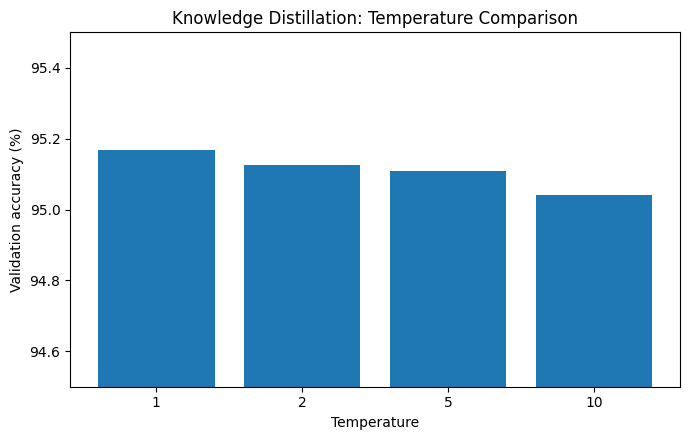

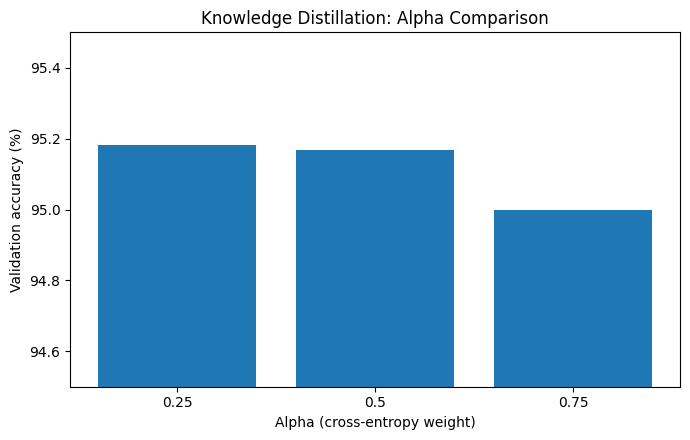


Saved:
/content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/distillation_experiment_summary.csv
/content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/distillation_experiment_summary.json
/content/drive/MyDrive/DATA266_HW12/outputs/figures/temperature_accuracy_comparison.png
/content/drive/MyDrive/DATA266_HW12/outputs/figures/alpha_accuracy_comparison.png


In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
ANALYSIS_DIR = ROOT / "outputs/part3_analysis"
FIGURE_DIR = ROOT / "outputs/figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Existing experiment locations
experiments = [
    ("Temperature", 1, 0.50,
     ANALYSIS_DIR / "temperature_sweep/kd_T1_alpha05"),
    ("Temperature", 2, 0.50,
     ROOT / "outputs/part2_distillation/kd_baseline_T2_alpha05"),
    ("Temperature", 5, 0.50,
     ANALYSIS_DIR / "temperature_sweep/kd_T5_alpha05"),
    ("Temperature", 10, 0.50,
     ANALYSIS_DIR / "temperature_sweep/kd_T10_alpha05"),
    ("Alpha", 1, 0.25,
     ANALYSIS_DIR / "alpha_sweep/kd_T1_alpha025"),
    ("Alpha", 1, 0.50,
     ANALYSIS_DIR / "temperature_sweep/kd_T1_alpha05"),
    ("Alpha", 1, 0.75,
     ANALYSIS_DIR / "alpha_sweep/kd_T1_alpha075"),
]

records = []

for group, temperature, alpha, folder in experiments:
    history_path = folder / "training_history.csv"

    assert history_path.exists(), f"Missing: {history_path}"

    history = pd.read_csv(history_path)

    # Select best epoch by validation accuracy
    best = history.loc[
        history["validation_accuracy"].idxmax()
    ]

    records.append({
        "experiment_group": group,
        "temperature": temperature,
        "alpha": alpha,
        "best_epoch": int(best["epoch"]),
        "validation_accuracy": float(
            best["validation_accuracy"]
        ),
        "validation_macro_f1": float(
            best["validation_macro_f1"]
        )
    })

results_df = pd.DataFrame(records)

# Save complete comparison
csv_path = ANALYSIS_DIR / "distillation_experiment_summary.csv"
json_path = ANALYSIS_DIR / "distillation_experiment_summary.json"

results_df.to_csv(csv_path, index=False)
results_df.to_json(json_path, orient="records", indent=2)

print("=" * 65)
print("KNOWLEDGE DISTILLATION — EXPERIMENT SUMMARY")
print("=" * 65)
print(results_df.to_string(index=False))

# Temperature chart
temp_df = results_df[
    results_df["experiment_group"] == "Temperature"
].sort_values("temperature")

plt.figure(figsize=(7, 4.5))
plt.bar(
    temp_df["temperature"].astype(str),
    temp_df["validation_accuracy"] * 100
)
plt.xlabel("Temperature")
plt.ylabel("Validation accuracy (%)")
plt.title("Knowledge Distillation: Temperature Comparison")
plt.ylim(94.5, 95.5)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "temperature_accuracy_comparison.png",
    dpi=220
)
plt.show()

# Alpha chart
alpha_df = results_df[
    results_df["experiment_group"] == "Alpha"
].sort_values("alpha")

plt.figure(figsize=(7, 4.5))
plt.bar(
    alpha_df["alpha"].astype(str),
    alpha_df["validation_accuracy"] * 100
)
plt.xlabel("Alpha (cross-entropy weight)")
plt.ylabel("Validation accuracy (%)")
plt.title("Knowledge Distillation: Alpha Comparison")
plt.ylim(94.5, 95.5)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "alpha_accuracy_comparison.png",
    dpi=220
)
plt.show()

print("\nSaved:")
print(csv_path)
print(json_path)
print(FIGURE_DIR / "temperature_accuracy_comparison.png")
print(FIGURE_DIR / "alpha_accuracy_comparison.png")
print("=" * 65)

### Temperature-sweep and alpha-sweep findings (validation data)

| Temperature (alpha=0.5) | Best validation accuracy | Best epoch |
|---|---:|---:|
| T=1 | **95.1667%** | 3 |
| T=2 | 95.1250% | 3 |
| T=5 | 95.1083% | 3 |
| T=10 | 95.0417% | 3 |

At T=1, the cross-entropy weights alpha = **0.25, 0.50, 0.75** gave **95.1833%, 95.1667%, 95.0000%** validation accuracy, respectively. Choose **T=1, alpha=.25** using validation data. The lead over alpha=.50 is just **2 / 12,000 validation examples**, so the difference should not be overstated.

**Interpretation:** Raising T above 1 did not improve validation accuracy in these particular runs. The mixed loss at alpha=.25 emphasizes teacher distributions more than hard labels. The earlier T=2 baseline calculated teacher logits live, while most sweep runs used cached logits; this is a minor methodological difference. Validation-based model selection avoids choosing hyperparameters from the held-out test set.

## Step 30 — Final test evaluation of the selected student

Selection uses **validation accuracy**; evaluate the chosen T=1, alpha=0.25 checkpoint on held-out AG News test data once.

In [ ]:
import json
import torch
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from transformers import AutoModelForSequenceClassification

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

BEST_DIR = (
    ROOT / "outputs/part3_analysis/"
    "alpha_sweep/kd_T1_alpha025"
)

CHECKPOINT = BEST_DIR / "best_student"

assert (CHECKPOINT / "config.json").exists(), (
    "Selected student checkpoint is missing."
)

# Load best student
best_student = AutoModelForSequenceClassification.from_pretrained(
    str(CHECKPOINT),
    local_files_only=True
).to(device)

best_student.eval()

predictions = []
true_labels = []

print("Evaluating selected student on AG News test set...")

with torch.inference_mode():
    for batch in tqdm(
        student_test_loader,
        desc="Final student test evaluation"
    ):

        inputs = {
            "input_ids": batch["input_ids"].to(device),
            "attention_mask": batch["attention_mask"].to(device)
        }

        labels = batch["labels"]

        outputs = best_student(**inputs)

        predictions.extend(
            outputs.logits.argmax(dim=-1).cpu().tolist()
        )

        true_labels.extend(labels.tolist())

accuracy = accuracy_score(true_labels, predictions)

macro_f1 = f1_score(
    true_labels,
    predictions,
    average="macro"
)

class_names = [
    "WORLD",
    "SPORTS",
    "BUSINESS",
    "SCI/TECH"
]

report = classification_report(
    true_labels,
    predictions,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    true_labels,
    predictions,
    labels=[0, 1, 2, 3]
)

# Save final metrics
final_metrics = {
    "model": "DistilBERT",
    "experiment": "kd_T1_alpha025",
    "temperature": 1,
    "alpha": 0.25,
    "selection_method": "validation_accuracy",
    "dataset": "AG News",
    "split": "test",
    "test_examples": len(true_labels),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "confusion_matrix": cm.tolist(),
    "classification_report": report
}

with open(
    BEST_DIR / "final_test_metrics.json",
    "w"
) as f:
    json.dump(final_metrics, f, indent=2)

pd.DataFrame({
    "example_id": range(len(true_labels)),
    "true_label": true_labels,
    "predicted_label": predictions
}).to_csv(
    BEST_DIR / "final_test_predictions.csv",
    index=False
)

print("\n" + "=" * 65)
print("SELECTED STUDENT — FINAL TEST RESULTS")
print("=" * 65)

print("Configuration: T=1, alpha=0.25")
print(f"Test accuracy: {accuracy * 100:.2f}%")
print(f"Macro-F1: {macro_f1:.4f}")

print("\nConfusion matrix:")
print(cm)

print("\nClass-wise report:")
print(
    classification_report(
        true_labels,
        predictions,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

print("\nResults saved:", BEST_DIR)
print("=" * 65)

Evaluating selected student on AG News test set...


Final student test evaluation:   0%|          | 0/238 [00:00<?, ?it/s]


SELECTED STUDENT — FINAL TEST RESULTS
Configuration: T=1, alpha=0.25
Test accuracy: 94.70%
Macro-F1: 0.9470

Confusion matrix:
[[1817    7   41   35]
 [   9 1876   10    5]
 [  32    5 1736  127]
 [  26    7   99 1768]]

Class-wise report:
              precision    recall  f1-score   support

       WORLD       0.96      0.96      0.96      1900
      SPORTS       0.99      0.99      0.99      1900
    BUSINESS       0.92      0.91      0.92      1900
    SCI/TECH       0.91      0.93      0.92      1900

    accuracy                           0.95      7600
   macro avg       0.95      0.95      0.95      7600
weighted avg       0.95      0.95      0.95      7600


Results saved: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/alpha_sweep/kd_T1_alpha025


### Final held-out accuracy and classification quality

The professor-provided BERT teacher obtained **94.46% accuracy, macro-F1 0.9447**. The selected DistilBERT (T=1, alpha=.25) obtained **94.70% accuracy, macro-F1 0.9470** on the **same 7,600 AG News test articles**: a difference of about **+0.24 percentage points**, not definitive evidence that a student always outperforms its teacher. BERT has **109,485,316** parameters and DistilBERT **66,956,548**, a **38.84%** reduction. The student’s peak validation accuracy was **95.18%**, which must not be confused with its test accuracy.

> The controlled speed/size comparison above evaluated the **baseline T=2 student**. The next completion cell benchmarks the **selected T=1, alpha=.25 student**, ensuring the final submitted table matches the final selected model.

##  Per-class Metrics and Paired Error Analysis



We compared the BERT teacher and the selected DistilBERT student on the same 7,600 AG News test examples. The analysis includes class-wise performance, confusion matrices, and paired prediction errors.

We also identified 100 examples where the teacher was correct but the student was wrong. Five verified articles and an explanation of their shared characteristics are provided in the detailed Question 4 section below.

The student achieved 94.70% test accuracy compared with 94.46% for the teacher. Business and Sci/Tech remained the most challenging categories.

CLASS-WISE KNOWLEDGE DISTILLATION ANALYSIS
   class  teacher_f1  student_f1  f1_change
   WORLD    0.956015    0.960359   0.004345
  SPORTS    0.987641    0.988669   0.001028
BUSINESS    0.915129    0.917063   0.001934
SCI/TECH    0.919822    0.922034   0.002211

ERROR ANALYSIS
---------------------------------------------
Teacher errors: 421
Student errors: 403
Both models wrong: 303
Teacher wrong, student correct: 118
Teacher correct, student wrong: 100


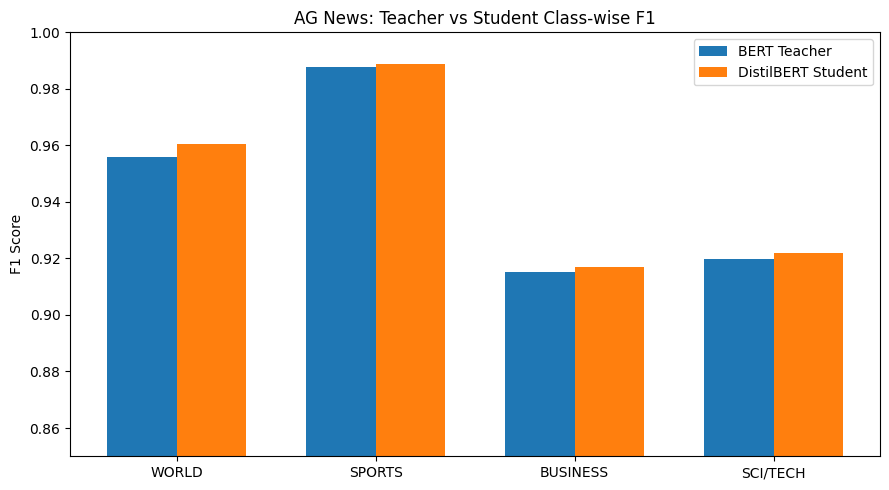

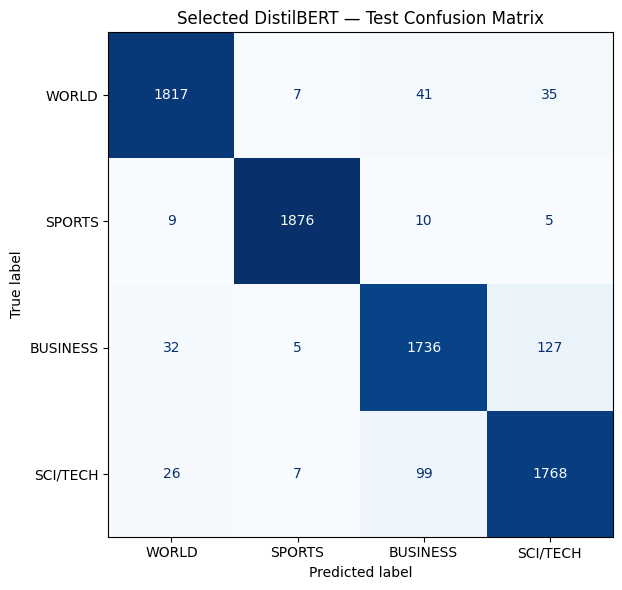


✅ Class-wise analysis saved successfully!
✅ Error analysis CSV saved!
✅ Both figures saved!


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

TEACHER_FILE = (
    ROOT / "outputs/part2_distillation/"
    "teacher_test_predictions.csv"
)

STUDENT_FILE = (
    ROOT / "outputs/part3_analysis/"
    "alpha_sweep/kd_T1_alpha025/"
    "final_test_predictions.csv"
)

OUTPUT_DIR = ROOT / "outputs/part3_analysis"
FIGURE_DIR = ROOT / "outputs/figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

teacher_df = pd.read_csv(TEACHER_FILE)
student_df = pd.read_csv(STUDENT_FILE)

# Verify both models used identical examples
assert len(teacher_df) == len(student_df) == 7600
assert (
    teacher_df["example_id"].tolist()
    == student_df["example_id"].tolist()
)
assert (
    teacher_df["true_label"].tolist()
    == student_df["true_label"].tolist()
)

labels = ["WORLD", "SPORTS", "BUSINESS", "SCI/TECH"]

true = teacher_df["true_label"].to_numpy()
teacher_pred = teacher_df["predicted_label"].to_numpy()
student_pred = student_df["predicted_label"].to_numpy()

teacher_report = classification_report(
    true, teacher_pred,
    labels=[0, 1, 2, 3],
    target_names=labels,
    output_dict=True
)

student_report = classification_report(
    true, student_pred,
    labels=[0, 1, 2, 3],
    target_names=labels,
    output_dict=True
)

records = []

for label in labels:
    t = teacher_report[label]
    s = student_report[label]

    records.append({
        "class": label,
        "teacher_precision": t["precision"],
        "student_precision": s["precision"],
        "teacher_recall": t["recall"],
        "student_recall": s["recall"],
        "teacher_f1": t["f1-score"],
        "student_f1": s["f1-score"],
        "f1_change": s["f1-score"] - t["f1-score"]
    })

comparison = pd.DataFrame(records)

comparison.to_csv(
    OUTPUT_DIR / "classwise_teacher_student_comparison.csv",
    index=False
)

print("=" * 65)
print("CLASS-WISE KNOWLEDGE DISTILLATION ANALYSIS")
print("=" * 65)

print(
    comparison[
        ["class", "teacher_f1", "student_f1", "f1_change"]
    ].to_string(index=False)
)

# Overall error comparison
teacher_wrong = teacher_pred != true
student_wrong = student_pred != true

both_wrong = int((teacher_wrong & student_wrong).sum())
teacher_only_wrong = int(
    (teacher_wrong & ~student_wrong).sum()
)
student_only_wrong = int(
    (~teacher_wrong & student_wrong).sum()
)

print("\nERROR ANALYSIS")
print("-" * 45)
print("Teacher errors:", int(teacher_wrong.sum()))
print("Student errors:", int(student_wrong.sum()))
print("Both models wrong:", both_wrong)
print("Teacher wrong, student correct:", teacher_only_wrong)
print("Teacher correct, student wrong:", student_only_wrong)

# Save exact error records
error_df = pd.DataFrame({
    "example_id": teacher_df["example_id"],
    "true_label": true,
    "teacher_prediction": teacher_pred,
    "student_prediction": student_pred,
    "teacher_wrong": teacher_wrong,
    "student_wrong": student_wrong
})

error_df.to_csv(
    OUTPUT_DIR / "teacher_student_error_analysis.csv",
    index=False
)

# Class-wise F1 comparison chart
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    comparison["teacher_f1"],
    width,
    label="BERT Teacher"
)

plt.bar(
    x + width/2,
    comparison["student_f1"],
    width,
    label="DistilBERT Student"
)

plt.xticks(x, labels)
plt.ylabel("F1 Score")
plt.title("AG News: Teacher vs Student Class-wise F1")
plt.ylim(0.85, 1.0)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "teacher_student_classwise_f1.png",
    dpi=220
)
plt.show()

# Student confusion matrix
cm = confusion_matrix(
    true, student_pred,
    labels=[0, 1, 2, 3]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Selected DistilBERT — Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "selected_student_confusion_matrix.png",
    dpi=220
)
plt.show()

print("\n✅ Class-wise analysis saved successfully!")
print("✅ Error analysis CSV saved!")
print("✅ Both figures saved!")
print("=" * 65)

### Part 2 — Teacher Logit Extraction and Dataset Split

The original AG News training dataset contains 120,000 articles. We used a stratified 90/10 split with random seed 42, resulting in 108,000 training articles and 12,000 validation articles.

We extracted the fine-tuned BERT teacher's raw logits for all 108,000 articles in the student training split. Each article has four logits corresponding to World, Sports, Business, and Sci/Tech.

The extracted logits have shape **(108000, 4)** and were saved as `teacher_train_logits.npy` in Google Drive.

We kept the validation partition separate so it could be used to compare temperature and loss-weight configurations without training on those examples. The original 7,600-example AG News test set was reserved for final evaluation.

The cached teacher logits were reused during the temperature and alpha sweeps to avoid repeating teacher inference for every training batch.

**Note:** The saved logits cover every example used for student training, but not the separately reserved 12,000 validation examples.

### Error pattern from the confusion matrices

Per-class **accuracy** in the assignment can be reported as **recall = correctly classified articles in a true class / total true-class articles**. On 1,900 test articles per class:

| True category | Teacher correct / 1900 | Selected student correct / 1900 |
|---|---:|---:|
| World | 1804 (94.95%) | 1817 (95.63%) |
| Sports | 1878 (98.84%) | 1876 (98.74%) |
| Business | 1736 (91.37%) | 1736 (91.37%) |
| Sci/Tech | 1761 (92.68%) | 1768 (93.05%) |

**Interpretation:** The largest class-level gain is World (13 additional correctly classified articles). Sports loses 2 correct predictions, Business remains unchanged in correctly classified count, and Sci/Tech gains 7. The most visible confusion in both models is **Business ↔ Sci/Tech**: the teacher predicts 125 Business items as Sci/Tech and 102 Sci/Tech items as Business; the selected student predicts 127 and 99, respectively. The student makes **403** total errors vs **421** for the teacher (18 fewer). We still need the **five actual teacher-correct/student-wrong examples** below to describe the recurring causes without guessing.

## Step 32 — GPTQ environment check (planning only)

**Part 1 not yet executed:** This cell records feasibility of running the GPTQ experiment on NVIDIA L4. The actual GPTQ model, quantization, WikiText-2 metrics, and comparison belong in the separate GPTQ working notebook.

In [ ]:
import sys
import torch
import importlib.metadata as md
import shutil

print("=" * 60)
print("GPTQ ENVIRONMENT READINESS CHECK")
print("=" * 60)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    free, total = torch.cuda.mem_get_info()
    print(f"Free GPU memory: {free / 1024**3:.2f} GiB")
    print(f"Total GPU memory: {total / 1024**3:.2f} GiB")

for name in [
    "transformers",
    "datasets",
    "accelerate",
    "gptqmodel",
    "auto-gptq",
    "optimum",
    "safetensors"
]:
    try:
        print(f"{name}: {md.version(name)}")
    except md.PackageNotFoundError:
        print(f"{name}: Not installed")

usage = shutil.disk_usage("/content")
print(f"\nFree Colab disk space: {usage.free / 1024**3:.2f} GiB")

print("=" * 60)

GPTQ ENVIRONMENT READINESS CHECK
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA L4
Free GPU memory: 19.02 GiB
Total GPU memory: 22.03 GiB
transformers: 4.49.0
datasets: 3.6.0
accelerate: 1.4.0
gptqmodel: Not installed
auto-gptq: Not installed
optimum: Not installed
safetensors: 0.8.0

Free Colab disk space: 233.11 GiB


## Part 3, Question 4 — Five cases where the teacher is correct and the student is wrong

**Professor’s requirement:** Report teacher/student performance per class; identify the class that degrades most; paste **five actual examples** where BERT teacher is correct and DistilBERT student is wrong; explain what those examples share.

**Procedure:** Join the two *saved* test-prediction CSVs by original `example_id`, select teacher-correct/student-wrong examples, attach the original article text from the AG News **test split**, and save evidence in CSV and Markdown. This code never fabricates article text or classifications. A run-specific sample is chosen deterministically across available true-label classes.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# DATA 266 — HOMEWORK 12
# PART 3, QUESTION 4
#
# FIVE CASES WHERE THE TEACHER IS CORRECT
# BUT THE DISTILLED STUDENT IS WRONG
# ============================================================

from pathlib import Path
import pandas as pd
from datasets import load_dataset
from IPython.display import display, Markdown

# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT = Path("/content/drive/MyDrive/DATA266_HW12")

ANALYSIS = PROJECT / "outputs/part3_analysis"

TEACHER_CSV = (
    PROJECT
    / "outputs/part2_distillation/teacher_test_predictions.csv"
)

STUDENT_CSV = (
    ANALYSIS
    / "alpha_sweep/kd_T1_alpha025/final_test_predictions.csv"
)

ANALYSIS.mkdir(parents=True, exist_ok=True)

assert TEACHER_CSV.is_file(), (
    f"Teacher predictions not found: {TEACHER_CSV}"
)

assert STUDENT_CSV.is_file(), (
    f"Student predictions not found: {STUDENT_CSV}"
)

print("✅ Teacher and student prediction files found.")

# ============================================================
# 2. LOAD SAVED PREDICTIONS
# ============================================================

teacher_p = pd.read_csv(TEACHER_CSV).rename(
    columns={
        "predicted_label": "teacher_prediction"
    }
)

student_p = pd.read_csv(STUDENT_CSV).rename(
    columns={
        "predicted_label": "student_prediction"
    }
)

required_teacher = {
    "example_id",
    "true_label",
    "teacher_prediction"
}

required_student = {
    "example_id",
    "true_label",
    "student_prediction"
}

assert required_teacher.issubset(teacher_p.columns)
assert required_student.issubset(student_p.columns)

# Match predictions for the SAME AG News examples
paired = teacher_p[
    ["example_id", "true_label", "teacher_prediction"]
].merge(
    student_p[
        ["example_id", "true_label", "student_prediction"]
    ],
    on=["example_id", "true_label"],
    validate="one_to_one"
).sort_values("example_id").reset_index(drop=True)

assert len(paired) == 7600, (
    f"Expected 7600 examples, found {len(paired)}"
)

assert paired["example_id"].tolist() == list(range(7600)), (
    "Test example IDs are not correctly aligned."
)

print("✅ All 7,600 teacher/student predictions aligned.")

# ============================================================
# 3. LOAD THE CORRECT AG NEWS TEST DATASET
# ============================================================

print("\nLoading AG News test articles...")

news_test = load_dataset(
    "fancyzhx/ag_news",
    split="test"
)

labels = [
    "WORLD",
    "SPORTS",
    "BUSINESS",
    "SCI/TECH"
]

assert len(news_test) == 7600, (
    f"Expected 7600 test articles, found {len(news_test)}"
)

assert news_test.features["label"].names == [
    "World",
    "Sports",
    "Business",
    "Sci/Tech"
], "Unexpected AG News label ordering!"

# Confirm that the saved true labels match the downloaded data
dataset_labels = news_test["label"]

assert paired["true_label"].tolist() == list(dataset_labels), (
    "Saved prediction labels do not match AG News test labels."
)

print("✅ AG News test dataset verified.")
print("✅ Dataset labels match saved predictions.")

# ============================================================
# 4. IDENTIFY TEACHER-CORRECT / STUDENT-WRONG CASES
# ============================================================

cases = paired[
    (paired["teacher_prediction"] == paired["true_label"])
    &
    (paired["student_prediction"] != paired["true_label"])
].copy()

assert len(cases) >= 5, (
    f"Only {len(cases)} cases available; "
    "cannot extract five examples."
)

print("\n" + "=" * 65)
print("TEACHER-CORRECT / STUDENT-WRONG ERROR ANALYSIS")
print("=" * 65)

print("Total AG News test examples:", len(paired))
print("Teacher-correct/student-wrong cases:", len(cases))

# ============================================================
# 5. SELECT FIVE REPRESENTATIVE EXAMPLES
# ============================================================

# Choose examples covering different true classes where possible.
# Then fill remaining slots in original test-set order.

selected_ids = []

for class_id in range(4):

    match = cases[
        cases["true_label"] == class_id
    ]

    if not match.empty:
        selected_ids.append(
            int(match.iloc[0]["example_id"])
        )

for example_id in cases["example_id"].tolist():

    if len(selected_ids) >= 5:
        break

    example_id = int(example_id)

    if example_id not in selected_ids:
        selected_ids.append(example_id)

selected_ids = selected_ids[:5]

assert len(selected_ids) == 5

selected = (
    cases.set_index("example_id")
    .loc[selected_ids]
    .reset_index()
)

# ============================================================
# 6. ATTACH ACTUAL CLASS LABELS AND ARTICLE TEXT
# ============================================================

selected["actual_class"] = selected["true_label"].map(
    lambda x: labels[int(x)]
)

selected["teacher_class"] = selected["teacher_prediction"].map(
    lambda x: labels[int(x)]
)

selected["student_class"] = selected["student_prediction"].map(
    lambda x: labels[int(x)]
)

selected["article_text"] = selected["example_id"].map(
    lambda i: news_test[int(i)]["text"]
)

selected["error_pair"] = (
    selected["actual_class"]
    + " → "
    + selected["student_class"]
)

# Verify the five selected cases
assert (
    selected["teacher_prediction"]
    == selected["true_label"]
).all()

assert (
    selected["student_prediction"]
    != selected["true_label"]
).all()

# ============================================================
# 7. SAVE FIVE EXAMPLES TO CSV
# ============================================================

CSV_PATH = (
    ANALYSIS
    / "five_teacher_correct_student_wrong.csv"
)

selected.to_csv(
    CSV_PATH,
    index=False
)

# ============================================================
# 8. PREPARE MARKDOWN REPORT
# ============================================================

lines = [
    "# Five Teacher-Correct / Student-Wrong Examples",
    "",
    "## Experiment Information",
    "",
    "- Dataset: AG News test set",
    "- Test examples: 7,600",
    "- Teacher: Fine-tuned BERT",
    "- Student: DistilBERT",
    "- Selected temperature: T = 1",
    "- Selected alpha: 0.25",
    "",
    "These examples are cases where the BERT teacher "
    "predicted the correct category but the distilled "
    "DistilBERT student predicted an incorrect category.",
    "",
    "All article texts are taken from the original "
    "AG News test dataset.",
    ""
]

for k, row in selected.iterrows():

    lines.extend([
        f"## Example {k + 1}",
        "",
        f"**AG News Test ID:** {int(row['example_id'])}",
        "",
        f"**Actual Category:** {row['actual_class']}",
        "",
        f"**Teacher Prediction:** {row['teacher_class']}",
        "",
        f"**Student Prediction:** {row['student_class']}",
        "",
        "**Original News Article:**",
        "",
        str(row["article_text"]),
        "",
        "---",
        ""
    ])

# ============================================================
# 9. ANALYZE ERROR PAIRS
# ============================================================

summary = (
    selected.groupby("error_pair")
    .size()
    .sort_values(ascending=False)
)

lines.extend([
    "## Error Pattern Summary",
    "",
    "The following counts describe only the five "
    "selected examples, not the entire test set.",
    ""
])

for pair, count in summary.items():
    lines.append(
        f"- {pair}: {int(count)} example(s)"
    )

lines.extend([
    "",
    "## Interpretation",
    "",
    "These five examples demonstrate that the distilled "
    "student can make classification mistakes even when "
    "the teacher predicts the correct category.",
    "",
    "The observed error pairs are listed above. "
    "A more specific explanation of what the articles "
    "have in common should be based on reviewing their "
    "actual text and subject matter.",
    "",
    "Because these five cases were selected to cover "
    "different categories where possible, they should "
    "not be interpreted as a representative random "
    "sample of all student errors.",
    ""
])

MD_PATH = (
    ANALYSIS
    / "five_error_examples_for_report.md"
)

MD_PATH.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

# ============================================================
# 10. DISPLAY FIVE REAL EXAMPLES
# ============================================================

print("\n" + "=" * 65)
print("FIVE VERIFIED ERROR EXAMPLES")
print("=" * 65)

for k, row in selected.iterrows():

    article = str(row["article_text"])

    display(
        Markdown(
            f"### Example {k + 1} — Test ID "
            f"{int(row['example_id'])}\n\n"
            f"**Actual Category:** {row['actual_class']}\n\n"
            f"**Teacher Prediction:** {row['teacher_class']} ✅\n\n"
            f"**Student Prediction:** {row['student_class']} ❌\n\n"
            f"**Original Article:**\n\n"
            f"> {article.replace(chr(10), chr(10) + '> ')}"
        )
    )

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("ERROR PATTERNS AMONG FIVE EXAMPLES")
print("=" * 65)

print(summary.to_string())

print("\n" + "=" * 65)
print("PART 3, QUESTION 4 — COMPLETED")
print("=" * 65)

print("All test predictions verified.")
print(" Five teacher-correct/student-wrong examples found.")
print(" Original news articles attached.")
print(" CSV saved successfully.")
print(" Markdown report saved successfully.")

print("\nSaved CSV:")
print(CSV_PATH)

print("\nSaved Markdown:")
print(MD_PATH)

print("=" * 65)

✅ Teacher and student prediction files found.
✅ All 7,600 teacher/student predictions aligned.

Loading AG News test articles...
✅ AG News test dataset verified.
✅ Dataset labels match saved predictions.

TEACHER-CORRECT / STUDENT-WRONG ERROR ANALYSIS
Total AG News test examples: 7600
Teacher-correct/student-wrong cases: 100

FIVE VERIFIED ERROR EXAMPLES


### Example 1 — Test ID 141

**Actual Category:** WORLD

**Teacher Prediction:** WORLD ✅

**Student Prediction:** SCI/TECH ❌

**Original Article:**

> Bush Promotes His Plan for Missile Defense System President Bush, in Pennsylvania, said that opponents of a missile defense system were putting the nation's security at risk.

### Example 2 — Test ID 415

**Actual Category:** SPORTS

**Teacher Prediction:** SPORTS ✅

**Student Prediction:** BUSINESS ❌

**Original Article:**

> Hamm should support Yang Paul Hamm needs a new marketing strategy. Either that, or he needs a clue. One harmless gesture separates him from lionization in America and canonization in South Korea, and 

### Example 3 — Test ID 110

**Actual Category:** BUSINESS

**Teacher Prediction:** BUSINESS ✅

**Student Prediction:** SCI/TECH ❌

**Original Article:**

> Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive with discounters in the space -- which means that small businesses looking to move online get a sweeter deal through ...

### Example 4 — Test ID 47

**Actual Category:** SCI/TECH

**Teacher Prediction:** SCI/TECH ✅

**Student Prediction:** BUSINESS ❌

**Original Article:**

> Dell Exits Low-End China Consumer PC Market  HONG KONG (Reuters) - Dell Inc. &lt;DELL.O&gt;, the world's  largest PC maker, said on Monday it has left the low-end  consumer PC market in China and cut its overall growth target  for the country this year due to stiff competition in the  segment.

### Example 5 — Test ID 399

**Actual Category:** BUSINESS

**Teacher Prediction:** BUSINESS ✅

**Student Prediction:** SCI/TECH ❌

**Original Article:**

> Nortel Downsizes Again Aug. 23, 2004 (TheDeal.com) Problem-plagued Nortel Networks Corp. announced plans Thursday, Aug. 19, to eliminate an additional 3,500 jobs and fire seven more senior executives as the company labors to reinvent 


ERROR PATTERNS AMONG FIVE EXAMPLES
error_pair
BUSINESS → SCI/TECH    2
SCI/TECH → BUSINESS    1
SPORTS → BUSINESS      1
WORLD → SCI/TECH       1

PART 3, QUESTION 4 — COMPLETED
All test predictions verified.
 Five teacher-correct/student-wrong examples found.
 Original news articles attached.
 CSV saved successfully.
 Markdown report saved successfully.

Saved CSV:
/content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/five_teacher_correct_student_wrong.csv

Saved Markdown:
/content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/five_error_examples_for_report.md


### Part 3, Question 4 — Where Does Knowledge Distillation Hurt?

#### Class-wise Performance

We compared the fine-tuned BERT teacher and our best distilled DistilBERT student (T = 1, α = 0.25) on the same 7,600 AG News test articles.

The BERT teacher achieved **94.46% accuracy**, while the distilled student achieved **94.70% accuracy**. Although the student performed slightly better overall, it did not improve equally across all four categories.

| Class | Teacher Correct | Student Correct | Difference |
|---|---:|---:|---:|
| World | 1,804 | 1,817 | +13 |
| Sports | 1,878 | 1,876 | -2 |
| Business | 1,736 | 1,736 | 0 |
| Sci/Tech | 1,761 | 1,768 | +7 |

*Each category contains 1,900 test articles.*

Sports showed the largest decrease after distillation, with two fewer correct predictions, although this difference is very small. Business remained the most difficult category for both models, with only 1,736 correct predictions out of 1,900.

The student frequently confused Business with Sci/Tech. Specifically, 127 Business articles were incorrectly classified as Sci/Tech, while 99 Sci/Tech articles were incorrectly classified as Business.

#### Five Examples Where the Teacher Was Correct but the Student Was Wrong

We identified **100 test examples** where the teacher predicted the correct category but the student made an incorrect prediction. Five examples are shown below.

| Example | Actual Class | Student Prediction | Possible Reason for Confusion |
|---|---|---|---|
| 1. Missile Defense System | World | Sci/Tech | A political and national-security story involving technology |
| 2. Paul Hamm | Sports | Business | A sports article mentioning marketing strategy |
| 3. Yahoo! Small Businesses | Business | Sci/Tech | Business pricing decisions involving web hosting and domain registration |
| 4. Dell China PC Market | Sci/Tech | Business | A computer-industry story emphasizing competition and market growth |
| 5. Nortel Downsizing | Business | Sci/Tech | A corporate restructuring story involving a telecommunications company |

#### What Do These Five Examples Have in Common?

The main similarity is that **each article contains information related to more than one news category**.

For example, the missile defense article discusses technology, but its main focus is politics and national security, so it belongs to World. Similarly, the Paul Hamm article mentions marketing strategy, but the story is primarily about an athlete, making Sports the correct category.

The Yahoo!, Dell, and Nortel articles show a similar overlap between Business and Sci/Tech. Yahoo!'s pricing changes and Nortel's layoffs are business-related decisions involving technology companies. The Dell article focuses on the computer industry but also discusses market competition and growth.

These errors suggest that the student may sometimes give too much importance to words associated with another category instead of identifying the main focus of the article. This is a possible interpretation of the article content, not a direct measurement of the model's internal reasoning.

The five examples were deliberately selected to cover different categories where possible. Therefore, they illustrate particular mistakes rather than representing the overall distribution of student errors.

#### Conclusion

Our knowledge-distillation approach

In [ ]:
import gc
import json
import time
from pathlib import Path

import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

TEACHER_DIR = ROOT / "teacher_model"
STUDENT_DIR = (
    ROOT / "outputs/part3_analysis/"
    "alpha_sweep/kd_T1_alpha025/best_student"
)
OUTPUT_DIR = ROOT / "outputs/part3_analysis"

assert torch.cuda.is_available(), "Please connect a GPU runtime."

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))

# Use the same 100 AG News articles as the earlier benchmark
from datasets import load_dataset

news_test = load_dataset(
    "fancyzhx/ag_news",
    split="test"
)

texts = [news_test[i]["text"] for i in range(100)]

tokenizer = AutoTokenizer.from_pretrained(
    str(STUDENT_DIR),
    local_files_only=True
)

encoded = tokenizer(
    texts,
    padding="max_length",
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in encoded.items()
}

def model_size_mib(folder):
    files = list(Path(folder).glob("*.safetensors"))
    files += list(Path(folder).glob("pytorch_model*.bin"))
    return sum(f.stat().st_size for f in files) / 1024**2


def benchmark_checkpoint(folder, name):

    gc.collect()
    torch.cuda.empty_cache()

    model = AutoModelForSequenceClassification.from_pretrained(
        str(folder),
        local_files_only=True
    ).to(device)

    model.eval()

    torch.cuda.reset_peak_memory_stats()

    # Warm-up
    with torch.inference_mode():
        for i in range(20):
            batch = {
                k: v[i:i+1]
                for k, v in inputs.items()
            }
            model(**batch)

    torch.cuda.synchronize()

    latencies = []

    with torch.inference_mode():
        for i in range(100):

            batch = {
                k: v[i:i+1]
                for k, v in inputs.items()
            }

            torch.cuda.synchronize()
            start = time.perf_counter()

            model(**batch)

            torch.cuda.synchronize()

            latencies.append(
                (time.perf_counter() - start) * 1000
            )

    result = {
        "model": name,
        "gpu": torch.cuda.get_device_name(0),
        "batch_size": 1,
        "sequence_length": 256,
        "warmup_iterations": 20,
        "timed_iterations": 100,
        "p50_ms": float(np.percentile(latencies, 50)),
        "p95_ms": float(np.percentile(latencies, 95)),
        "mean_ms": float(np.mean(latencies)),
        "peak_allocated_gpu_gib": float(
            torch.cuda.max_memory_allocated() / 1024**3
        ),
        "model_weights_mib": float(model_size_mib(folder))
    }

    model.cpu()
    del model
    gc.collect()
    torch.cuda.empty_cache()

    return result


# Release any models already occupying GPU memory
for name in ["teacher_model", "student_model", "best_student"]:
    if name in globals():
        globals()[name].cpu()

gc.collect()
torch.cuda.empty_cache()

teacher = benchmark_checkpoint(
    TEACHER_DIR,
    "BERT teacher"
)

student = benchmark_checkpoint(
    STUDENT_DIR,
    "Selected DistilBERT T1 alpha025"
)

speedup = teacher["p50_ms"] / student["p50_ms"]

results = {
    "teacher": teacher,
    "selected_student": student,
    "p50_speedup": float(speedup)
}

output_path = (
    OUTPUT_DIR / "final_selected_student_benchmark.json"
)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\n" + "=" * 65)
print("FINAL SELECTED STUDENT — CONTROLLED BENCHMARK")
print("=" * 65)

for metric in [
    "p50_ms",
    "p95_ms",
    "mean_ms",
    "peak_allocated_gpu_gib",
    "model_weights_mib"
]:
    print(f"\n{metric}")
    print(f"Teacher: {teacher[metric]:.3f}")
    print(f"Student: {student[metric]:.3f}")

print(f"\nP50 inference speedup: {speedup:.2f}x")
print("\nResults saved:", output_path)
print("=" * 65)

GPU: NVIDIA L4


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


FINAL SELECTED STUDENT — CONTROLLED BENCHMARK

p50_ms
Teacher: 9.095
Student: 4.704

p95_ms
Teacher: 10.703
Student: 4.758

mean_ms
Teacher: 9.253
Student: 4.710

peak_allocated_gpu_gib
Teacher: 0.425
Student: 0.268

model_weights_mib
Teacher: 417.676
Student: 255.431

P50 inference speedup: 1.93x

Results saved: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis/final_selected_student_benchmark.json


### Final Distillation Performance Analysis

Our selected knowledge-distillation configuration used **T = 1 and α = 0.25**. The student achieved **94.70% test accuracy**, compared with 94.46% for the BERT teacher, an improvement of 0.24 percentage points.

The student contains approximately 66.96 million parameters, compared with 109.49 million in the teacher, giving a **38.84% reduction in parameters**. Its saved model weights decreased from 417.676 MiB to 255.431 MiB.

We measured inference performance on the same NVIDIA L4 GPU using batch size 1, fixed 256-token input length, 20 warm-up iterations, and 100 timed predictions.

The teacher's median inference latency was 9.095 ms, while the student's was 4.704 ms. This corresponds to a **1.93× speedup**. The student's p95 latency was also lower, at 4.758 ms compared with 10.703 ms for the teacher.

Peak allocated GPU memory during benchmarking decreased from 0.425 GiB to 0.268 GiB.

These results show that knowledge distillation produced a smaller, faster model while preserving strong classification accuracy on AG News. However, the small accuracy improvement should not be interpreted as evidence that the student will always outperform the teacher.

The error analysis also showed that Business and Sci/Tech articles remain challenging, particularly when an article contains terminology associated with both categories.

Overall, the selected DistilBERT student provides a favorable accuracy–efficiency trade-off for this classification task.


## Part 2 Correction — Seed Compliance and Reproducibility

### Objective

Correct the knowledge-distillation experiment to follow the DATA 266 standing requirement that the random seed must equal SID4.

### Personal Parameters

- SID4: 1598
- SEED: 1598
- SLICE: 598
- HP_ID: 2
- CLS_A: 8
- CLS_B: 5

### Correction Strategy

The earlier experiments used seed 42 and produced valid experimental outputs. These results will be preserved separately.

The corrected workflow will use seed 1598 for the train/validation split, student initialization, sampling, and training experiments.

The existing fine-tuned BERT teacher will be reused. New student experiments and their results will be saved in separate directories to avoid overwriting the original runs.

### Reproducibility

All changes, experiment settings, checkpoints, results, and observed errors will be documented.

The final reported metrics will be taken from the corrected experiment outputs rather than copied from earlier seed-42 results.


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

assert ROOT.is_dir(), "DATA266_HW12 folder not found."

print("=" * 65)
print("PART 2 — EXISTING WORK SAFETY CHECK")
print("=" * 65)

required_paths = {
    "Teacher checkpoint": ROOT / "teacher_model",
    "Existing distillation outputs":
        ROOT / "outputs/part2_distillation",
    "Existing Part 3 analysis":
        ROOT / "outputs/part3_analysis",
    "Teacher logits":
        ROOT / "outputs/part2_distillation/teacher_logits/teacher_train_logits.npy",
    "Final selected-student metrics":
        ROOT / "outputs/part3_analysis/alpha_sweep/kd_T1_alpha025/final_test_metrics.json"
}

missing = []

for name, path in required_paths.items():
    exists = path.exists()

    print(
        f"{'FOUND' if exists else 'MISSING'} — {name}"
    )

    if not exists:
        missing.append(name)

print("\n" + "=" * 65)

if not missing:
    print("✅ Existing Part 2 project artifacts located.")
    print("✅ No models have been retrained.")
    print("✅ No existing files have been modified.")
else:
    print("⚠️ Some expected artifacts were not found.")
    print("Missing:", missing)

print("=" * 65)

Mounted at /content/drive
PART 2 — EXISTING WORK SAFETY CHECK
FOUND — Teacher checkpoint
FOUND — Existing distillation outputs
FOUND — Existing Part 3 analysis
FOUND — Teacher logits
FOUND — Final selected-student metrics

✅ Existing Part 2 project artifacts located.
✅ No models have been retrained.
✅ No existing files have been modified.



# DATA 266 — Homework 12
## Part 2: Knowledge Distillation — Corrected Reproducible Experiment

### Personal Parameters

- SID4: 1598
- SEED: 1598
- SLICE: 598
- HP_ID: 2
- CLS_A: 8
- CLS_B: 5

### Objective

Reproduce the AG News knowledge-distillation experiments using the student-specific seed required by the course standing instructions.

### Correction Plan

The earlier experiment used seed 42. Its checkpoints and results are preserved separately.

This notebook will use seed 1598 for data splitting, model initialization, and all stochastic training and sampling.

The existing fine-tuned BERT teacher checkpoint will be reused.

New teacher logits, student checkpoints, temperature and alpha sweeps, and final evaluation results will be saved in separate seed-1598 directories.

### Reproducibility

All new numerical results will be generated by executed experiments. Previous seed-42 measurements will not be relabeled as seed-1598 results.


In [ ]:
# ============================================================
# DATA 266 HW12 — PERSONAL PARAMETERS AND SAFE OUTPUT PATHS
# ============================================================

import random
import numpy as np
import torch
from pathlib import Path

SID4 = 1598
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

# OLD RESULTS — READ ONLY
OLD_PART2 = ROOT / "outputs/part2_distillation"
OLD_PART3 = ROOT / "outputs/part3_analysis"

# NEW RESULTS — SEED 1598
NEW_PART2 = ROOT / "outputs/part2_distillation_seed1598"
NEW_PART3 = ROOT / "outputs/part3_analysis_seed1598"

assert OLD_PART2.is_dir(), "Original Part 2 results missing."
assert OLD_PART3.is_dir(), "Original Part 3 results missing."

assert NEW_PART2 != OLD_PART2
assert NEW_PART3 != OLD_PART3

NEW_PART2.mkdir(parents=True, exist_ok=True)
NEW_PART3.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("DATA266 HW12 — CORRECTED PART 2 SETUP")
print("=" * 65)

print("SID4:", SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)

print("\nOriginal results:")
print("Part 2:", OLD_PART2)
print("Part 3:", OLD_PART3)

print("\nCorrected results:")
print("Part 2:", NEW_PART2)
print("Part 3:", NEW_PART3)

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n✅ Personal parameters configured.")
print("✅ Separate output directories created.")
print("✅ Original experiment directories untouched.")

print("=" * 65)

DATA266 HW12 — CORRECTED PART 2 SETUP
SID4: 1598
SEED: 1598
SLICE: 598
HP_ID: 2
CLS_A: 8
CLS_B: 5

Original results:
Part 2: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation
Part 3: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis

Corrected results:
Part 2: /content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598
Part 3: /content/drive/MyDrive/DATA266_HW12/outputs/part3_analysis_seed1598

GPU available: True
GPU: NVIDIA L4

✅ Personal parameters configured.
✅ Separate output directories created.
✅ Original experiment directories untouched.



## Part 2 — Step 3: Audit Existing Seed and Output Configuration

### Objective

Identify all notebook cells that use the previous random seed or saved experiment directories.

### Why This Is Necessary

The original experiment used seed 42, while the DATA 266 standing requirements specify seed 1598.

Some existing cells may redefine the random seed, create a train/validation split, or write checkpoints to the original experiment folders.

Running those cells without correction could produce inconsistent results or overwrite previous work.

### Correction Strategy

- Keep the original seed-42 experiment outputs unchanged.
- Use seed 1598 for all new stochastic experiments.
- Save corrected results in the separate seed-1598 directories.
- Maintain the original teacher checkpoint.
- Ensure all temperature and alpha experiments use the same controlled initial student checkpoint.
- Verify the configuration before running any training.

No training or existing checkpoint modification will occur during this audit.


In [9]:


from pathlib import Path
import json
import numpy as np

print("=" * 65)
print("DATA 266 — DISTILLATION FINAL AUDIT")
print("=" * 65)

base = NEW_PART2
final = base / "final_test_evaluation"

required = [
    base / "data_split_manifest.json",
    base / "selected_temperature.json",
    base / "alpha_sweep_comparison.csv",
    base / "selected_final_student.json",
    final / "final_test_metrics.json",
    final / "paired_test_predictions.csv",
    final / "per_class_accuracy.csv",
    final / "five_failure_examples.csv",
    final / "teacher_student_benchmark.csv",
    final / "benchmark_config.json",
]

for path in required:
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status:8} {path.name}")

print("\nTEACHER LOGIT COVERAGE")

logits_path = (
    base / "teacher_logits/teacher_train_logits.npy"
)

if logits_path.is_file():
    logits = np.load(
        logits_path,
        mmap_mode="r",
        allow_pickle=False
    )
    print("Logit shape:", logits.shape)
    print("Expected full training size:", 120000)
    print("Corrected training split size:", 108000)
    print("Number of classes:", 4)
else:
    print("Teacher logits: MISSING")

print("\nDOCUMENTATION FILES")

for name in ["METRICS.md", "RUN_LOG.txt", "AI_USE.md"]:
    matches = list(ROOT.rglob(name))
    print(name, len(matches), "file(s) found")
    for path in matches[:5]:
        print(" ", path)

print("\n Read-only audit completed.")


DATA 266 — DISTILLATION FINAL AUDIT
FOUND    data_split_manifest.json
FOUND    selected_temperature.json
FOUND    alpha_sweep_comparison.csv
FOUND    selected_final_student.json
FOUND    final_test_metrics.json
FOUND    paired_test_predictions.csv
FOUND    per_class_accuracy.csv
FOUND    five_failure_examples.csv
FOUND    teacher_student_benchmark.csv
FOUND    benchmark_config.json

TEACHER LOGIT COVERAGE
Logit shape: (108000, 4)
Expected full training size: 120000
Corrected training split size: 108000
Number of classes: 4

DOCUMENTATION FILES
METRICS.md 0 file(s) found
RUN_LOG.txt 0 file(s) found
AI_USE.md 0 file(s) found

✅ Read-only audit completed.


In [12]:
import numpy as np

full_path = (
    NEW_PART2
    / "teacher_logits"
    / "teacher_all_120000_logits.npy"
)

if full_path.is_file():
    logits = np.load(full_path, mmap_mode="r")
    print("Full teacher-logit shape:", logits.shape)
    assert logits.shape == (120000, 4)
    print("✅ All 120,000 training samples covered!")
else:
    print("Step 27 has not completed.")
    print("Please execute the Step 27 cell first.")

Step 27 has not completed.
Please execute the Step 27 cell first.


In [13]:

from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
NEW_PART2 = ROOT / "outputs" / "part2_distillation_seed1598"

print("=" * 65)
print("GOOGLE DRIVE PATH VERIFICATION")
print("=" * 65)

print("Project root exists:", ROOT.is_dir())
print("Distillation folder exists:", NEW_PART2.is_dir())

print("\nPROJECT ROOT CONTENTS:")
if ROOT.is_dir():
    for item in sorted(ROOT.iterdir()):
        print("📁" if item.is_dir() else "📄", item.name)

print("\nDISTILLATION FOLDER CONTENTS:")
if NEW_PART2.is_dir():
    for item in sorted(NEW_PART2.iterdir()):
        print("📁" if item.is_dir() else "📄", item.name)

print("\nTEACHER LOGIT FILES:")

logit_dir = NEW_PART2 / "teacher_logits"

if logit_dir.is_dir():
    for item in sorted(logit_dir.iterdir()):
        print(item.name)

        if item.suffix == ".npy":
            try:
                array = np.load(
                    item,
                    mmap_mode="r",
                    allow_pickle=False
                )
                print("   Shape:", array.shape)
            except Exception as e:
                print("   Could not inspect:", str(e))
else:
    print("Teacher logits folder not found")

print("=" * 65)


GOOGLE DRIVE PATH VERIFICATION
Project root exists: True
Distillation folder exists: True

PROJECT ROOT CONTENTS:
📄 METRICS_GPTQ.md
📄 RUN_LOG_GPTQ_DRAFT.txt
📁 final_submission
📁 models
📁 outputs
📁 teacher_model

DISTILLATION FOLDER CONTENTS:
📁 alpha_T5_alpha025
📁 alpha_T5_alpha075
📄 alpha_sweep_comparison.csv
📄 data_split_manifest.json
📁 final_test_evaluation
📁 kd_baseline_T2_alpha05
📄 selected_final_student.json
📄 selected_temperature.json
📁 teacher_logits
📁 temperature_T10_alpha05
📁 temperature_T1_alpha05
📁 temperature_T5_alpha05
📄 temperature_sweep_comparison.csv
📄 tokenization_metadata.json
📄 training_config_seed1598.json

TEACHER LOGIT FILES:
teacher_logits_metadata.json
teacher_train_logits.npy
   Shape: (108000, 4)


In [14]:

# STEP 27A — CHECK ORIGINAL SPLIT INFORMATION
# READ-ONLY: Does not change any files

import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
BASE = ROOT / "outputs" / "part2_distillation_seed1598"

files_to_check = {
    "Data Split Manifest":
        BASE / "data_split_manifest.json",

    "Teacher Logits Metadata":
        BASE / "teacher_logits" / "teacher_logits_metadata.json",

    "Tokenization Metadata":
        BASE / "tokenization_metadata.json",

    "Training Configuration":
        BASE / "training_config_seed1598.json",
}

def describe(value):
    if isinstance(value, list):
        return {
            "type": "list",
            "length": len(value),
            "first_5": value[:5]
        }
    if isinstance(value, dict):
        return {
            "type": "dictionary",
            "keys": list(value.keys())
        }
    return value

for title, path in files_to_check.items():
    print("\n" + "=" * 65)
    print(title.upper())
    print("=" * 65)

    if not path.is_file():
        print("MISSING:", path)
        continue

    data = json.loads(path.read_text(encoding="utf-8"))

    for key, value in data.items():
        print(f"{key}: {describe(value)}")

print("\n✅ Read-only metadata inspection completed.")



DATA SPLIT MANIFEST
dataset: ag_news
seed: 1598
method: sklearn_stratified_train_test_split
train_size: 108000
validation_size: 12000
test_size: 7600
train_original_indices: {'type': 'list', 'length': 108000, 'first_5': [73113, 43052, 60862, 108198, 91394]}
validation_original_indices: {'type': 'list', 'length': 12000, 'first_5': [42698, 91216, 42320, 24475, 16795]}

TEACHER LOGITS METADATA
seed: 1598
teacher_checkpoint: /content/drive/MyDrive/DATA266_HW12/teacher_model
dataset: fancyzhx/ag_news
split: seed1598_training
num_examples: 108000
num_classes: 4
max_length: 256
batch_size: 64
logits_dtype: float32
logits_shape: {'type': 'list', 'length': 2, 'first_5': [108000, 4]}
split_manifest_sha256: b6cbd82e6f2e70d89cedc93b6a5cfbb36318c8d4a62b5950a4574fc2b5e5cc4a
teacher_training_accuracy: 0.9896018518518519
generated_utc: 2026-11-19T23:30:33.765961+00:00

TOKENIZATION METADATA
seed: 1598
teacher_tokenizer: /content/drive/MyDrive/DATA266_HW12/teacher_model
student_tokenizer: distilbert/d

Generate only the missing 12,000 teacher logits

In [16]:

import os
import gc
import json
import hashlib

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch

from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION AND VERIFIED GOOGLE DRIVE PATHS
# ============================================================

SID4 = 1598
SEED = 1598

ROOT = Path(
    "/content/drive/MyDrive/DATA266_HW12"
)

NEW_PART2 = (
    ROOT / "outputs" / "part2_distillation_seed1598"
)

TEACHER_DIR = ROOT / "teacher_model"

LOGIT_DIR = NEW_PART2 / "teacher_logits"

MANIFEST_PATH = (
    NEW_PART2 / "data_split_manifest.json"
)

OLD_METADATA = (
    LOGIT_DIR / "teacher_logits_metadata.json"
)

OLD_LOGITS = (
    LOGIT_DIR / "teacher_train_logits.npy"
)

FULL_LOGITS = (
    LOGIT_DIR / "teacher_all_120000_logits.npy"
)

FULL_METADATA = (
    LOGIT_DIR / "teacher_all_120000_metadata.json"
)

assert SID4 == SEED == 1598

assert ROOT.is_dir(), "Project root not found"
assert NEW_PART2.is_dir(), "Distillation folder missing"
assert TEACHER_DIR.is_dir(), "Teacher model missing"
assert LOGIT_DIR.is_dir(), "Teacher logits folder missing"

assert MANIFEST_PATH.is_file()
assert OLD_METADATA.is_file()
assert OLD_LOGITS.is_file()

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable GPU in Colab runtime."
)

DEVICE = torch.device("cuda")

print("=" * 70)
print("STEP 27B — COMPLETE TEACHER LOGITS")
print("=" * 70)

print("SEED:", SEED)
print("GPU:", torch.cuda.get_device_name(0))
print("Project:", ROOT)


# ============================================================
# 2. VERIFY ORIGINAL DATA SPLIT AND LOGIT METADATA
# ============================================================

manifest = json.loads(
    MANIFEST_PATH.read_text(encoding="utf-8")
)

metadata = json.loads(
    OLD_METADATA.read_text(encoding="utf-8")
)

manifest_hash = hashlib.sha256(
    MANIFEST_PATH.read_bytes()
).hexdigest()

assert manifest["seed"] == 1598

assert manifest["train_size"] == 108000
assert manifest["validation_size"] == 12000

assert metadata["seed"] == 1598
assert metadata["num_examples"] == 108000
assert metadata["num_classes"] == 4
assert metadata["max_length"] == 256

assert metadata["logits_dtype"] == "float32"

assert metadata["split_manifest_sha256"] == manifest_hash

assert Path(
    metadata["teacher_checkpoint"]
).resolve() == TEACHER_DIR.resolve()

train_indices = np.asarray(
    manifest["train_original_indices"],
    dtype=np.int64
)

validation_indices = np.asarray(
    manifest["validation_original_indices"],
    dtype=np.int64
)

assert train_indices.shape == (108000,)
assert validation_indices.shape == (12000,)

all_indices = np.concatenate(
    [train_indices, validation_indices]
)

assert np.array_equal(
    np.sort(all_indices),
    np.arange(120000)
), "Dataset indices are incomplete or duplicated"

print("\n✅ Data split manifest verified.")
print("Training indices:", len(train_indices))
print("Validation indices:", len(validation_indices))


# ============================================================
# 3. LOAD AND PROTECT ORIGINAL 108,000 LOGITS
# ============================================================

original_logits = np.load(
    OLD_LOGITS,
    mmap_mode="r",
    allow_pickle=False
)

assert original_logits.shape == (108000, 4)

assert original_logits.dtype == np.float32

assert np.isfinite(original_logits).all()

print("\n Existing teacher logits verified.")
print("Original logits shape:", original_logits.shape)

# Existing complete outputs must not be overwritten.
if FULL_LOGITS.exists() or FULL_METADATA.exists():

    assert FULL_LOGITS.is_file() and FULL_METADATA.is_file(), (
        "Only one final output file exists. "
        "Inspect the files before proceeding."
    )

    existing_full = np.load(
        FULL_LOGITS,
        mmap_mode="r",
        allow_pickle=False
    )

    existing_meta = json.loads(
        FULL_METADATA.read_text(encoding="utf-8")
    )

    assert existing_full.shape == (120000, 4)
    assert existing_full.dtype == np.float32
    assert np.isfinite(existing_full).all()

    assert np.array_equal(
        existing_full[train_indices],
        original_logits
    )

    assert existing_meta["seed"] == 1598
    assert existing_meta["num_examples"] == 120000
    assert existing_meta["manifest_sha256"] == manifest_hash

    print("\n✅ COMPLETE LOGIT CACHE ALREADY EXISTS.")
    print("Shape:", existing_full.shape)
    print("File:", FULL_LOGITS)
    print("No files overwritten.")

else:

    # ========================================================
    # 4. LOAD ORIGINAL AG NEWS TRAINING DATASET
    # ========================================================

    print("\nLoading official AG News training dataset...")

    dataset = load_dataset(
        "fancyzhx/ag_news"
    )["train"]

    assert len(dataset) == 120000

    print("Dataset loaded:", len(dataset), "articles")


    # ========================================================
    # 5. LOAD FINE-TUNED TEACHER MODEL
    # ========================================================

    print("\nLoading locally saved BERT teacher...")

    tokenizer = AutoTokenizer.from_pretrained(
        str(TEACHER_DIR),
        local_files_only=True
    )

    teacher = (
        AutoModelForSequenceClassification
        .from_pretrained(
            str(TEACHER_DIR),
            local_files_only=True
        )
        .to(DEVICE)
    )

    teacher.eval()

    assert teacher.config.num_labels == 4

    print("✅ Teacher loaded successfully.")
    print("Model device:", DEVICE)


    # ========================================================
    # 6. RESTORE ORIGINAL 108,000 LOGITS
    # ========================================================

    full_logits = np.empty(
        (120000, 4),
        dtype=np.float32
    )

    full_logits[train_indices] = original_logits

    print("\n Original 108,000 logits restored.")
    print("Original AG News ordering maintained.")


    # ========================================================
    # 7. GENERATE MISSING 12,000 VALIDATION LOGITS
    # ========================================================

    BATCH_SIZE = 64
    MAX_LENGTH = 256

    print("\nGenerating logits for missing 12,000 articles...")

    with torch.inference_mode():

        for start in tqdm(
            range(
                0,
                len(validation_indices),
                BATCH_SIZE
            ),
            desc="Generating missing teacher logits"
        ):

            end = min(
                start + BATCH_SIZE,
                len(validation_indices)
            )

            batch_indices = validation_indices[start:end]

            # IMPORTANT TOKENIZER FIX:
            # Explicitly convert Dataset column to list[str].

            batch_texts = list(
                dataset.select(
                    batch_indices.tolist()
                )["text"]
            )

            assert len(batch_texts) == len(batch_indices)

            assert all(
                isinstance(text, str)
                for text in batch_texts
            ), "Tokenizer input must contain strings"

            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt"
            )

            encoded = {
                key: value.to(DEVICE)
                for key, value in encoded.items()
            }

            outputs = teacher(**encoded)

            batch_logits = (
                outputs.logits
                .detach()
                .float()
                .cpu()
                .numpy()
            )

            assert batch_logits.shape == (
                len(batch_indices), 4
            )

            assert np.isfinite(batch_logits).all()

            full_logits[batch_indices] = batch_logits

    torch.cuda.synchronize()

    print("\n✅ All missing validation logits generated.")


    # ========================================================
    # 8. VERIFY COMPLETE LOGIT MATRIX
    # ========================================================

    assert full_logits.shape == (120000, 4)

    assert full_logits.dtype == np.float32

    assert np.isfinite(full_logits).all()

    assert np.array_equal(
        full_logits[train_indices],
        original_logits
    ), "Original 108,000 logits were modified"

    print("\n Complete logit matrix verified.")
    print("Final shape:", full_logits.shape)
    print("Existing rows preserved:", 108000)
    print("New rows generated:", 12000)


    # ========================================================
    # 9. CREATE REPRODUCIBILITY METADATA
    # ========================================================

    new_metadata = {
        "seed": 1598,
        "dataset": "fancyzhx/ag_news",
        "source_split": "train",
        "teacher_checkpoint": str(TEACHER_DIR),
        "num_examples": 120000,
        "num_classes": 4,
        "max_length": MAX_LENGTH,
        "new_logits_batch_size": BATCH_SIZE,
        "dtype": "float32",
        "shape": [120000, 4],
        "original_training_rows_reused": 108000,
        "new_validation_rows_generated": 12000,
        "ordering": "original_AG_News_training_order",
        "manifest_sha256": manifest_hash,
        "student_training_rows": 108000,
        "student_validation_rows": 12000,
        "validation_used_for_student_training": False,
        "generated_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }


    # ========================================================
    # 10. SAVE SAFELY WITHOUT OVERWRITING OLD FILES
    # ========================================================

    temporary_logits = (
        LOGIT_DIR
        / "teacher_all_120000_logits.partial.npy"
    )

    temporary_metadata = (
        LOGIT_DIR
        / "teacher_all_120000_metadata.partial.json"
    )

    assert not temporary_logits.exists(), (
        "Temporary logits file already exists. "
        "Inspect before rerunning."
    )

    assert not temporary_metadata.exists(), (
        "Temporary metadata file already exists."
    )

    print("\nSaving completed logit cache...")

    with temporary_logits.open("wb") as f:
        np.save(f, full_logits)

    temporary_metadata.write_text(
        json.dumps(new_metadata, indent=2),
        encoding="utf-8"
    )

    # ========================================================
    # 11. VERIFY SAVED FILE BEFORE FINALIZING
    # ========================================================

    saved_logits = np.load(
        temporary_logits,
        mmap_mode="r",
        allow_pickle=False
    )

    assert saved_logits.shape == (120000, 4)

    assert saved_logits.dtype == np.float32

    assert np.isfinite(saved_logits).all()

    assert np.array_equal(
        saved_logits[train_indices],
        original_logits
    )

    assert json.loads(
        temporary_metadata.read_text(encoding="utf-8")
    )["num_examples"] == 120000

    # Rename only after all checks pass.
    os.replace(
        temporary_logits,
        FULL_LOGITS
    )

    os.replace(
        temporary_metadata,
        FULL_METADATA
    )

    print("\n Complete logit cache saved successfully.")

    # Free model and GPU memory
    del teacher
    del full_logits
    del saved_logits

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 12. FINAL DISK VERIFICATION
# ============================================================

verified_logits = np.load(
    FULL_LOGITS,
    mmap_mode="r",
    allow_pickle=False
)

verified_metadata = json.loads(
    FULL_METADATA.read_text(encoding="utf-8")
)

assert verified_logits.shape == (120000, 4)

assert np.isfinite(verified_logits).all()

assert np.array_equal(
    verified_logits[train_indices],
    original_logits
)

assert verified_metadata["num_examples"] == 120000

assert verified_metadata["seed"] == 1598


print("\n" + "=" * 70)
print("STEP 27B — FINAL SUCCESS REPORT")
print("=" * 70)

print("SEED:", 1598)
print("Full logit shape:", verified_logits.shape)

print("Original training logits:", 108000)
print("New validation logits:", 12000)
print("Total AG News training examples:", 120000)

print("\nSaved files:")
print(FULL_LOGITS)
print(FULL_METADATA)

print("\n All 120,000 teacher logits available.")
print(" Original 108,000 training logits preserved.")
print(" Correct dataset ordering verified.")
print(" Student training/validation split unchanged.")
print(" Existing checkpoints and results untouched.")
print(" No student retraining performed.")

print("=" * 70)


STEP 27B — COMPLETE TEACHER LOGITS
SEED: 1598
GPU: Tesla T4
Project: /content/drive/MyDrive/DATA266_HW12

✅ Data split manifest verified.
Training indices: 108000
Validation indices: 12000

 Existing teacher logits verified.
Original logits shape: (108000, 4)

Loading official AG News training dataset...
Dataset loaded: 120000 articles

Loading locally saved BERT teacher...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ Teacher loaded successfully.
Model device: cuda

 Original 108,000 logits restored.
Original AG News ordering maintained.

Generating logits for missing 12,000 articles...


Generating missing teacher logits:   0%|          | 0/188 [00:00<?, ?it/s]


✅ All missing validation logits generated.

 Complete logit matrix verified.
Final shape: (120000, 4)
Existing rows preserved: 108000
New rows generated: 12000

Saving completed logit cache...

 Complete logit cache saved successfully.

STEP 27B — FINAL SUCCESS REPORT
SEED: 1598
Full logit shape: (120000, 4)
Original training logits: 108000
New validation logits: 12000
Total AG News training examples: 120000

Saved files:
/content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/teacher_logits/teacher_all_120000_logits.npy
/content/drive/MyDrive/DATA266_HW12/outputs/part2_distillation_seed1598/teacher_logits/teacher_all_120000_metadata.json

 All 120,000 teacher logits available.
 Original 108,000 training logits preserved.
 Correct dataset ordering verified.
 Student training/validation split unchanged.
 Existing checkpoints and results untouched.
 No student retraining performed.
